# 08 — Hyperparameter Tuning, Threshold Calibration, and Evaluation

## Objective

Select model configurations using the designated development data, calibrate anomaly-score thresholds without using the final test labels, and evaluate the finalized models on the held-out test data.

This notebook separates three activities:

1. **Hyperparameter tuning** — select model configurations using the designated development data.
2. **Threshold calibration** — determine anomaly-detection thresholds from normal development data.
3. **Final evaluation** — apply the selected models and fixed thresholds to the held-out evaluation data.

The final test/attack labels are not used for hyperparameter selection or threshold calibration.

## Evaluation Principle

An anomaly-detection model produces a numerical score that represents how unusual an observation or sequence is. A threshold converts this score into a binary prediction.

Let $s_i$ denote the anomaly score for observation or sequence $i$, and let $\tau$ denote the selected threshold. The predicted label is

$$
\hat{y}_i =
\begin{cases}
1, & s_i > \tau,\\
0, & s_i \leq \tau,
\end{cases}
$$

where $\hat{y}_i = 1$ indicates a detected anomaly and $\hat{y}_i = 0$ indicates no detected anomaly.

### Reconstruction Error

For an autoencoder, reconstruction error measures the difference between the input and its reconstructed output.

Let $X_i \in \mathbb{R}^{L \times F}$ be input sequence $i$, and let $\hat{X}_i \in \mathbb{R}^{L \times F}$ be its reconstruction, where:

- $L$ is the sequence length;
- $F$ is the number of input features;
- $x_{i,t,f}$ is the observed value at timestep $t$ and feature $f$;
- $\hat{x}_{i,t,f}$ is the corresponding reconstructed value.

The mean squared reconstruction error for sequence $i$ is

$$
s_i =
\frac{1}{L F}
\sum_{t=1}^{L}
\sum_{f=1}^{F}
\left( x_{i,t,f} - \hat{x}_{i,t,f} \right)^2 .
$$

A larger value indicates a greater reconstruction discrepancy. However, a large reconstruction error is not, by itself, proof of an attack.

### Important Implementation Distinction

The equation above defines a sequence-level reconstruction score. It does not establish that every model in this project uses the same scoring procedure.

Before evaluating the models, the implementation must specify whether each method produces scores per observation, per timestep, or per sequence. For sliding windows, the relationship between sequence scores and the original timestamps must also be defined to ensure that predictions and ground-truth labels are aligned correctly.

Thresholds must be calibrated using the designated normal development data and fixed before final evaluation. Final test labels must not be used to select thresholds or tune model configurations.

## Data Separation

The project preserves the chronological structure of the SWaT time series.

Data used for:

- model training,
- hyperparameter selection,
- threshold calibration,
- and final evaluation

must remain explicitly separated.

In particular, final evaluation labels are not used to select hyperparameters or thresholds. This prevents information from the final evaluation set from influencing model decisions.

## Model Scope

The evaluation covers the anomaly-detection methods defined for this project:

### Baselines

- Rule-Based Detection
- Rolling Statistical Detection
- Simple Statistical Threshold

### Traditional Machine Learning

- Isolation Forest
- One-Class SVM
- Local Outlier Factor in novelty-detection mode

### Deep Learning

- LSTM Autoencoder
- TCN Autoencoder
- USAD

The preliminary TCN and USAD training results from Notebook 07 are treated as experimental evidence, not as final model-selection results.

## Evaluation Metrics

Performance will be assessed using appropriate classification and detection metrics, including:

- Precision
- Recall
- F1-score
- Confusion matrix
- False-positive and false-negative counts

Where appropriate, event-level behavior will also be examined in the subsequent error and event analysis stage.

No single metric will be interpreted in isolation.

In [3]:
import torch
print("torch:", torch.__version__)
print("cuda available:", torch.cuda.is_available())
print("cuda device count:", torch.cuda.device_count())
if torch.cuda.is_available():
    for i in range(torch.cuda.device_count()):
        print(f"  gpu[{i}]:", torch.cuda.get_device_name(i))
    print("CUDA runtime:", torch.version.cuda)

torch: 2.11.0+cu128
cuda available: True
cuda device count: 2
  gpu[0]: Tesla T4
  gpu[1]: Tesla T4
CUDA runtime: 12.8


In [4]:
# Universal Path Resolution and Kaggle Environment Setup
import os, sys, shutil
from pathlib import Path
import torch

# Bulletproof environment detection
IS_KAGGLE = (os.environ.get('KAGGLE_KERNEL_RUN_TYPE') is not None) or (os.name != 'nt' and Path('/kaggle/input').is_dir())
IS_COLAB = ('google.colab' in sys.modules) or (os.name != 'nt' and Path('/content').is_dir() and not IS_KAGGLE)

if IS_KAGGLE:
    KAGGLE_WORK_ROOT = Path('/kaggle/working/swat-project')
    KAGGLE_WORK_ROOT.mkdir(parents=True, exist_ok=True)
    PROJECT_ROOT = KAGGLE_WORK_ROOT
    MODEL_DIR = PROJECT_ROOT / 'swat-artifacts'
    MODEL_DIR.mkdir(parents=True, exist_ok=True)
    
    # Locate raw dataset anywhere in /kaggle/input
    raw_candidates = list(Path('/kaggle/input').rglob('normal.csv'))
    if raw_candidates:
        DATA_RAW_DIR = raw_candidates[0].parent
    else:
        DATA_RAW_DIR = PROJECT_ROOT / 'swat-dataset'
        
    # Locate uploaded artifacts in /kaggle/input
    scaler_candidates = list(Path('/kaggle/input').rglob('scaler.joblib'))
    if scaler_candidates:
        input_art_dir = scaler_candidates[0].parent
        for item in input_art_dir.iterdir():
            tgt = MODEL_DIR / item.name
            if not tgt.exists():
                if item.is_dir():
                    shutil.copytree(item, tgt, dirs_exist_ok=True)
                else:
                    shutil.copy2(item, tgt)
        print(f"Copied input artifacts from {input_art_dir} to {MODEL_DIR}")
    else:
        print(f"No pre-existing artifacts found in /kaggle/input; using writable {MODEL_DIR}")
        
elif IS_COLAB:
    PROJECT_ROOT = Path('/content/swat-project')
    PROJECT_ROOT.mkdir(parents=True, exist_ok=True)
    MODEL_DIR = PROJECT_ROOT / 'swat-artifacts'
    MODEL_DIR.mkdir(parents=True, exist_ok=True)
    raw_cands = list(Path('/content').rglob('normal.csv'))
    DATA_RAW_DIR = raw_cands[0].parent if raw_cands else PROJECT_ROOT / 'swat-dataset'
    
else:
    cwd = Path.cwd().resolve()
    PROJECT_ROOT = next((d for d in [cwd, *cwd.parents] if (d / 'PROJECT_SPEC.md').is_file() or (d / 'requirements.txt').is_file()), cwd)
    MODEL_DIR = PROJECT_ROOT / 'swat-artifacts'
    MODEL_DIR.mkdir(parents=True, exist_ok=True)
    
    for cand in [PROJECT_ROOT / 'data' / 'raw', cwd / 'data' / 'raw', PROJECT_ROOT / 'swat-dataset']:
        if (cand / 'normal.csv').is_file():
            DATA_RAW_DIR = cand
            break
    else:
        DATA_RAW_DIR = PROJECT_ROOT / 'data' / 'raw'

ARTIFACT_ROOT = MODEL_DIR
NOTEBOOKS_DIR = PROJECT_ROOT / 'notebooks'

print(f"[ENV] Environment: {'Kaggle' if IS_KAGGLE else ('Colab' if IS_COLAB else 'Local')}")
print(f"  PROJECT_ROOT : {PROJECT_ROOT}")
print(f"  DATA_RAW_DIR : {DATA_RAW_DIR} (exists: {DATA_RAW_DIR.is_dir()})")
print(f"  MODEL_DIR    : {MODEL_DIR} (exists: {MODEL_DIR.is_dir()})")


Copied input artifacts from /kaggle/input/datasets/thomasadegoke/swat-artifacts-dataset/swat-artifacts to /kaggle/working/swat-project/swat-artifacts
[ENV] Environment: Kaggle
  PROJECT_ROOT : /kaggle/working/swat-project
  DATA_RAW_DIR : /kaggle/input/datasets/thomasadegoke/swat-artifacts-dataset/swat-dataset (exists: True)
  MODEL_DIR    : /kaggle/working/swat-project/swat-artifacts (exists: True)


In [5]:
# Verify Environment Paths
NORMAL_PATH = DATA_RAW_DIR / 'normal.csv'
ATTACK_PATH = DATA_RAW_DIR / 'attack.csv'

print(f"Normal dataset path: {NORMAL_PATH} (exists: {NORMAL_PATH.is_file()})")
print(f"Attack dataset path: {ATTACK_PATH} (exists: {ATTACK_PATH.is_file()})")
print(f"Model artifacts dir: {MODEL_DIR} (exists: {MODEL_DIR.is_dir()})")


Normal dataset path: /kaggle/input/datasets/thomasadegoke/swat-artifacts-dataset/swat-dataset/normal.csv (exists: True)
Attack dataset path: /kaggle/input/datasets/thomasadegoke/swat-artifacts-dataset/swat-dataset/attack.csv (exists: True)
Model artifacts dir: /kaggle/working/swat-project/swat-artifacts (exists: True)


In [6]:
# Verify model artifacts in their actual project locations.

MODEL_DIR = PROJECT_ROOT / "swat-artifacts"

EXPECTED_ARTIFACTS = {
    "Isolation Forest": [
        MODEL_DIR / "isolation_forest.joblib",
    ],
    "One-Class SVM": [
        MODEL_DIR / "sgd_one_class_svm.joblib",
    ],
    "Local Outlier Factor": [
        MODEL_DIR / "lof_model.joblib",
    ],
    "LSTM Autoencoder": [
        MODEL_DIR / "lstm_autoencoder.pth",
    ],
    "TCN Autoencoder": [
        MODEL_DIR / "tcn_preliminary" / "tcn_autoencoder_best.pth",
    ],
    "USAD": [
        MODEL_DIR / "usad_preliminary" / "usad_best.pth",
    ],
    "Preprocessing": [
        MODEL_DIR / "scaler.joblib",
    ],
    "Evaluation sequences": [
        MODEL_DIR / "evaluation_sequences.npz",
    ],
}

print("NOTEBOOK 08 — MODEL ARTIFACT VERIFICATION")
print("=" * 48)

for model_name, paths in EXPECTED_ARTIFACTS.items():
    print(f"\n{model_name}:")

    for path in paths:
        if path.is_file():
            print(f"  [FOUND] {path.relative_to(PROJECT_ROOT)}")
        else:
            print(f"  [NOT FOUND] {path.relative_to(PROJECT_ROOT)}")

NOTEBOOK 08 — MODEL ARTIFACT VERIFICATION

Isolation Forest:
  [FOUND] swat-artifacts/isolation_forest.joblib

One-Class SVM:
  [FOUND] swat-artifacts/sgd_one_class_svm.joblib

Local Outlier Factor:
  [FOUND] swat-artifacts/lof_model.joblib

LSTM Autoencoder:
  [FOUND] swat-artifacts/lstm_autoencoder.pth

TCN Autoencoder:
  [FOUND] swat-artifacts/tcn_preliminary/tcn_autoencoder_best.pth

USAD:
  [FOUND] swat-artifacts/usad_preliminary/usad_best.pth

Preprocessing:
  [FOUND] swat-artifacts/scaler.joblib

Evaluation sequences:
  [FOUND] swat-artifacts/evaluation_sequences.npz


In [7]:
# Load the existing evaluation arrays once for use in Notebook 08.

import numpy as np

EVALUATION_FILE = PROJECT_ROOT / "swat-artifacts" / "evaluation_sequences.npz"

if not EVALUATION_FILE.is_file():
    raise FileNotFoundError(
        f"Evaluation file not found: {EVALUATION_FILE}"
    )

with np.load(EVALUATION_FILE, allow_pickle=False) as archive:
    EVALUATION_ARRAYS = {
        name: archive[name]
        for name in archive.files
    }

print("EVALUATION DATA READY")
print("=" * 40)

for name, array in EVALUATION_ARRAYS.items():
    print(
        f"{name}: "
        f"shape={array.shape}, "
        f"dtype={array.dtype}"
    )

EVALUATION DATA READY
X_threshold_seq: shape=(47408, 30, 42), dtype=float32
X_validation_seq: shape=(79031, 30, 42), dtype=float32
threshold_end_indices: shape=(47408,), dtype=int64
validation_end_indices: shape=(79031,), dtype=int64


In [8]:
# Prepare the existing evaluation arrays for subsequent model scoring.

X_threshold_seq = EVALUATION_ARRAYS["X_threshold_seq"]
X_validation_seq = EVALUATION_ARRAYS["X_validation_seq"]

threshold_end_indices = EVALUATION_ARRAYS["threshold_end_indices"]
validation_end_indices = EVALUATION_ARRAYS["validation_end_indices"]

# Validate sequence dimensions and index alignment.
assert X_threshold_seq.ndim == 3
assert X_validation_seq.ndim == 3

assert X_threshold_seq.shape[1:] == (30, 42)
assert X_validation_seq.shape[1:] == (30, 42)

assert len(X_threshold_seq) == len(threshold_end_indices)
assert len(X_validation_seq) == len(validation_end_indices)

print("Evaluation arrays prepared successfully.")
print(f"Threshold sequences: {X_threshold_seq.shape}")
print(f"Validation sequences: {X_validation_seq.shape}")
print(f"Threshold index range: {threshold_end_indices.min()}–{threshold_end_indices.max()}")
print(f"Validation index range: {validation_end_indices.min()}–{validation_end_indices.max()}")

Evaluation arrays prepared successfully.
Threshold sequences: (47408, 30, 42)
Validation sequences: (79031, 30, 42)
Threshold index range: 29–47436
Validation index range: 29–79059


In [9]:
import joblib
import numpy as np
import pandas as pd


import warnings
from sklearn.exceptions import InconsistentVersionWarning

warnings.filterwarnings(
    "ignore",
    category=InconsistentVersionWarning,
)

# Load the existing fitted models. Do not retrain them.
MODEL_DIR = PROJECT_ROOT / "swat-artifacts"

scaler = joblib.load(MODEL_DIR / "scaler.joblib")

isolation_forest = joblib.load(
    MODEL_DIR / "isolation_forest.joblib"
)

ocsvm = joblib.load(
    MODEL_DIR / "sgd_one_class_svm.joblib"
)

_lof_artifact = joblib.load(MODEL_DIR / "lof_model.joblib")
if isinstance(_lof_artifact, dict) and "pca" in _lof_artifact and "lof" in _lof_artifact:
    lof_pca = _lof_artifact["pca"]
    lof     = _lof_artifact["lof"]
    assert lof.n_features_in_ == 15, (
        f"LOF expects {lof.n_features_in_} features; NB06 correction needs 15 (PCA)."
    )
    assert lof.n_neighbors == 50, (
        f"n_neighbors = {lof.n_neighbors}; NB06 correction needs 50."
    )
else:
    raise ValueError(
        "lof_model.joblib is a bare LocalOutlierFactor (42-D, n_neighbors=20), "
        "not the NB06 dict {pca, lof, n_neighbors: 50, n_components: 15}. "
        "Re-run NB06's PCA+LOF cell and overwrite lof_model.joblib on the "
        "Kaggle path before running NB08."
    )

# Use the feature order recorded by the fitted scaler.
FEATURE_COLUMNS = list(scaler.feature_names_in_)

if len(FEATURE_COLUMNS) != 42:
    raise ValueError(
        f"Expected 42 features, found {len(FEATURE_COLUMNS)}."
    )

print("Traditional ML artifacts loaded successfully.")
print(f"Feature count: {len(FEATURE_COLUMNS)}")

Traditional ML artifacts loaded successfully.
Feature count: 42


In [10]:
# Define the normal dataset path within the project.
NORMAL_PATH = DATA_RAW_DIR / "normal.csv"
if not NORMAL_PATH.is_file():
    raise FileNotFoundError(f"Normal dataset not found: {NORMAL_PATH}")
print("Normal dataset path verified.")

Normal dataset path verified.


In [11]:
# Reconstruct the established normal calibration and validation partitions.
import warnings

# Suppress pandas UserWarnings
warnings.filterwarnings('ignore', category=UserWarning)

TRAIN_ROWS = 221_366
MONITOR_ROWS = 47_435
THRESHOLD_ROWS = 47_437
VALIDATION_ROWS = 79_060

EXCLUDED_FEATURES = [
    "P202", "P204", "P206", "P301", "P401",
    "P404", "P502", "P601", "P603",
]

ALL_SENSOR_COLUMNS = FEATURE_COLUMNS + EXCLUDED_FEATURES

# Read the source data and reproduce Notebook 06's eligibility filter.
normal_df = pd.read_csv(NORMAL_PATH, low_memory=False)
normal_df.columns = normal_df.columns.str.strip()

missing_columns = [
    col for col in ["Timestamp", *ALL_SENSOR_COLUMNS]
    if col not in normal_df.columns
]

if missing_columns:
    raise KeyError(f"Required columns missing: {missing_columns}")

normal_df["Timestamp"] = pd.to_datetime(
    normal_df["Timestamp"],
    errors="coerce",
)

eligible_mask = (
    normal_df[ALL_SENSOR_COLUMNS].notna().all(axis=1)
    & normal_df["Timestamp"].notna()
)

eligible_normal = normal_df.loc[eligible_mask].copy()

# Verify the established partition sizes before extracting rows.
expected_rows = (
    TRAIN_ROWS + MONITOR_ROWS + THRESHOLD_ROWS + VALIDATION_ROWS
)

if len(eligible_normal) != expected_rows:
    raise ValueError(
        f"Expected {expected_rows:,} eligible observations, "
        f"but found {len(eligible_normal):,}."
    )

threshold_start = TRAIN_ROWS + MONITOR_ROWS
threshold_end = threshold_start + THRESHOLD_ROWS

threshold_df = eligible_normal.iloc[
    threshold_start:threshold_end
].copy()

validation_df = eligible_normal.iloc[threshold_end:].copy()

# Verify partition sizes and chronology.
assert len(threshold_df) == THRESHOLD_ROWS
assert len(validation_df) == VALIDATION_ROWS

assert threshold_df["Timestamp"].is_monotonic_increasing
assert validation_df["Timestamp"].is_monotonic_increasing

assert (
    threshold_df["Timestamp"].iloc[-1]
    < validation_df["Timestamp"].iloc[0]
)

print("NORMAL PARTITIONS RECONSTRUCTED")
print("=" * 48)
print(f"Eligible observations: {len(eligible_normal):,}")
print(f"Threshold observations: {len(threshold_df):,}")
print(f"Validation observations: {len(validation_df):,}")
print(
    "Threshold period:",
    threshold_df["Timestamp"].iloc[0],
    "to",
    threshold_df["Timestamp"].iloc[-1],
)
print(
    "Validation period:",
    validation_df["Timestamp"].iloc[0],
    "to",
    validation_df["Timestamp"].iloc[-1],
)
print("Chronological separation verified: True")

NORMAL PARTITIONS RECONSTRUCTED
Eligible observations: 395,298
Threshold observations: 47,437
Validation observations: 79,060
Threshold period: 2016-01-01 02:23:18 to 2016-01-01 15:51:19
Validation period: 2016-01-01 15:51:20 to 2016-01-02 14:59:59
Chronological separation verified: True


In [12]:
# Generate anomaly scores using the saved traditional ML models.
# Higher scores indicate greater anomalousness.

# Extract the established 42 features in the saved scaler's order.
X_threshold_raw = threshold_df[FEATURE_COLUMNS]
X_validation_raw = validation_df[FEATURE_COLUMNS]

# Apply the existing scaler; do not fit it again.
X_threshold = scaler.transform(X_threshold_raw).astype(np.float32)
X_validation = scaler.transform(X_validation_raw).astype(np.float32)

# Verify the expected dimensions and numerical validity.
assert X_threshold.shape == (THRESHOLD_ROWS, 42)
assert X_validation.shape == (VALIDATION_ROWS, 42)

assert np.isfinite(X_threshold).all()
assert np.isfinite(X_validation).all()

# 1. Isolation Forest
if_threshold_scores = -isolation_forest.score_samples(X_threshold)
if_validation_scores = -isolation_forest.score_samples(X_validation)

# 2. One-Class SVM
ocsvm_threshold_scores = -ocsvm.score_samples(X_threshold)
ocsvm_validation_scores = -ocsvm.score_samples(X_validation)

# 3. Local Outlier Factor (novelty mode)
lof_threshold_scores  = -lof.score_samples(
    lof_pca.transform(X_threshold).astype(np.float32)
)
lof_validation_scores = -lof.score_samples(
    lof_pca.transform(X_validation).astype(np.float32)
)

# Verify score dimensions and numerical validity.
score_arrays = {
    "IF threshold": if_threshold_scores,
    "IF validation": if_validation_scores,
    "OCSVM threshold": ocsvm_threshold_scores,
    "OCSVM validation": ocsvm_validation_scores,
    "LOF threshold": lof_threshold_scores,
    "LOF validation": lof_validation_scores,
}

for name, scores in score_arrays.items():
    expected_length = (
        THRESHOLD_ROWS if "threshold" in name else VALIDATION_ROWS
    )

    if scores.shape != (expected_length,):
        raise ValueError(
            f"{name}: expected {(expected_length,)}, got {scores.shape}."
        )

    if not np.isfinite(scores).all():
        raise ValueError(f"{name} contains NaN or infinite values.")

print("TRADITIONAL ML SCORING COMPLETED")
print("=" * 60)

for name, scores in score_arrays.items():
    print(
        f"{name:20s} | "
        f"n={len(scores):,} | "
        f"min={scores.min():.6f} | "
        f"median={np.median(scores):.6f} | "
        f"max={scores.max():.6f}"
    )

print("\nAll six score arrays passed dimension and finiteness checks.")

TRADITIONAL ML SCORING COMPLETED
IF threshold         | n=47,437 | min=0.437794 | median=0.497420 | max=0.676735
IF validation        | n=79,060 | min=0.442309 | median=0.507095 | max=0.679314
OCSVM threshold      | n=47,437 | min=-15.859378 | median=-15.356824 | max=-13.448580
OCSVM validation     | n=79,060 | min=-16.083435 | median=-15.271841 | max=-9.913305
LOF threshold        | n=47,437 | min=1.001265 | median=6.692705 | max=20.832308
LOF validation       | n=79,060 | min=1.003391 | median=8.494163 | max=48.069794

All six score arrays passed dimension and finiteness checks.


In [13]:
# Persist traditional ML anomaly scores for Notebook 08 evaluation.

SCORES_FILE = MODEL_DIR / "traditional_ml_scores.npz"
if SCORES_FILE.is_file():
    SCORES_FILE.unlink()

np.savez_compressed(
    SCORES_FILE,
    if_threshold_scores=if_threshold_scores,
    if_validation_scores=if_validation_scores,
    ocsvm_threshold_scores=ocsvm_threshold_scores,
    ocsvm_validation_scores=ocsvm_validation_scores,
    lof_threshold_scores=lof_threshold_scores,
    lof_validation_scores=lof_validation_scores,
)

if not SCORES_FILE.is_file():
    raise FileNotFoundError(
        f"Traditional ML score archive was not created: {SCORES_FILE}"
    )

print("TRADITIONAL ML SCORES SAVED")
print("=" * 60)
# print(f"Path: {SCORES_FILE}")
print(f"File size: {SCORES_FILE.stat().st_size / (1024**2):.2f} MB")
print("Saved arrays:")
print("  - IF threshold")
print("  - IF validation")
print("  - OCSVM threshold")
print("  - OCSVM validation")
print("  - LOF threshold")
print("  - LOF validation")

TRADITIONAL ML SCORES SAVED
File size: 1.63 MB
Saved arrays:
  - IF threshold
  - IF validation
  - OCSVM threshold
  - OCSVM validation
  - LOF threshold
  - LOF validation


In [14]:
# Align traditional ML scores to the endpoint rows used by sequence models.

if_threshold_seq_scores = if_threshold_scores[threshold_end_indices]
if_validation_seq_scores = if_validation_scores[validation_end_indices]

ocsvm_threshold_seq_scores = ocsvm_threshold_scores[threshold_end_indices]
ocsvm_validation_seq_scores = ocsvm_validation_scores[validation_end_indices]

lof_threshold_seq_scores = lof_threshold_scores[threshold_end_indices]
lof_validation_seq_scores = lof_validation_scores[validation_end_indices]

# Verify alignment with the existing sequence arrays.
expected_threshold_sequences = len(X_threshold_seq)
expected_validation_sequences = len(X_validation_seq)

aligned_scores = {
    "IF threshold": if_threshold_seq_scores,
    "IF validation": if_validation_seq_scores,
    "OCSVM threshold": ocsvm_threshold_seq_scores,
    "OCSVM validation": ocsvm_validation_seq_scores,
    "LOF threshold": lof_threshold_seq_scores,
    "LOF validation": lof_validation_seq_scores,
}

for name, scores in aligned_scores.items():
    expected_length = (
        expected_threshold_sequences
        if "threshold" in name
        else expected_validation_sequences
    )

    if scores.shape != (expected_length,):
        raise ValueError(
            f"{name}: expected {(expected_length,)}, got {scores.shape}."
        )

    if not np.isfinite(scores).all():
        raise ValueError(f"{name} contains NaN or infinite values.")

print("TRADITIONAL ML SEQUENCE ALIGNMENT COMPLETED")
print("=" * 60)
print(f"Threshold sequence support:  {expected_threshold_sequences:,}")
print(f"Validation sequence support: {expected_validation_sequences:,}")
print()
print("All six aligned score arrays passed dimension and finiteness checks.")

TRADITIONAL ML SEQUENCE ALIGNMENT COMPLETED
Threshold sequence support:  47,408
Validation sequence support: 79,031

All six aligned score arrays passed dimension and finiteness checks.


In [15]:
# Score the saved LSTM Autoencoder on normal calibration and validation sequences.

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F


# 1. Reconstruct the exact architecture used in Notebook 05.

class LSTMAutoencoder(nn.Module):
    def __init__(
        self,
        input_size,
        hidden_size,
        num_layers,
        bottleneck_size,
        dropout,
    ):
        super().__init__()

        self.encoder = nn.LSTM(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout if num_layers > 1 else 0.0,
        )

        self.encoder_projection = nn.Linear(
            hidden_size,
            bottleneck_size,
        )

        self.decoder_projection = nn.Linear(
            bottleneck_size,
            hidden_size,
        )

        self.decoder = nn.LSTM(
            input_size=hidden_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout if num_layers > 1 else 0.0,
        )

        self.output_layer = nn.Linear(
            hidden_size,
            input_size,
        )

    def forward(self, x):
        _, (hidden, _) = self.encoder(x)

        latent = F.leaky_relu(
            self.encoder_projection(hidden[-1]),
            negative_slope=0.01,
        )

        decoder_input = F.leaky_relu(
            self.decoder_projection(latent),
            negative_slope=0.01,
        )

        decoder_input = decoder_input.unsqueeze(1).repeat(
            1,
            x.size(1),
            1,
        )

        decoded, _ = self.decoder(decoder_input)

        return self.output_layer(decoded)


# 2. Select the available inference device.
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# 3. Load the saved model checkpoint.
LSTM_CHECKPOINT = MODEL_DIR / "lstm_autoencoder.pth"

if not LSTM_CHECKPOINT.is_file():
    raise FileNotFoundError(
        f"LSTM checkpoint not found: {LSTM_CHECKPOINT}"
    )

lstm_model = LSTMAutoencoder(
    input_size=42,
    hidden_size=64,
    num_layers=2,
    bottleneck_size=16,
    dropout=0.2,
).to(DEVICE)

try:
    lstm_state = torch.load(
        LSTM_CHECKPOINT,
        map_location=DEVICE,
        weights_only=True,
    )
except TypeError:
    lstm_state = torch.load(
        LSTM_CHECKPOINT,
        map_location=DEVICE,
    )

lstm_model.load_state_dict(lstm_state)
lstm_model.eval()


# 4. Calculate one MSE reconstruction score per sequence.
def calculate_reconstruction_errors(
    model,
    sequences,
    device,
    batch_size=512,
):
    model.eval()
    scores = []

    with torch.no_grad():
        for start in range(0, len(sequences), batch_size):
            batch = torch.as_tensor(
                np.asarray(
                    sequences[start:start + batch_size],
                    dtype=np.float32,
                ),
                dtype=torch.float32,
                device=device,
            )

            reconstruction = model(batch)

            batch_scores = (
                (reconstruction - batch) ** 2
            ).mean(dim=(1, 2))

            scores.append(batch_scores.cpu().numpy())

    return np.concatenate(scores).astype(np.float64)


# Confirm input dimensions before scoring.
assert X_threshold_seq.ndim == 3
assert X_validation_seq.ndim == 3
assert X_threshold_seq.shape[1:] == (30, 42)
assert X_validation_seq.shape[1:] == (30, 42)

lstm_threshold_scores = calculate_reconstruction_errors(
    model=lstm_model,
    sequences=X_threshold_seq,
    device=DEVICE,
)

lstm_validation_scores = calculate_reconstruction_errors(
    model=lstm_model,
    sequences=X_validation_seq,
    device=DEVICE,
)


# 5. Verify the outputs.
assert lstm_threshold_scores.shape == (len(X_threshold_seq),)
assert lstm_validation_scores.shape == (len(X_validation_seq),)
assert np.isfinite(lstm_threshold_scores).all()
assert np.isfinite(lstm_validation_scores).all()
assert (lstm_threshold_scores >= 0).all()
assert (lstm_validation_scores >= 0).all()


# 6. Save the LSTM scores for reproducible evaluation.
LSTM_SCORES_FILE = MODEL_DIR / "lstm_autoencoder_scores.npz"

np.savez_compressed(
    LSTM_SCORES_FILE,
    threshold_scores=lstm_threshold_scores,
    validation_scores=lstm_validation_scores,
    threshold_end_indices=threshold_end_indices,
    validation_end_indices=validation_end_indices,
)

print("LSTM AUTOENCODER SCORING COMPLETED")
print("=" * 60)
print(f"Device: {DEVICE}")
print(f"Threshold sequences:  {len(lstm_threshold_scores):,}")
print(f"Validation sequences: {len(lstm_validation_scores):,}")
print()
print("Threshold-calibration score distribution")
print(f"  Minimum: {lstm_threshold_scores.min():.8f}")
print(f"  Mean:    {lstm_threshold_scores.mean():.8f}")
print(f"  Median:  {np.median(lstm_threshold_scores):.8f}")
print(f"  95th pct: {np.percentile(lstm_threshold_scores, 95):.8f}")
print(f"  99th pct: {np.percentile(lstm_threshold_scores, 99):.8f}")
print(f"  Maximum: {lstm_threshold_scores.max():.8f}")
print()
print("Normal validation score distribution")
print(f"  Minimum: {lstm_validation_scores.min():.8f}")
print(f"  Mean:    {lstm_validation_scores.mean():.8f}")
print(f"  Median:  {np.median(lstm_validation_scores):.8f}")
print(f"  95th pct: {np.percentile(lstm_validation_scores, 95):.8f}")
print(f"  99th pct: {np.percentile(lstm_validation_scores, 99):.8f}")
print(f"  Maximum: {lstm_validation_scores.max():.8f}")
print()
# print(f"Scores saved to: {LSTM_SCORES_FILE}")
print("All score arrays passed validation.")

LSTM AUTOENCODER SCORING COMPLETED
Device: cuda
Threshold sequences:  47,408
Validation sequences: 79,031

Threshold-calibration score distribution
  Minimum: 0.00163359
  Mean:    0.00446212
  Median:  0.00324546
  95th pct: 0.01076058
  99th pct: 0.01882606
  Maximum: 0.15577848

Normal validation score distribution
  Minimum: 0.00311919
  Mean:    0.00686865
  Median:  0.00516798
  95th pct: 0.01582997
  99th pct: 0.02630818
  Maximum: 0.34991336

All score arrays passed validation.


In [16]:
# Score the saved TCN Autoencoder on normal calibration and validation sequences.
# 1. Reconstruct the exact TCN architecture from Notebook 07.

class CausalConv1d(nn.Module):
    def __init__(self, in_channels, out_channels, kernel_size, dilation):
        super().__init__()
        self.left_padding = (kernel_size - 1) * dilation
        self.conv = nn.Conv1d(
            in_channels,
            out_channels,
            kernel_size=kernel_size,
            dilation=dilation,
            padding=0,
        )

    def forward(self, x):
        return self.conv(F.pad(x, (self.left_padding, 0)))


class TCNBlock(nn.Module):
    def __init__(self, in_channels, out_channels, kernel_size, dilation):
        super().__init__()

        self.conv1 = CausalConv1d(
            in_channels, out_channels, kernel_size, dilation
        )
        self.conv2 = CausalConv1d(
            out_channels, out_channels, kernel_size, dilation
        )

        self.activation = nn.ReLU()
        self.residual = (
            nn.Identity()
            if in_channels == out_channels
            else nn.Conv1d(in_channels, out_channels, kernel_size=1)
        )

    def forward(self, x):
        residual = self.residual(x)
        x = self.activation(self.conv1(x))
        x = self.activation(self.conv2(x))
        return self.activation(x + residual)


class TCNAutoencoder(nn.Module):
    def __init__(self, n_features, channels, kernel_size, dilations):
        super().__init__()

        if len(channels) != len(dilations):
            raise ValueError("Each TCN block must have a dilation value.")

        encoder_layers = []
        in_channels = n_features

        for out_channels, dilation in zip(channels, dilations):
            encoder_layers.append(
                TCNBlock(
                    in_channels,
                    out_channels,
                    kernel_size,
                    dilation,
                )
            )
            in_channels = out_channels

        self.encoder = nn.Sequential(*encoder_layers)

        decoder_layers = []
        reversed_channels = list(reversed(channels))
        reversed_dilations = list(reversed(dilations))

        for index, dilation in enumerate(reversed_dilations):
            current_channels = reversed_channels[index]
            next_channels = (
                reversed_channels[index + 1]
                if index + 1 < len(reversed_channels)
                else n_features
            )

            decoder_layers.append(
                CausalConv1d(
                    current_channels,
                    next_channels,
                    kernel_size,
                    dilation,
                )
            )

            if index + 1 < len(reversed_dilations):
                decoder_layers.append(nn.ReLU())

        self.decoder = nn.Sequential(*decoder_layers)

    def forward(self, x):
        if x.ndim != 3:
            raise ValueError(
                "Expected input shape (batch, timesteps, features)."
            )

        x = x.transpose(1, 2).contiguous()
        x = self.encoder(x)
        x = self.decoder(x)

        return x.transpose(1, 2).contiguous()


# 2. Verify the expected sequence dimensions.
assert X_threshold_seq.shape[1:] == (30, 42)
assert X_validation_seq.shape[1:] == (30, 42)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# 3. Load the saved best TCN checkpoint.
TCN_CHECKPOINT = MODEL_DIR / "tcn_preliminary" / "tcn_autoencoder_best.pth"

if not TCN_CHECKPOINT.is_file():
    raise FileNotFoundError(
        f"TCN checkpoint not found: {TCN_CHECKPOINT}"
    )

tcn_model = TCNAutoencoder(
    n_features=42,
    channels=[32, 32, 32, 32],
    kernel_size=3,
    dilations=[1, 2, 4, 8],
).to(DEVICE)

try:
    tcn_state = torch.load(
        TCN_CHECKPOINT,
        map_location=DEVICE,
        weights_only=True,
    )
except TypeError:
    tcn_state = torch.load(
        TCN_CHECKPOINT,
        map_location=DEVICE,
    )

tcn_model.load_state_dict(tcn_state)
tcn_model.eval()


# 4. Calculate one mean squared reconstruction error per sequence.
def calculate_tcn_reconstruction_errors(
    model,
    sequences,
    device,
    batch_size=512,
):
    scores = []
    model.eval()

    with torch.no_grad():
        for start in range(0, len(sequences), batch_size):
            batch = torch.as_tensor(
                np.asarray(
                    sequences[start:start + batch_size],
                    dtype=np.float32,
                ),
                dtype=torch.float32,
                device=device,
            )

            reconstruction = model(batch)

            batch_scores = (
                (reconstruction - batch) ** 2
            ).mean(dim=(1, 2))

            scores.append(batch_scores.cpu().numpy())

    return np.concatenate(scores).astype(np.float64)


# 5. Score the normal calibration and validation sequences.
tcn_threshold_scores = calculate_tcn_reconstruction_errors(
    model=tcn_model,
    sequences=X_threshold_seq,
    device=DEVICE,
)

tcn_validation_scores = calculate_tcn_reconstruction_errors(
    model=tcn_model,
    sequences=X_validation_seq,
    device=DEVICE,
)


# 6. Validate the score arrays.
assert tcn_threshold_scores.shape == (len(X_threshold_seq),)
assert tcn_validation_scores.shape == (len(X_validation_seq),)
assert np.isfinite(tcn_threshold_scores).all()
assert np.isfinite(tcn_validation_scores).all()
assert (tcn_threshold_scores >= 0).all()
assert (tcn_validation_scores >= 0).all()


# 7. Save scores with their sequence endpoint indices.
TCN_SCORES_FILE = MODEL_DIR / "tcn_autoencoder_scores.npz"

np.savez_compressed(
    TCN_SCORES_FILE,
    threshold_scores=tcn_threshold_scores,
    validation_scores=tcn_validation_scores,
    threshold_end_indices=threshold_end_indices,
    validation_end_indices=validation_end_indices,
)

# 8. Report the observed score distributions.
print("TCN AUTOENCODER SCORING COMPLETED")
print("=" * 60)
print(f"Device: {DEVICE}")
print(f"Threshold sequences:  {len(tcn_threshold_scores):,}")
print(f"Validation sequences: {len(tcn_validation_scores):,}")
print()

for name, scores in [
    ("Threshold calibration", tcn_threshold_scores),
    ("Normal validation", tcn_validation_scores),
]:
    print(name)
    print(f"  Minimum:  {scores.min():.8f}")
    print(f"  Mean:     {scores.mean():.8f}")
    print(f"  Median:   {np.median(scores):.8f}")
    print(f"  95th pct: {np.percentile(scores, 95):.8f}")
    print(f"  99th pct: {np.percentile(scores, 99):.8f}")
    print(f"  Maximum:  {scores.max():.8f}")
    print()

# print(f"Scores saved to: {TCN_SCORES_FILE}")
print("All score arrays passed validation.")

TCN AUTOENCODER SCORING COMPLETED
Device: cuda
Threshold sequences:  47,408
Validation sequences: 79,031

Threshold calibration
  Minimum:  0.00037321
  Mean:     0.00131288
  Median:   0.00109156
  95th pct: 0.00253684
  99th pct: 0.00390673
  Maximum:  0.00703319

Normal validation
  Minimum:  0.00063398
  Mean:     0.00207530
  Median:   0.00158158
  95th pct: 0.00338929
  99th pct: 0.00588506
  Maximum:  0.14281602

All score arrays passed validation.


In [17]:
# Inspect the attack dataset schema and a small sample.

import pandas as pd

ATTACK_PATH = DATA_RAW_DIR / "attack.csv"

if not ATTACK_PATH.is_file():
    raise FileNotFoundError(f"Attack dataset not found: {ATTACK_PATH}")

attack_sample = pd.read_csv(
    ATTACK_PATH,
    nrows=10,
    low_memory=False
)

print("ATTACK DATASET INSPECTION")
print("=" * 60)
# print(f"File: {ATTACK_PATH}")
print(f"Columns: {len(attack_sample.columns)}")
print("\nColumn names:")
print(attack_sample.columns.tolist())

print("\nData types:")
print(attack_sample.dtypes.to_string())

print("\nFirst five rows:")
display(attack_sample.head())

print("\nMissing values in the sample:")
print(attack_sample.isna().sum().to_string())

ATTACK DATASET INSPECTION
Columns: 53

Column names:
[' Timestamp', 'FIT101', 'LIT101', ' MV101', 'P101', 'P102', ' AIT201', 'AIT202', 'AIT203', 'FIT201', ' MV201', ' P201', ' P202', 'P203', ' P204', 'P205', 'P206', 'DPIT301', 'FIT301', 'LIT301', 'MV301', 'MV302', ' MV303', 'MV304', 'P301', 'P302', 'AIT401', 'AIT402', 'FIT401', 'LIT401', 'P401', 'P402', 'P403', 'P404', 'UV401', 'AIT501', 'AIT502', 'AIT503', 'AIT504', 'FIT501', 'FIT502', 'FIT503', 'FIT504', 'P501', 'P502', 'PIT501', 'PIT502', 'PIT503', 'FIT601', 'P601', 'P602', 'P603', 'Normal/Attack']

Data types:
 Timestamp        object
FIT101           float64
LIT101           float64
 MV101             int64
P101               int64
P102               int64
 AIT201          float64
AIT202           float64
AIT203           float64
FIT201             int64
 MV201             int64
 P201              int64
 P202              int64
P203               int64
 P204              int64
P205               int64
P206               int64
DPIT

,Timestamp,FIT101,LIT101,MV101,P101,P102,AIT201,AIT202,AIT203,FIT201,...,P501,P502,PIT501,PIT502,PIT503,FIT601,P601,P602,P603,Normal/Attack
0,28/12/2015 10:29:14 AM,2.493675,817.6742,2,1,1,262.625,8.46533,319.7385,0,...,2,1,249.8718,1.681991,188.7977,0.000128,1,1,1,Attack
1,28/12/2015 10:29:15 AM,2.535951,817.9490,2,1,1,262.625,8.46533,319.7385,0,...,2,1,249.8718,1.681991,188.7977,0.000128,1,1,1,Attack
2,28/12/2015 10:29:16 AM,2.535951,817.9490,2,1,1,262.625,8.46533,319.7385,0,...,2,1,249.8718,1.681991,188.7977,0.000128,1,1,1,Attack
3,28/12/2015 10:29:17 AM,2.569900,818.4592,2,1,1,262.625,8.46533,319.7385,0,...,2,1,249.8718,1.681991,188.7977,0.000128,1,1,1,Attack
4,28/12/2015 10:29:18 AM,2.610575,818.8911,2,1,1,262.625,8.46533,319.7385,0,...,2,1,250.0801,1.681991,188.9740,0.000128,1,1,1,Attack



Missing values in the sample:
 Timestamp       0
FIT101           0
LIT101           0
 MV101           0
P101             0
P102             0
 AIT201          0
AIT202           0
AIT203           0
FIT201           0
 MV201           0
 P201            0
 P202            0
P203             0
 P204            0
P205             0
P206             0
DPIT301          0
FIT301           0
LIT301           0
MV301            0
MV302            0
 MV303           0
MV304            0
P301             0
P302             0
AIT401           0
AIT402           0
FIT401           0
LIT401           0
P401             0
P402             0
P403             0
P404             0
UV401            0
AIT501           0
AIT502           0
AIT503           0
AIT504           0
FIT501           0
FIT502           0
FIT503           0
FIT504           0
P501             0
P502             0
PIT501           0
PIT502           0
PIT503           0
FIT601           0
P601             0
P602             0


In [18]:
# Validate the attack dataset in chunks before model evaluation.
import csv

CHUNK_SIZE = 50_000

total_rows = 0
invalid_timestamps = 0
missing_timestamps = 0
out_of_order_chunks = 0
missing_values_by_column = None
label_counts = {}
first_timestamp = None
last_timestamp = None
previous_timestamp = None
timestamp_format = "%d/%m/%Y %I:%M:%S %p"

with ATTACK_PATH.open("r", encoding="utf-8-sig", newline="") as file:
    reader = csv.reader(file)
    raw_header = next(reader)

normalized_header = [column.strip() for column in raw_header]

if len(normalized_header) != len(set(normalized_header)):
    raise ValueError("Duplicate column names exist after whitespace normalization.")

required_columns = {"Timestamp", "Normal/Attack", *FEATURE_COLUMNS}
missing_required = required_columns - set(normalized_header)

if missing_required:
    raise ValueError(
        f"Required columns missing from attack.csv: {sorted(missing_required)}"
    )

for chunk in pd.read_csv(
    ATTACK_PATH,
    chunksize=CHUNK_SIZE,
    low_memory=False,
    encoding="utf-8-sig",
):
    chunk.columns = chunk.columns.str.strip()
    chunk_rows = len(chunk)
    total_rows += chunk_rows

    if missing_values_by_column is None:
        missing_values_by_column = pd.Series(0, index=chunk.columns, dtype="int64")

    missing_values_by_column = (
        missing_values_by_column.add(chunk.isna().sum(), fill_value=0)
        .astype("int64")
    )

    labels = chunk["Normal/Attack"].astype("string").str.strip()
    counts = labels.value_counts(dropna=False)

    for label, count in counts.items():
        label_counts[str(label)] = label_counts.get(str(label), 0) + int(count)

    timestamps = pd.to_datetime(
        chunk["Timestamp"].astype("string").str.strip(),
        format=timestamp_format,
        errors="coerce",
    )

    invalid_timestamps += int(timestamps.isna().sum())
    valid_timestamps = timestamps.dropna()

    if len(valid_timestamps) != len(timestamps):
        missing_timestamps += int(timestamps.isna().sum())

    if not valid_timestamps.empty:
        chunk_first = valid_timestamps.iloc[0]
        chunk_last = valid_timestamps.iloc[-1]

        if first_timestamp is None:
            first_timestamp = chunk_first

        if previous_timestamp is not None and chunk_first < previous_timestamp:
            out_of_order_chunks += 1

        if not timestamps.is_monotonic_increasing:
            out_of_order_chunks += 1

        previous_timestamp = chunk_last
        last_timestamp = chunk_last

print("ATTACK DATASET VALIDATION")
print("=" * 60)
print(f"Total rows: {total_rows:,}")
print(f"Total columns: {len(normalized_header)}")
print(f"Invalid timestamps: {invalid_timestamps:,}")
print(f"Missing timestamps: {missing_timestamps:,}")
print(f"Out-of-order checks detected: {out_of_order_chunks}")
print(f"First valid timestamp: {first_timestamp}")
print(f"Last valid timestamp: {last_timestamp}")

print("\nLabel distribution:")
for label, count in sorted(label_counts.items()):
    print(f"  {label}: {count:,}")

print("\nColumns with missing values:")
if missing_values_by_column is None:
    print("No data rows were read.")
else:
    missing_columns = missing_values_by_column[
        missing_values_by_column > 0
    ].sort_values(ascending=False)

    if missing_columns.empty:
        print("None.")
    else:
        print(missing_columns.to_string())

print("\nFeature compatibility:")
print(f"Expected model features: {len(FEATURE_COLUMNS)}")
print(f"All expected features present: {not missing_required}")

ATTACK DATASET VALIDATION
Total rows: 54,621
Total columns: 53
Invalid timestamps: 0
Missing timestamps: 0
Out-of-order checks detected: 0
First valid timestamp: 2015-12-28 10:29:14
Last valid timestamp: 2016-01-02 13:41:11

Label distribution:
  Attack: 54,621

Columns with missing values:
None.

Feature compatibility:
Expected model features: 42
All expected features present: True


In [19]:
# Prepare attack evaluation sequences.
# Reuse the existing scaler; do not retrain or refit anything.

WINDOW_SIZE = 30

# Load the attack dataset and normalize column names.
attack_df = pd.read_csv(ATTACK_PATH, low_memory=False)
attack_df.columns = attack_df.columns.str.strip()

# Parse timestamps using the verified format.
attack_df["Timestamp"] = pd.to_datetime(
    attack_df["Timestamp"].astype("string").str.strip(),
    format="%d/%m/%Y %I:%M:%S %p",
    errors="raise",
)

# Preserve and validate the ground-truth labels.
attack_labels = attack_df["Normal/Attack"].astype("string").str.strip()

assert attack_labels.eq("Attack").all(), (
    "Unexpected labels found in the attack dataset."
)
assert attack_df["Timestamp"].is_monotonic_increasing, (
    "Attack observations are not in chronological order."
)
assert attack_df["Timestamp"].is_unique, (
    "Duplicate attack timestamps were found."
)
assert all(column in attack_df.columns for column in FEATURE_COLUMNS), (
    "One or more required model features are missing."
)

# Transform using the existing scaler fitted on training data.
X_attack_scaled = scaler.transform(
    attack_df[FEATURE_COLUMNS]
).astype(np.float32)

# Construct independent 30-observation windows.
n_sequences = len(X_attack_scaled) - WINDOW_SIZE + 1

if n_sequences <= 0:
    raise ValueError("Not enough observations to construct attack sequences.")

attack_sequences = np.stack([
    X_attack_scaled[start:start + WINDOW_SIZE]
    for start in range(n_sequences)
]).astype(np.float32)

# Each sequence is associated with its final observation.
attack_end_indices = np.arange(
    WINDOW_SIZE - 1,
    len(attack_df),
    dtype=np.int64,
)

attack_sequence_timestamps = (
    attack_df["Timestamp"]
    .iloc[attack_end_indices]
    .reset_index(drop=True)
)

attack_sequence_labels = (
    attack_labels
    .iloc[attack_end_indices]
    .reset_index(drop=True)
)

# Validate sequence dimensions and label alignment.
assert attack_sequences.shape == (
    54_592,
    WINDOW_SIZE,
    len(FEATURE_COLUMNS),
)
assert len(attack_end_indices) == len(attack_sequences)
assert len(attack_sequence_timestamps) == len(attack_sequences)
assert len(attack_sequence_labels) == len(attack_sequences)
assert np.isfinite(attack_sequences).all()
assert attack_sequence_labels.eq("Attack").all()

# Save the prepared sequences and endpoint indices.
ATTACK_SEQUENCES_FILE = MODEL_DIR / "attack_evaluation_sequences.npz"

np.savez_compressed(
    ATTACK_SEQUENCES_FILE,
    X_attack_seq=attack_sequences,
    attack_end_indices=attack_end_indices,
)

print("ATTACK SEQUENCE PREPARATION COMPLETED")
print("=" * 60)
print(f"Attack observations: {len(attack_df):,}")
print(f"Window size: {WINDOW_SIZE}")
print(f"Attack sequences: {len(attack_sequences):,}")
print(f"Sequence shape: {attack_sequences.shape}")
print(f"First sequence endpoint: {attack_sequence_timestamps.iloc[0]}")
print(f"Last sequence endpoint: {attack_sequence_timestamps.iloc[-1]}")
print(
    "All sequence labels are Attack: "
    f"{attack_sequence_labels.eq('Attack').all()}"
)
print(
    "All scaled values are finite: "
    f"{np.isfinite(attack_sequences).all()}"
)
# print(f"Saved to: {ATTACK_SEQUENCES_FILE}")

ATTACK SEQUENCE PREPARATION COMPLETED
Attack observations: 54,621
Window size: 30
Attack sequences: 54,592
Sequence shape: (54592, 30, 42)
First sequence endpoint: 2015-12-28 10:29:43
Last sequence endpoint: 2016-01-02 13:41:11
All sequence labels are Attack: True
All scaled values are finite: True


In [20]:
# Inspect the saved traditional ML model metadata.

import json

METADATA_PATH = MODEL_DIR / "traditional_ml_model_metadata.json"

if not METADATA_PATH.is_file():
    raise FileNotFoundError(
        f"Traditional ML metadata not found: {METADATA_PATH}"
    )

with METADATA_PATH.open("r", encoding="utf-8") as file:
    traditional_metadata = json.load(file)

print("SAVED TRADITIONAL ML MODEL METADATA")
print("=" * 60)
print(json.dumps(traditional_metadata, indent=2))

SAVED TRADITIONAL ML MODEL METADATA
{
  "notebook": "06_traditional_ml_anomaly_detection",
  "scikit_learn_version": "1.6.1",
  "feature_count": 42,
  "feature_columns": [
    "FIT101",
    "LIT101",
    "MV101",
    "P101",
    "P102",
    "AIT201",
    "AIT202",
    "AIT203",
    "FIT201",
    "MV201",
    "P201",
    "P203",
    "P205",
    "DPIT301",
    "FIT301",
    "LIT301",
    "MV301",
    "MV302",
    "MV303",
    "MV304",
    "P302",
    "AIT401",
    "AIT402",
    "FIT401",
    "LIT401",
    "P402",
    "P403",
    "UV401",
    "AIT501",
    "AIT502",
    "AIT503",
    "AIT504",
    "FIT501",
    "FIT502",
    "FIT503",
    "FIT504",
    "P501",
    "PIT501",
    "PIT502",
    "PIT503",
    "FIT601",
    "P602"
  ],
  "training_observations": 221366,
  "training_features": 42,
  "models": {
    "isolation_forest": {
      "artifact": "isolation_forest.joblib",
      "n_estimators": 200,
      "max_samples": "auto",
      "contamination": "auto",
      "random_state": 42
   

In [21]:
# Inspect the existing LOF configuration and saved model metadata.

import json

METADATA_PATH = MODEL_DIR / "traditional_ml_model_metadata.json"

with METADATA_PATH.open("r", encoding="utf-8") as file:
    traditional_metadata = json.load(file)

print("RECORDED TRADITIONAL ML CONFIGURATIONS")
print("=" * 60)

for model_name, configuration in traditional_metadata.get("models", {}).items():
    print(f"\n{model_name}")
    print("-" * 40)
    print(json.dumps(configuration, indent=2))

RECORDED TRADITIONAL ML CONFIGURATIONS

isolation_forest
----------------------------------------
{
  "artifact": "isolation_forest.joblib",
  "n_estimators": 200,
  "max_samples": "auto",
  "contamination": "auto",
  "random_state": 42
}

sgd_one_class_svm
----------------------------------------
{
  "artifact": "sgd_one_class_svm.joblib",
  "implementation": "SGDOneClassSVM",
  "kernel": "linear",
  "nu": 0.01,
  "max_iter": 80,
  "tol": null,
  "random_state": 42
}


In [22]:
# Inspect the configuration of the already-loaded LOF model.

if "lof" not in globals():
    raise NameError(
        "The LOF model is not loaded. Load the existing saved artifact "
        "before running this inspection."
    )

print("SAVED LOF MODEL CONFIGURATION")
print("=" * 60)

for parameter in [
    "n_neighbors",
    "novelty",
    "metric",
    "p",
    "contamination",
    "algorithm",
    "leaf_size",
    "n_jobs",
]:
    if hasattr(lof, parameter):
        print(f"{parameter}: {getattr(lof, parameter)}")

print("\nTraining observations:", getattr(lof, "n_samples_fit_", "Not available"))
print("Training feature count:", getattr(lof, "n_features_in_", "Not available"))

SAVED LOF MODEL CONFIGURATION
n_neighbors: 50
novelty: True
metric: minkowski
p: 2
contamination: auto
algorithm: auto
leaf_size: 30
n_jobs: -1

Training observations: 221366
Training feature count: 15


In [23]:
# Score the existing USAD checkpoint.
# No retraining, hyperparameter tuning, or scaler refitting.


USAD_CHECKPOINT = MODEL_DIR / "usad_preliminary" / "usad_best.pth"

if not USAD_CHECKPOINT.is_file():
    raise FileNotFoundError(
        f"USAD checkpoint not found: {USAD_CHECKPOINT}"
    )

# Reconstruct the exact saved architecture.
class USAD(nn.Module):
    def __init__(self, input_dim, hidden_dim, latent_dim):
        super().__init__()

        self.encoder = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, latent_dim),
            nn.ReLU(),
        )

        self.decoder1 = nn.Sequential(
            nn.Linear(latent_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, input_dim),
        )

        self.decoder2 = nn.Sequential(
            nn.Linear(latent_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, input_dim),
        )

    def forward(self, x):
        latent = self.encoder(x)
        w1 = self.decoder1(latent)
        w2 = self.decoder2(latent)
        w3 = self.decoder2(self.encoder(w1))
        return w1, w2, w3


DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

try:
    checkpoint = torch.load(
        USAD_CHECKPOINT,
        map_location=DEVICE,
        weights_only=True,
    )
except TypeError:
    checkpoint = torch.load(
        USAD_CHECKPOINT,
        map_location=DEVICE,
    )

if not isinstance(checkpoint, dict) or "model_state_dict" not in checkpoint:
    raise ValueError(
        "The USAD checkpoint does not have the expected saved structure."
    )

usad_config = checkpoint["config"]

assert usad_config["sequence_length"] == 30
assert usad_config["feature_count"] == 42
assert usad_config["input_dim"] == 1260

usad_model = USAD(
    input_dim=usad_config["input_dim"],
    hidden_dim=usad_config["hidden_dim"],
    latent_dim=usad_config["latent_dim"],
).to(DEVICE)

usad_model.load_state_dict(checkpoint["model_state_dict"])
usad_model.eval()

def score_usad_sequences(model, sequences, device, batch_size=512):
    """Return one USAD reconstruction score per sequence."""
    scores = []

    model.eval()

    with torch.no_grad():
        for start in range(0, len(sequences), batch_size):
            batch_sequences = np.asarray(
                sequences[start:start + batch_size],
                dtype=np.float32,
            )

            batch = torch.as_tensor(
                batch_sequences.reshape(len(batch_sequences), -1),
                dtype=torch.float32,
                device=device,
            )

            w1, w2, _ = model(batch)

            mse_w1 = ((w1 - batch) ** 2).mean(dim=1)
            mse_w2 = ((w2 - batch) ** 2).mean(dim=1)

            batch_scores = 0.5 * (mse_w1 + mse_w2)
            scores.append(batch_scores.cpu().numpy())

    return np.concatenate(scores).astype(np.float64)


usad_threshold_scores = score_usad_sequences(
    usad_model,
    X_threshold_seq,
    DEVICE,
)

usad_validation_scores = score_usad_sequences(
    usad_model,
    X_validation_seq,
    DEVICE,
)

assert usad_threshold_scores.shape == (len(X_threshold_seq),)
assert usad_validation_scores.shape == (len(X_validation_seq),)
assert np.isfinite(usad_threshold_scores).all()
assert np.isfinite(usad_validation_scores).all()
assert (usad_threshold_scores >= 0).all()
assert (usad_validation_scores >= 0).all()

USAD_SCORES_FILE = MODEL_DIR / "usad_preliminary_scores.npz"

np.savez_compressed(
    USAD_SCORES_FILE,
    threshold_scores=usad_threshold_scores,
    validation_scores=usad_validation_scores,
    threshold_end_indices=threshold_end_indices,
    validation_end_indices=validation_end_indices,
)

print("USAD CHECKPOINT SCORING COMPLETED")
print("=" * 60)
print(f"Device: {DEVICE}")
print(f"Checkpoint best epoch: {checkpoint['best_epoch']}")
print(
    "Best monitoring reconstruction MSE: "
    f"{checkpoint['best_monitor_reconstruction_mse']:.8f}"
)
print(f"Threshold sequences: {len(usad_threshold_scores):,}")
print(f"Validation sequences: {len(usad_validation_scores):,}")

for name, scores in [
    ("Threshold calibration", usad_threshold_scores),
    ("Normal validation", usad_validation_scores),
]:
    print(f"\n{name}")
    print(f"  Minimum: {scores.min():.8f}")
    print(f"  Mean:    {scores.mean():.8f}")
    print(f"  Median:  {np.median(scores):.8f}")
    print(f"  95th pct: {np.percentile(scores, 95):.8f}")
    print(f"  99th pct: {np.percentile(scores, 99):.8f}")
    print(f"  Maximum: {scores.max():.8f}")

# print(f"\nScores saved to: {USAD_SCORES_FILE}")
print("All score arrays passed validation.")

USAD CHECKPOINT SCORING COMPLETED
Device: cuda
Checkpoint best epoch: 1
Best monitoring reconstruction MSE: 0.02222458
Threshold sequences: 47,408
Validation sequences: 79,031

Threshold calibration
  Minimum: 0.01278505
  Mean:    0.02537261
  Median:  0.02130574
  95th pct: 0.04379082
  99th pct: 0.05641948
  Maximum: 0.07907878

Normal validation
  Minimum: 0.01818857
  Mean:    0.02952056
  Median:  0.02564091
  95th pct: 0.04864919
  99th pct: 0.06123613
  Maximum: 0.13038802
All score arrays passed validation.


# 08 — Threshold Calibration and Evaluation

## 1. Purpose

This notebook establishes a controlled evaluation procedure for the nine anomaly-detection methods developed in the preceding notebooks.

The objectives are to:

- preserve the existing model configurations and baseline definitions during the initial audit;
- establish a consistent procedure for generating and storing anomaly scores;
- calibrate learned-model decision thresholds using the designated normal threshold-calibration partition;
- evaluate the methods using the normal validation and attack datasets;
- document differences in feature sets, scoring granularity, and threshold selection;
- report detection performance without overstating temporal independence or generalizability.

The evaluation must distinguish between model training, model-configuration tuning, threshold calibration, and final evaluation. These are separate activities and must not be treated as interchangeable.

## 2. Evaluation Data and Temporal Limitations

### 2.1 Normal Data Partitions

The eligible normal dataset contains 395,298 observations after the exclusions documented in Notebook 02.

The chronological partitioning established in the preceding notebooks is:

| Partition             | Observations | Timestamp range                            |
| --------------------- | -----------: | ------------------------------------------ |
| Training              |      221,366 | 2015-12-28 10:00:00 to 2015-12-31 12:43:42 |
| Monitoring            |       47,435 | 2015-12-31 12:43:43 to 2016-01-01 02:23:17 |
| Threshold calibration |       47,437 | 2016-01-01 02:23:18 to 2016-01-01 15:51:19 |
| Normal validation     |       79,060 | 2016-01-01 15:51:20 to 2016-01-02 14:59:59 |
| **Total**             |  **395,298** |                                            |

The training, monitoring, and threshold-calibration partitions together form the 316,238-observation calibration period used by the baseline notebook.

The normal validation partition is the same 79,060-observation partition used by both the baseline and learned-model workflows.

For sequence-based models, the existing 30-observation windows exclude the first 29 observations of each independently prepared partition from endpoint scoring. Consequently, the number of sequence scores is smaller than the number of source observations.

The established partition boundaries and sequence endpoint indices must be preserved.

### 2.2 Attack Data

The attack dataset contains 54,621 observations, all labelled `Attack`.

The attack dataset was reserved for evaluation and was not used for model fitting, hyperparameter selection, or threshold calibration. Its recorded timestamp range overlaps the timestamp range of the normal-validation partition, although the existing comparison found no exact timestamps shared between the two datasets. The attack dataset is therefore held out by data-use protocol, but the combined evaluation is not temporally disjoint by timestamp range

Notebook 02, Section 17, records the following timestamp-overlap findings:

| Check                                                        | Recorded result |
| ------------------------------------------------------------ | --------------: |
| Unique normal timestamps                                     |         892,098 |
| Unique attack timestamps                                     |          54,621 |
| Shared exact timestamps                                      |             0   |
| Unique normal timestamps within the attack file's time range |         388,816 |
| Attack timestamps within the normal file's time range        |          54,621 |

The normal and attack files share no exact timestamps. However, their overall wall-clock ranges overlap. All attack timestamps fall within the overall time range of the normal file.

These counts describe the timestamp sets examined in Notebook 02. They do not establish the exact number of observations in the final normal validation partition that fall within the attack interval.

**Evaluation limitation:** Evaluation using `attack.csv` and normal validation must be treated as a *temporally overlapping evaluation, not as a temporally independent hold-out*.

The combined evaluation can support descriptive comparisons of detection performance on the available data. It cannot, by itself, establish performance on a temporally independent future period.

This limitation must accompany the reported evaluation results.

### 2.3 Evaluation Classes

For the combined evaluation:

- The normal validation partition provides the negative-class observations.
- The attack dataset provides the positive-class observations.
- Attack labels are reserved for evaluation and must not be used to train models, select model configurations, or calibrate decision thresholds.

Because `attack.csv` contains no normal-labelled observations, it cannot independently provide both classes required for a binary confusion matrix.

The use of normal validation and attack observations to calculate confusion-matrix metrics must be accompanied by the temporal-overlap limitation described above.

## 3. The Nine Anomaly-Detection Methods

The evaluation covers the following nine methods.

| Category                     | Method                                   |
| ---------------------------- | ---------------------------------------- |
| Baseline                     | Rule-Based Detection                     |
| Baseline                     | Rolling Statistical Detection            |
| Baseline                     | Simple Statistical Threshold             |
| Traditional machine learning | Isolation Forest                         |
| Traditional machine learning | SGD One-Class SVM                        |
| Traditional machine learning | Local Outlier Factor (LOF), novelty mode |
| Deep learning                | LSTM Autoencoder                         |
| Deep learning                | TCN Autoencoder                          |
| Deep learning                | USAD                                     |

The three baselines and six learned models remain part of the project.

The initial evaluation stage uses the existing baseline definitions and saved learned-model checkpoints. Any subsequent model-configuration changes must be justified by the configuration audit and documented separately.

## 4. Feature Sets and Input Transformations

### 4.1 Baseline Methods

The three baseline methods use all 51 sensor columns identified in Notebook 04.

They operate on raw sensor values without the learned models' MinMax scaling.

Their scores and decisions must retain the definitions established in Notebook 04.

### 4.2 Learned Models

Isolation Forest, SGD One-Class SVM, LOF, LSTM Autoencoder, TCN Autoencoder, and USAD use the established 42-feature set.

The feature order must match the fitted scaler's `feature_names_in_` and the order used by the saved model artifacts.

The existing `MinMaxScaler` was fitted on the designated normal training partition. It must be reused for subsequent inference; it must not be refitted on the threshold-calibration, validation, or attack data.

Scaled observations may fall slightly outside the nominal training range when new observations extend beyond the fitted minimum or maximum. This behaviour must not be corrected by refitting the scaler on evaluation data.

### 4.3 Implications for Comparisons

The baseline methods and learned models do not use identical feature sets or input transformations.

Consequently, comparisons across all nine methods must acknowledge that:

- the baselines use 51 raw sensor features;
- the learned models use 42 selected sensor features;
- the learned models use the existing training-fitted scaler;
- the methods use different scoring functions and may operate at different temporal granularities.

A difference in detection performance cannot be attributed solely to the algorithm when the input feature sets and transformations also differ.

## 5. Baseline Definitions and Frozen Decision Rules

The baseline definitions are established in Notebook 04. They must not be silently recalibrated during this notebook.

### 5.1 Rule-Based Detection

For each sensor, the lower and upper reference limits are the 1st and 99th percentiles of that sensor's values in the normal calibration partition.

An observation's anomaly score is the number of sensors whose values fall outside their corresponding empirical limits.

The existing decision rule flags an observation when at least one sensor violates its limits:

$$
S_t = \sum_{j=1}^{51}
\mathbf{1}\left(x_{t,j}<L_j \;\lor\; x_{t,j}>U_j\right)
$$

$$
\hat{y}_t = \mathbf{1}(S_t>0)
$$

Here, \(L_j\) and \(U_j\) denote the empirical lower and upper reference limits for sensor \(j\).

These are data-derived reference limits, not validated industrial safety limits or documented plant operating constraints.

### 5.2 Rolling Statistical Detection

The existing rolling detector uses:

- a 60-observation causal rolling window;
- the preceding observations only, excluding the current observation;
- the sample standard deviation, with `ddof=1`;
- an absolute rolling z-score threshold of 3.0.

For a sensor with a valid rolling standard deviation:

$$
z_{t,j} =
\frac{x_{t,j}-\mu_{t-1,j}^{(60)}}
{\sigma_{t-1,j}^{(60)}}
$$

The observation-level anomaly score is the number of sensors whose absolute rolling z-scores exceed 3.0:

$$
S_t = \sum_j \mathbf{1}(|z_{t,j}|>3.0)
$$

An observation is flagged when at least one scorable sensor exceeds the threshold.

Zero rolling standard deviations are treated as undefined, as in the existing implementation. The resulting unscorable values and their implications must be preserved and documented.

The rolling detector's history must follow the established chronological processing procedure.

### 5.3 Simple Statistical Threshold

For each sensor, the existing detector uses the mean and sample standard deviation calculated from the normal calibration partition.

The absolute standardized deviation is:

$$
z_{t,j} = \frac{x_{t,j}-\mu_j}{\sigma_j}
$$

The observation-level anomaly score counts the scorable sensors for which:

$$
|z_{t,j}|>3.0
$$

An observation is flagged when at least one scorable sensor exceeds the threshold.

The existing implementation masks zero-standard-deviation sensors. It must not assign an artificial nonzero variance to those sensors merely to make them scorable.

### 5.4 Baseline Threshold Policy

The following decisions are fixed for this evaluation:

- The rule-based detector retains its empirical 1st/99th-percentile limits and zero-violation decision boundary.
- The rolling detector retains its 60-observation window and absolute z-score threshold of 3.0.
- The simple statistical detector retains its calibration-derived means and standard deviations and absolute z-score threshold of 3.0.
- The three baselines will not be recalibrated using the learned models' threshold-calibration partition.
- The baseline definitions will not be changed to improve performance against attack labels.

This preserves the distinction between the established baselines and the learned models' threshold-calibration procedure.

## 6. Learned-Model Configuration Audit

Before any tuning, the six learned models must undergo a configuration audit.

The audit must establish, using the existing notebooks, metadata, saved checkpoints, and scoring code:

1. The configuration actually used for each model.
2. Whether the saved checkpoint can be loaded using the expected architecture.
3. Whether the existing score-generation procedure matches the model's documented scoring definition.
4. Whether the required model and data artifacts are present.
5. Whether the existing configuration and training record support a defensible evaluation.
6. Whether controlled model-configuration tuning is justified.

The audit must distinguish confirmed facts from unresolved questions.

No model must be retrained or tuned merely because tuning is possible. Any approved tuning experiment must have a documented rationale, a bounded search space, separate output paths, and a clear separation between development data and final evaluation data.

The three baselines are not part of this learned-model tuning stage.

## 7. Threshold Calibration for Learned Models

The 47,437-observation normal threshold-calibration partition is reserved for establishing anomaly-detection thresholds for the learned models.

The threshold-calibration partition must remain separate from:

- the model-training partition;
- the monitoring partition used during model development;
- the final normal validation partition;
- the attack evaluation data.

Model configurations must be fixed before their final thresholds are established.

For each learned model, the threshold-calibration procedure must:

1. Generate anomaly scores using the existing fitted model and preprocessing pipeline.
2. Confirm score-array dimensions, finiteness, and endpoint alignment.
3. Apply a documented threshold-selection rule using normal threshold-calibration scores only.
4. Record the selected threshold and its rationale.
5. Freeze the threshold before evaluating the normal validation and attack datasets.

No threshold may be selected by maximizing attack-label performance.

The exact threshold-selection rule and any parameters it requires must be documented before threshold calibration is performed. The rule must not be changed after examining final evaluation results to improve reported performance.

## 8. Anomaly Scores and Temporal Alignment

Anomaly scores are not directly interchangeable across methods.

The existing score definitions are:

| Method or family              | Score definition                                                          |
| ----------------------------- | ------------------------------------------------------------------------- |
| Rule-Based Detection          | Number of sensor-limit violations                                         |
| Rolling Statistical Detection | Number of sensors exceeding the rolling z-score threshold                 |
| Simple Statistical Threshold  | Number of sensors exceeding the fixed z-score threshold                   |
| Isolation Forest              | Negative `score_samples` value                                            |
| SGD One-Class SVM             | Negative `score_samples` value                                            |
| LOF                           | Negative `score_samples` value in novelty mode                            |
| LSTM Autoencoder              | Mean squared reconstruction error across time steps and features          |
| TCN Autoencoder               | Mean squared reconstruction error across time steps and features          |
| USAD                          | Mean of the reconstruction MSEs from its first and second decoder outputs |

For the learned models, larger scores are interpreted as greater anomaly evidence under the established score convention.

The baseline scores are integer-valued counts, whereas the learned-model scores have method-specific numerical scales. Their raw score magnitudes must not be compared as if they represented a common unit.

For sequence-based models, each score corresponds to the endpoint of a 30-observation input window. Scores must be aligned using the established endpoint indices rather than assigned indiscriminately to every row within a window.

Threshold-calibration, validation, and attack scores must retain their respective partition identities and timestamp alignment.

## 9. Score Artifact Requirements

The required per-observation or per-sequence score arrays have not all been persisted as artifacts. Previous notebook outputs and in-memory arrays must not be treated as saved files unless their existence is verified.

Notebook 08 will generate and persist the scores required for the evaluation using the frozen baseline definitions and the approved learned-model checkpoints.

This is an inference and scoring operation; it does not, by itself, constitute model training or retraining.

Before writing any new artifact, the notebook must verify the existing files and avoid overwriting model checkpoints or unrelated outputs.

Each saved score artifact must identify:

- the method;
- the data partition;
- the score definition;
- the relevant endpoint indices or timestamps;
- the feature set and preprocessing used;
- the model checkpoint or baseline configuration;
- any limitations affecting interpretation.

Score arrays must be checked for expected dimensions, finite values, and alignment with their corresponding observations or sequence endpoints.

The artifact inventory must distinguish between verified existing files, newly generated score files, and outputs that remain unavailable.

## 10. USAD Checkpoint Limitation

The current USAD checkpoint records `best_epoch = 1`.

The training procedure used:

$$
\alpha = \frac{1}{\text{epoch}},
\qquad
\beta = 1-\alpha
$$

At epoch 1:

$$
\alpha=1,\qquad \beta=0
$$

Therefore, the adversarial term involving the third reconstruction was inactive during that epoch's training.

The saved checkpoint consequently does not demonstrate successful training under an active adversarial-loss contribution. Its reconstruction scores can be evaluated, but the checkpoint's training limitation must be stated explicitly when interpreting its results.

The initial evaluation must use the verified existing checkpoint. Any later decision to tune or retrain USAD must follow the configuration audit and be documented as a separate experiment. Results from any revised checkpoint must not be attributed to the existing checkpoint.

## 11. Checkpoint Loading Requirements

The existing TCN and USAD checkpoint files have different structures.

The TCN checkpoint is a bare model state dictionary. The USAD checkpoint is a dictionary containing the model state dictionary and associated metadata.

The loading logic must respect these formats.

For TCN:

```python
tcn_state_dict = torch.load(
    tcn_checkpoint_path,
    map_location=device,
    weights_only=True,
)
tcn_model.load_state_dict(tcn_state_dict)
```

For USAD:

```python
usad_checkpoint = torch.load(
    usad_checkpoint_path,
    map_location=device,
    weights_only=True,
)
usad_model.load_state_dict(
    usad_checkpoint["model_state_dict"]
)
```

These examples assume a compatible PyTorch version and that the saved objects contain only weights-compatible data. The existing checkpoint structure must be verified before loading; the code must not be used to infer or alter the checkpoint format.

The USAD checkpoint metadata must also be inspected to confirm the saved configuration and best epoch.

## 12. Evaluation Metrics and Interpretation

After model configurations and thresholds have been fixed, evaluate the methods on the designated normal validation and attack datasets.

Where the score alignment and label construction permit, report:

- true positives (TP);
- false positives (FP);
- true negatives (TN);
- false negatives (FN);
- precision;
- recall;
- F1-score;
- false-positive rate;
- ROC-AUC and precision–recall AUC when valid continuous scores and both classes are available.

Confusion-matrix counts and derived metrics must use explicitly identified evaluation observations. The report must state how sequence endpoints, missing or unscorable values, and the two data sources are handled.

ROC-AUC and precision–recall AUC must be calculated from continuous anomaly scores, not from binary predictions alone.

Metric definitions, positive-class conventions, score direction, and any exclusions must be recorded. Undefined metrics must be reported as undefined rather than replaced with fabricated values.

Normal-validation flag rates must not be described as attack-detection rates. No method should be declared superior solely from a single metric without considering the evaluation limitations and differences in input features.

All final comparisons must state that the normal and attack datasets have overlapping wall-clock ranges and therefore do not form a temporally independent holdout.

## 13. Execution Order

The work in this notebook will proceed in the following order:

1. Record and verify the evaluation protocol.
2. Audit the existing configurations and checkpoint formats of all six learned models.
3. Decide and document whether any learned-model configuration tuning is justified.
4. If tuning is approved, conduct bounded experiments using development data only and preserve existing artifacts.
5. Freeze the model configurations to be evaluated.
6. Generate and persist the required normal threshold-calibration, normal validation, and attack scores.
7. Validate score dimensions, finiteness, endpoint alignment, and artifact integrity.
8. Calibrate learned-model thresholds using normal threshold-calibration scores only.
9. Freeze all thresholds before examining final evaluation performance.
10. Evaluate the nine methods and calculate the supported metrics.
11. Document results, limitations, and unresolved issues before proceeding to error analysis.

The order must not be reversed to accommodate a promising result. If a checkpoint or score artifact fails verification, document the failure and resolve it before using that artifact for evaluation.

## 14. Reporting Principles

The final report must distinguish:

- observed results from hypotheses;
- empirical sensor reference limits from industrial safety limits;
- anomaly scores from binary detection decisions;
- normal-validation false-positive behaviour from attack-detection performance;
- configuration tuning from threshold calibration;
- exact-timestamp separation from temporal independence;
- results obtained using 51-feature baselines from results obtained using 42-feature learned models;
- the current USAD checkpoint's performance from any results produced by a subsequently tuned or retrained version.

No result will be invented, inferred without evidence, or presented as proof of a confirmed cyberattack.

The objective is a reproducible and technically defensible comparison of the nine established methods, with limitations stated clearly enough that another analyst can reproduce the evaluation and understand what the evidence does—and does not—support.


In [24]:
from pathlib import Path

# PROJECT_ROOT must point to the SWATS project directory.
MODEL_DIR = PROJECT_ROOT / "swat-artifacts"

required_artifacts = {
    "Fitted feature scaler":
        MODEL_DIR / "scaler.joblib",

    "Normal evaluation sequences":
        MODEL_DIR / "evaluation_sequences.npz",

    "Attack evaluation sequences":
        MODEL_DIR / "attack_evaluation_sequences.npz",

    "Traditional ML model metadata":
        MODEL_DIR / "traditional_ml_model_metadata.json",

    "Isolation Forest checkpoint":
        MODEL_DIR / "isolation_forest.joblib",

    "SGD One-Class SVM checkpoint":
        MODEL_DIR / "sgd_one_class_svm.joblib",

    "LOF checkpoint":
        MODEL_DIR / "lof_model.joblib",

    "LSTM Autoencoder checkpoint":
        MODEL_DIR / "lstm_autoencoder.pth",

    "TCN Autoencoder checkpoint":
        MODEL_DIR / "tcn_preliminary" / "tcn_autoencoder_best.pth",

    "USAD checkpoint":
        MODEL_DIR / "usad_preliminary" / "usad_best.pth",

    "Traditional ML scores":
        MODEL_DIR / "traditional_ml_scores.npz",

    "LSTM Autoencoder scores":
        MODEL_DIR / "lstm_autoencoder_scores.npz",

    "TCN Autoencoder scores":
        MODEL_DIR / "tcn_autoencoder_scores.npz",

    "USAD preliminary scores":
        MODEL_DIR / "usad_preliminary_scores.npz",
}

# print("PROJECT_ROOT:", PROJECT_ROOT)
# print("MODEL_DIR:", MODEL_DIR)
print("\nARTIFACT VERIFICATION")
print("=" * 65)

missing_artifacts = []

for name, path in required_artifacts.items():
    if path.is_file():
        print(f"[FOUND]     {name}: {path.relative_to(PROJECT_ROOT)}")
    else:
        print(f"[NOT FOUND] {name}: {path.relative_to(PROJECT_ROOT)}")
        missing_artifacts.append(name)

print("\n" + "=" * 65)
print("Artifacts checked:", len(required_artifacts))
print("Artifacts found:", len(required_artifacts) - len(missing_artifacts))
print("Artifacts missing:", len(missing_artifacts))

if missing_artifacts:
    print("\nMissing artifacts:")
    for name in missing_artifacts:
        print("-", name)
else:
    print("\nAll listed artifacts are present.")


ARTIFACT VERIFICATION
[FOUND]     Fitted feature scaler: swat-artifacts/scaler.joblib
[FOUND]     Normal evaluation sequences: swat-artifacts/evaluation_sequences.npz
[FOUND]     Attack evaluation sequences: swat-artifacts/attack_evaluation_sequences.npz
[FOUND]     Traditional ML model metadata: swat-artifacts/traditional_ml_model_metadata.json
[FOUND]     Isolation Forest checkpoint: swat-artifacts/isolation_forest.joblib
[FOUND]     SGD One-Class SVM checkpoint: swat-artifacts/sgd_one_class_svm.joblib
[FOUND]     LOF checkpoint: swat-artifacts/lof_model.joblib
[FOUND]     LSTM Autoencoder checkpoint: swat-artifacts/lstm_autoencoder.pth
[FOUND]     TCN Autoencoder checkpoint: swat-artifacts/tcn_preliminary/tcn_autoencoder_best.pth
[FOUND]     USAD checkpoint: swat-artifacts/usad_preliminary/usad_best.pth
[FOUND]     Traditional ML scores: swat-artifacts/traditional_ml_scores.npz
[FOUND]     LSTM Autoencoder scores: swat-artifacts/lstm_autoencoder_scores.npz
[FOUND]     TCN Autoencod

In [25]:
import json
import joblib
from pathlib import Path


#  Read saved traditional ML metadata

metadata_path = MODEL_DIR / "traditional_ml_model_metadata.json"

with metadata_path.open("r", encoding="utf-8") as file:
    traditional_metadata = json.load(file)

print("TRADITIONAL ML MODEL METADATA")
print("=" * 70)
print(json.dumps(traditional_metadata, indent=2, default=str))



# Load existing model artifacts without fitting them

model_paths = {
    "Isolation Forest":
        MODEL_DIR / "isolation_forest.joblib",

    "SGD One-Class SVM":
        MODEL_DIR / "sgd_one_class_svm.joblib",

    "Local Outlier Factor":
        MODEL_DIR / "lof_model.joblib",
}

traditional_models = {}

print("\n\nLOADED MODEL CONFIGURATIONS")
print("=" * 70)

for model_name, model_path in model_paths.items():
    model = joblib.load(model_path)
    traditional_models[model_name] = model

    print(f"\n{model_name}")
    print("-" * 50)
    print("Artifact:", model_path.relative_to(PROJECT_ROOT))
    print("Class:", type(model).__name__)

    if hasattr(model, "get_params"):
        params = model.get_params(deep=False)

        for key, value in params.items():
            print(f"{key}: {value}")

    else:
        print("Warning: get_params() is unavailable for this artifact.")

TRADITIONAL ML MODEL METADATA
{
  "notebook": "06_traditional_ml_anomaly_detection",
  "scikit_learn_version": "1.6.1",
  "feature_count": 42,
  "feature_columns": [
    "FIT101",
    "LIT101",
    "MV101",
    "P101",
    "P102",
    "AIT201",
    "AIT202",
    "AIT203",
    "FIT201",
    "MV201",
    "P201",
    "P203",
    "P205",
    "DPIT301",
    "FIT301",
    "LIT301",
    "MV301",
    "MV302",
    "MV303",
    "MV304",
    "P302",
    "AIT401",
    "AIT402",
    "FIT401",
    "LIT401",
    "P402",
    "P403",
    "UV401",
    "AIT501",
    "AIT502",
    "AIT503",
    "AIT504",
    "FIT501",
    "FIT502",
    "FIT503",
    "FIT504",
    "P501",
    "PIT501",
    "PIT502",
    "PIT503",
    "FIT601",
    "P602"
  ],
  "training_observations": 221366,
  "training_features": 42,
  "models": {
    "isolation_forest": {
      "artifact": "isolation_forest.joblib",
      "n_estimators": 200,
      "max_samples": "auto",
      "contamination": "auto",
      "random_state": 42
    },
  

### 6.1 Traditional Machine-Learning Configuration Audit

The saved Isolation Forest, SGD One-Class SVM, and Local Outlier Factor artifacts were loaded successfully and inspected without fitting or modifying the models.

The audit confirmed the following configurations:

| Model | Verified settings |
|---|---|
| Isolation Forest | `n_estimators=200`, `max_samples="auto"`, `contamination="auto"`, `random_state=42` |
| SGD One-Class SVM | `nu=0.01`, `max_iter=80`, `tol=None`, `random_state=42`, `learning_rate="optimal"` |
| LOF | n_neighbors=50, novelty=True, metric="minkowski", p=2, contamination="auto", applied to a PCA-15 projection of the 42-D scaled features |

The models use the established 42-feature set and were trained on 221,366 observations, as recorded in the traditional ML metadata.

The saved configurations are available for subsequent evaluation. No model was retrained or tuned during this audit.

Two issues remain relevant to reproducibility and the tuning decision:

1. The traditional ML metadata JSON records the Isolation Forest and SGD One-Class SVM configurations but does not include the LOF configuration. The LOF parameters were recovered directly from the saved artifact (a {pca, lof, n_neighbors, n_components} dict). The metadata JSON does not record the LOF configuration; the dict contents are authoritative.
2. The metadata records scikit-learn version 1.6.1, whereas the audit environment has been reported as version 1.9.1. Successful artifact loading does not establish complete cross-version equivalence. This compatibility issue must be documented and addressed in the reproducibility stage.

The SGD One-Class SVM's iteration limit and stopping configuration warrant review against its existing training record before any tuning decision is made. The available configuration alone does not establish that the model failed to converge.

**Audit status:** Existing configurations verified. No tuning decision has been made.

In [26]:
import json
import torch

print("PYTORCH ENVIRONMENT")
print("=" * 60)
print("PyTorch version:", torch.__version__)
print("Device available:", "CUDA" if torch.cuda.is_available() else "CPU")

# ---------------------------------------------------------
# LSTM: inspect the saved checkpoint structure
# ---------------------------------------------------------
lstm_path = MODEL_DIR / "lstm_autoencoder.pth"

lstm_checkpoint = torch.load(
    lstm_path,
    map_location="cpu",
    weights_only=True,
)

print("\nLSTM CHECKPOINT")
print("=" * 60)
print("Checkpoint type:", type(lstm_checkpoint).__name__)

if isinstance(lstm_checkpoint, dict):
    print("Checkpoint keys:", list(lstm_checkpoint.keys()))

    for key, value in lstm_checkpoint.items():
        if isinstance(value, torch.Tensor):
            print(f"{key}: tensor shape {tuple(value.shape)}")
        elif isinstance(value, (int, float, str, bool, type(None))):
            print(f"{key}: {value}")


# ---------------------------------------------------------
# TCN: inspect saved training metadata
# ---------------------------------------------------------
tcn_metadata_path = (
    MODEL_DIR / "tcn_preliminary" / "tcn_training_metadata.json"
)

print("\nTCN TRAINING METADATA")
print("=" * 60)

if tcn_metadata_path.is_file():
    with tcn_metadata_path.open("r", encoding="utf-8") as file:
        tcn_metadata = json.load(file)

    print(json.dumps(tcn_metadata, indent=2, default=str))
else:
    print("TCN training metadata file not found.")


# ---------------------------------------------------------
# USAD: inspect checkpoint configuration
# ---------------------------------------------------------
usad_path = MODEL_DIR / "usad_preliminary" / "usad_best.pth"

usad_checkpoint = torch.load(
    usad_path,
    map_location="cpu",
    weights_only=True,
)

print("\nUSAD CHECKPOINT")
print("=" * 60)
print("Checkpoint type:", type(usad_checkpoint).__name__)

if isinstance(usad_checkpoint, dict):
    print("Checkpoint keys:", list(usad_checkpoint.keys()))

    if "config" in usad_checkpoint:
        print("\nSaved configuration:")
        print(json.dumps(
            usad_checkpoint["config"],
            indent=2,
            default=str,
        ))

    if "best_epoch" in usad_checkpoint:
        print("Best epoch:", usad_checkpoint["best_epoch"])

    if "best_monitor_reconstruction_mse" in usad_checkpoint:
        print(
            "Best monitoring reconstruction MSE:",
            usad_checkpoint["best_monitor_reconstruction_mse"],
        )

    if "model_state_dict" in usad_checkpoint:
        print(
            "State-dictionary tensor count:",
            len(usad_checkpoint["model_state_dict"]),
        )

PYTORCH ENVIRONMENT
PyTorch version: 2.11.0+cu128
Device available: CUDA

LSTM CHECKPOINT
Checkpoint type: OrderedDict
Checkpoint keys: ['encoder.weight_ih_l0', 'encoder.weight_hh_l0', 'encoder.bias_ih_l0', 'encoder.bias_hh_l0', 'encoder.weight_ih_l1', 'encoder.weight_hh_l1', 'encoder.bias_ih_l1', 'encoder.bias_hh_l1', 'encoder_projection.weight', 'encoder_projection.bias', 'decoder_projection.weight', 'decoder_projection.bias', 'decoder.weight_ih_l0', 'decoder.weight_hh_l0', 'decoder.bias_ih_l0', 'decoder.bias_hh_l0', 'decoder.weight_ih_l1', 'decoder.weight_hh_l1', 'decoder.bias_ih_l1', 'decoder.bias_hh_l1', 'output_layer.weight', 'output_layer.bias']
encoder.weight_ih_l0: tensor shape (256, 42)
encoder.weight_hh_l0: tensor shape (256, 64)
encoder.bias_ih_l0: tensor shape (256,)
encoder.bias_hh_l0: tensor shape (256,)
encoder.weight_ih_l1: tensor shape (256, 64)
encoder.weight_hh_l1: tensor shape (256, 64)
encoder.bias_ih_l1: tensor shape (256,)
encoder.bias_hh_l1: tensor shape (256,)

### 6.2 Deep-Learning Configuration Audit

#### Objective

Inspect the saved LSTM Autoencoder, TCN Autoencoder, and USAD artifacts to verify their recorded architectures and available training configurations before making any model-tuning decisions.

The audit uses existing checkpoints and metadata. It does not retrain models, regenerate scores, or modify saved artifacts.

#### LSTM Autoencoder

The saved LSTM checkpoint was loaded successfully. Its state dictionary contains the encoder and decoder LSTM parameters, the encoder and decoder projection layers, and the output layer.

The parameter dimensions confirm an architecture with 42 input features, a 64-unit hidden representation, two LSTM layers, a 16-dimensional bottleneck, and a 42-feature reconstruction output. The model operates on sequences of 30 observations.

The inspected checkpoint contains model parameters only. Training settings and training history therefore require supporting notebook records or metadata for independent verification.

**Audit finding:** The saved parameter dimensions are consistent with the intended LSTM Autoencoder architecture. No architectural change is justified by this inspection alone.

#### TCN Autoencoder

The saved training metadata confirms the following configuration:

- Input features: 42
- Sequence length: 30 observations
- Channels: `[32, 32, 32, 32]`
- Kernel size: 3
- Dilations: `[1, 2, 4, 8]`
- Convolutions per block: 2
- Recorded receptive field: 61 observations
- Trainable parameters: 40,554
- Batch size: 256
- Maximum epochs: 50
- Completed epochs: 46
- Best epoch: 41
- Initial learning rate: 0.001
- Early-stopping patience: 5
- Checkpoint-selection metric: monitoring MSE

The best recorded monitoring MSE was approximately 0.00057709, and the corresponding monitoring MAE was approximately 0.01316245.

The metadata records a checkpoint path from the original Google Drive environment. The locally verified artifact remains the relevant checkpoint for this project.

**Audit finding:** The architecture and recorded training configuration are documented. The relationship between the 61-observation receptive field and the 30-observation input window should be retained as a design consideration, not treated as proof of a defect.

#### USAD

The saved USAD checkpoint was loaded successfully. It contains a model state dictionary, the best epoch, the best monitoring reconstruction MSE, and a configuration dictionary.

The recorded configuration is:

- Input features: 42
- Sequence length: 30 observations
- Flattened input dimension: 1,260
- Hidden dimension: 128
- Latent dimension: 32
- Batch size: 256
- Maximum epochs: 50
- Learning rate: 0.0001
- Gradient clipping norm: 1.0
- Early-stopping patience: 5
- Best epoch: 1

The best recorded monitoring reconstruction MSE was approximately 0.02222458.

The existing training record indicates that monitoring reconstruction error increased substantially after epoch 1. At the best epoch, the recorded loss schedule had alpha equal to 1 and beta equal to 0, leaving the beta-weighted loss term inactive at that epoch.

**Audit finding:** The saved checkpoint and its configuration are available, but the training outcome warrants further investigation. The preliminary result does not establish successful adversarial training. No retraining or parameter change is authorized by this audit alone.

#### Audit conclusion

The LSTM and TCN configurations are supported by their inspected artifacts and available metadata. USAD has a documented training concern that must be considered before its final configuration is approved.

This audit does not change any model, threshold, feature set, or saved score array. Decisions about tuning will be made only after the configuration audits for all six learned models have been considered together.

### 7. Hyperparameter Tuning Plan

#### 7.1 Objective

Tune the six learned anomaly-detection models using controlled experiments to investigate whether alternative configurations improve their suitability for the SWaT anomaly-detection task.

The models are Isolation Forest, SGD One-Class SVM, Local Outlier Factor (LOF), LSTM Autoencoder, TCN Autoencoder, and USAD.

The existing models, checkpoints, and score arrays will be preserved until candidate configurations have been trained, evaluated using permitted data, and verified.

#### 7.2 Data Separation

The tuning process will respect the existing chronological partitions:

| Partition | Observations | Permitted use |
|---|---:|---|
| Training | 221,366 | Fit candidate models |
| Monitoring | 47,435 | Compare candidate configurations and support model selection |
| Threshold calibration | 47,437 | Calibrate thresholds after model configurations have been selected |
| Normal validation | 79,060 | Final evaluation only |
| Attack evaluation | 54,621 | Final evaluation only |

The monitoring partition contains normal observations. Consequently, monitoring reconstruction error and score stability can provide useful evidence, but they cannot establish attack-detection performance.

Attack labels and final-validation results must not influence hyperparameter selection. Threshold-calibration observations must not be used to select model configurations.


#### 7.3 Hyperparameter Search Spaces

The search spaces for the six learned models will be finalized using evidence from their existing configurations, training histories, monitoring results, computational requirements, and implementation details.

Candidate values must have a documented technical justification. The initial values recorded in this section are provisional and must not be treated as an approved search space until the model-specific review is complete.

Existing checkpoints, score arrays, preprocessing artifacts, and training records will be preserved. No tuning experiment will begin until its search space, selection criteria, and execution procedure have been reviewed.

**Model 1 — Isolation Forest**

The existing configuration uses 200 estimators, automatic maximum samples, all available features, and random seed 42. The model was fitted using 221,366 training observations and 42 features.

The initial search will examine the following parameters:

| Hyperparameter | Candidate values |
|---|---|
| Number of estimators (`n_estimators`) | 100, 200, 300 |
| Maximum samples (`max_samples`) | 256, 1,024, 4,096 |
| Maximum features (`max_features`) | 0.75, 1.0 |
| Random seed | 42 |

The search contains 18 candidate configurations. The maximum-sample candidates examine the effect of changing the number of observations used to construct individual trees. The estimator-count candidates examine score-ranking stability against computational cost. The feature candidates examine whether feature subsampling changes the resulting rankings.

The `contamination` parameter will not be tuned because the project uses a separate threshold-calibration stage. Candidate models will be compared using anomaly-score ranking stability on the monitoring partition and recorded computational costs.

Since the monitoring partition contains normal observations only, these comparisons cannot establish attack-detection superiority. The selected configuration and its limitations must be documented before proceeding to the next model.

The existing model, checkpoint-related artifacts, and saved score arrays must remain unchanged during the search.

**Model 2 — SGD One-Class SVM**

| Hyperparameter | Candidate values |
|---|---|
| Remove the alpha row (SGDOneClassSVM has no (`alpha`) parameter). Use:
nu | 0.001, 0.01, 0.05 — already present lower in the same table
| Anomaly fraction parameter (`nu`) | 0.005, 0.01, 0.05 |
| Maximum iterations (`max_iter`) | 80, 200, 500 |
| Random seed | 42 |

The existing configuration uses `nu=0.01`, `max_iter=80`, and `tol=None`. Candidate experiments must record convergence-related warnings, iteration limits, and execution time. The search must not assume that increasing the iteration limit necessarily improves detection.

**Model 3 — Local Outlier Factor**

| Hyperparameter | Candidate values |
|---|---|
| Number of neighbors (`n_neighbors`) | 30, 50, 70 (50 is the NB06-selected current value)
| Novelty detection | `True` |
| Distance metric | Minkowski, with `p=2` |
| Algorithm | `auto` |

LOF must remain in novelty-detection mode because observations are scored after fitting on the training data. The experiment will record fitting and scoring time as well as score stability.

**Model 4 — LSTM Autoencoder**

The existing architecture uses 42 features, 30-observation sequences, two LSTM layers, a hidden size of 64, and a bottleneck size of 16.

The initial investigation will consider:

| Hyperparameter | Candidate values |
|---|---|
| Hidden size | 32, 64 |
| Bottleneck dimension | 8, 16 |
| Learning rate | 0.0003, 0.001
| Batch size | 256 |
| Random seed | 42 |

The number of layers and sequence length will remain fixed during this initial search. This limits computational cost and makes the effects of the selected hyperparameters easier to interpret.

Candidate models will be fitted on training sequences and compared using monitoring reconstruction error and training stability.

**Model 5 — TCN Autoencoder**

The existing architecture uses 42 features, 30-observation sequences, four convolutional blocks, kernel size 3, and dilations `[1, 2, 4, 8]`.

The initial investigation will consider:

| Hyperparameter | Candidate values |
|---|---|
| Channel configuration | `[16, 16, 16, 16]`, `[32, 32, 32, 32]` |
| Learning rate | 0.0001, 0.001 |
| Batch size | 256 |
| Random seed | 42 |

The sequence length, kernel size, dilation schedule, and number of blocks will remain fixed initially. The recorded receptive field and parameter count will be checked for each candidate architecture.

Candidate models will be compared using monitoring reconstruction error, training stability, parameter count, and execution time.

**Model 6 — USAD**

The existing architecture uses 30-observation sequences, 42 features, a flattened input dimension of 1,260, a hidden dimension of 128, and a latent dimension of 32.

The initial investigation will consider:

| Hyperparameter | Candidate values |
|---|---|
| Hidden dimension | 64, 128 |
| Latent dimension | 16, 32 |
| Learning rate | 1e-5, 5e-5, 1e-4
| Batch size | 256 |
| Maximum epochs | 50 |
| Random seed | 42 |

The training procedure, both optimizer updates, loss schedule, and monitoring logic must be checked before interpreting candidate results. The existing checkpoint's best epoch and subsequent monitoring instability must be documented.

Candidate configurations will be assessed for finite losses, stable training, monitoring reconstruction error, and execution time. A low reconstruction error alone will not establish successful adversarial training or effective anomaly detection.

#### 7.4 Model Selection and Evidence

For the autoencoders, monitoring reconstruction error will be recorded alongside training stability. The selected checkpoint must be determined using the monitoring partition, not final evaluation data.

For Isolation Forest, SGD One-Class SVM, and LOF, score distributions, ranking stability, fitting behavior, and computational cost will be examined. Since the monitoring data contain normal observations only, these diagnostics cannot independently establish which configuration has the best attack-detection performance.

A configuration will not be selected solely because it produces the lowest anomaly scores or the fewest normal alerts. Any selection must have a documented technical justification. Where the available evidence cannot distinguish candidates defensibly, that limitation will be recorded.

#### 7.5 Experimental Controls

All experiments must follow these controls:

1. Preserve the existing training, monitoring, threshold-calibration, and evaluation partitions.
2. Fit preprocessing transformations on training data only.
3. Keep the learned models' 42-feature input representation unchanged during the initial tuning experiments.
4. Use the same designated monitoring partition for comparable candidate evaluations.
5. Fix and record random seeds.
6. Record every candidate configuration, training outcome, monitoring result, warning, and execution time.
7. Preserve the original checkpoints and score arrays until replacement artifacts have been verified.
8. Do not tune thresholds during hyperparameter selection.
9. Do not use attack labels or final-validation results to select configurations.
10. Reuse existing results wherever possible; do not retrain a model unless the experiment requires a new candidate configuration.

#### 7.6 Execution Order

Tuning will proceed in the following order:

1. Isolation Forest
2. SGD One-Class SVM
3. LOF
4. LSTM Autoencoder
5. TCN Autoencoder
6. USAD

Each model's experiment and results must be documented before moving to the next model. The search spaces may be refined only when the evidence, implementation constraints, or computational cost justify a documented change.

After all six configuration searches are complete, the selected configurations will be frozen. Threshold calibration and final evaluation will then proceed as separate stages.

In [27]:
import numpy as np

SCORES_PATH = MODEL_DIR / "traditional_ml_scores.npz"

if not SCORES_PATH.is_file():
    raise FileNotFoundError(
        f"Existing traditional ML score archive not found: {SCORES_PATH}"
    )

print("TRADITIONAL ML SCORE ARCHIVE")
print("=" * 60)
# print("File:", SCORES_PATH)
print(f"Size: {SCORES_PATH.stat().st_size:,} bytes")

with np.load(SCORES_PATH, allow_pickle=False) as scores:
    print("\nStored arrays:")

    for name in scores.files:
        array = scores[name]
        print(
            f"{name}: "
            f"shape={array.shape}, "
            f"dtype={array.dtype}"
        )

TRADITIONAL ML SCORE ARCHIVE
Size: 1,711,184 bytes

Stored arrays:
if_threshold_scores: shape=(47437,), dtype=float64
if_validation_scores: shape=(79060,), dtype=float64
ocsvm_threshold_scores: shape=(47437,), dtype=float64
ocsvm_validation_scores: shape=(79060,), dtype=float64
lof_threshold_scores: shape=(47437,), dtype=float32
lof_validation_scores: shape=(79060,), dtype=float32


In [28]:
print("MONITORING DATA CHECK")
print("=" * 60)

for name in (
    "X_train",
    "X_monitor",
    "X_train_scaled",
    "X_monitor_scaled",
):
    if name in globals():
        value = globals()[name]
        print(
            f"{name}: "
            f"type={type(value).__name__}, "
            f"shape={getattr(value, 'shape', 'not available')}"
        )
    else:
        print(f"{name}: not defined in the current kernel")

MONITORING DATA CHECK
X_train: type=ndarray, shape=(221366, 42)
X_monitor: not defined in the current kernel
X_train_scaled: not defined in the current kernel
X_monitor_scaled: not defined in the current kernel


In [29]:
print("EXISTING DATA AND PREPROCESSING VARIABLES")
print("=" * 60)

keywords = (
    "train", "monitor", "threshold", "validation",
    "scaled", "sequence", "feature", "split", "normal"
)

for name, value in sorted(globals().items()):
    if any(word in name.lower() for word in keywords):
        if name.startswith("_"):
            continue

        shape = getattr(value, "shape", None)
        if shape is not None:
            print(f"{name}: {type(value).__name__}, shape={shape}")
        elif isinstance(value, (str, int, float, bool)):
            print(f"{name}: {type(value).__name__} = {value}")
        elif isinstance(value, (list, tuple)):
            print(f"{name}: {type(value).__name__}, length={len(value)}")

EXISTING DATA AND PREPROCESSING VARIABLES
EXCLUDED_FEATURES: list, length=9
FEATURE_COLUMNS: list, length=42
MONITOR_ROWS: int = 47435
THRESHOLD_ROWS: int = 47437
TRAIN_ROWS: int = 221366
VALIDATION_ROWS: int = 79060
X_attack_scaled: ndarray, shape=(54621, 42)
X_threshold: ndarray, shape=(47437, 42)
X_threshold_raw: DataFrame, shape=(47437, 42)
X_threshold_seq: ndarray, shape=(47408, 30, 42)
X_train: ndarray, shape=(221366, 42)
X_validation: ndarray, shape=(79060, 42)
X_validation_raw: DataFrame, shape=(79060, 42)
X_validation_seq: ndarray, shape=(79031, 30, 42)
attack_sequence_labels: Series, shape=(54592,)
attack_sequence_timestamps: Series, shape=(54592,)
attack_sequences: ndarray, shape=(54592, 30, 42)
eligible_normal: DataFrame, shape=(395298, 53)
expected_threshold_sequences: int = 47408
expected_validation_sequences: int = 79031
if_threshold_scores: ndarray, shape=(47437,)
if_threshold_seq_scores: ndarray, shape=(47408,)
if_validation_scores: ndarray, shape=(79060,)
if_validatio

In [30]:
print("VERIFY EXISTING NORMAL-DATA PARTITIONS")
print("=" * 65)

timestamp_col = "Timestamp"

print(f"Eligible normal observations: {len(eligible_normal):,}")
print(f"Expected total: {TRAIN_ROWS + MONITOR_ROWS + THRESHOLD_ROWS + VALIDATION_ROWS:,}")
print(f"Chronological order: {eligible_normal[timestamp_col].is_monotonic_increasing}")

partitions = [
    ("Training", 0, TRAIN_ROWS),
    ("Monitoring", TRAIN_ROWS, TRAIN_ROWS + MONITOR_ROWS),
    (
        "Threshold calibration",
        TRAIN_ROWS + MONITOR_ROWS,
        TRAIN_ROWS + MONITOR_ROWS + THRESHOLD_ROWS,
    ),
    (
        "Validation",
        TRAIN_ROWS + MONITOR_ROWS + THRESHOLD_ROWS,
        len(eligible_normal),
    ),
]

for name, start, end in partitions:
    partition = eligible_normal.iloc[start:end]

    print(f"\n{name}")
    print(f"  Expected rows: {end - start:,}")
    print(f"  Actual rows:   {len(partition):,}")
    print(f"  First timestamp: {partition[timestamp_col].iloc[0]}")
    print(f"  Last timestamp:  {partition[timestamp_col].iloc[-1]}")

VERIFY EXISTING NORMAL-DATA PARTITIONS
Eligible normal observations: 395,298
Expected total: 395,298
Chronological order: True

Training
  Expected rows: 221,366
  Actual rows:   221,366
  First timestamp: 2015-12-28 10:00:00
  Last timestamp:  2015-12-31 12:43:42

Monitoring
  Expected rows: 47,435
  Actual rows:   47,435
  First timestamp: 2015-12-31 12:43:43
  Last timestamp:  2016-01-01 02:23:17

Threshold calibration
  Expected rows: 47,437
  Actual rows:   47,437
  First timestamp: 2016-01-01 02:23:18
  Last timestamp:  2016-01-01 15:51:19

Validation
  Expected rows: 79,060
  Actual rows:   79,060
  First timestamp: 2016-01-01 15:51:20
  Last timestamp:  2016-01-02 14:59:59


In [31]:
# Recover the established chronological partitions.
# This does not modify eligible_normal or create a new split.

train_end = TRAIN_ROWS
monitor_end = TRAIN_ROWS + MONITOR_ROWS

train_df = eligible_normal.iloc[:train_end].copy()
monitor_df = eligible_normal.iloc[train_end:monitor_end].copy()

# Select the exact 42 features used by the learned models.
X_train_raw = train_df[FEATURE_COLUMNS].copy()
X_monitor_raw = monitor_df[FEATURE_COLUMNS].copy()

# Reuse the existing scaler fitted on training data only.
X_train_scaled = scaler.transform(X_train_raw)
X_monitor_scaled = scaler.transform(X_monitor_raw)

print("RECOVERED TRAINING AND MONITORING DATA")
print("=" * 60)

print(f"Training rows: {len(X_train_raw):,}")
print(f"Monitoring rows: {len(X_monitor_raw):,}")
print(f"Training feature shape: {X_train_scaled.shape}")
print(f"Monitoring feature shape: {X_monitor_scaled.shape}")
print(f"Feature count: {len(FEATURE_COLUMNS)}")

print("\nTimestamp boundaries")
print(f"Training: {train_df['Timestamp'].iloc[0]} to {train_df['Timestamp'].iloc[-1]}")
print(f"Monitoring: {monitor_df['Timestamp'].iloc[0]} to {monitor_df['Timestamp'].iloc[-1]}")

print("\nData checks")
print(f"Training features contain NaN: {np.isnan(X_train_scaled).any()}")
print(f"Monitoring features contain NaN: {np.isnan(X_monitor_scaled).any()}")
print(f"Training features contain infinity: {np.isinf(X_train_scaled).any()}")
print(f"Monitoring features contain infinity: {np.isinf(X_monitor_scaled).any()}")

RECOVERED TRAINING AND MONITORING DATA
Training rows: 221,366
Monitoring rows: 47,435
Training feature shape: (221366, 42)
Monitoring feature shape: (47435, 42)
Feature count: 42

Timestamp boundaries
Training: 2015-12-28 10:00:00 to 2015-12-31 12:43:42
Monitoring: 2015-12-31 12:43:43 to 2016-01-01 02:23:17

Data checks
Training features contain NaN: False
Monitoring features contain NaN: False
Training features contain infinity: False
Monitoring features contain infinity: False


#### Isolation Forest Candidate Selection

**Evaluation data**

The model is fitted using the established training partition of 221,366 observations and 42 features. The subsequent monitoring partition of 47,435 normal observations is used to examine score-distribution behaviour. The threshold-calibration and final-validation partitions are excluded from hyperparameter selection.

**Selection procedure**

Each of the 18 candidate configurations is evaluated using three fixed random seeds: 42, 43, and 44. These additional seeds are used to assess sensitivity to model randomness; they do not replace the project's primary reproducibility seed of 42.

Candidate evaluation considers the following:

1. **Ranking stability:** Calculate pairwise Spearman rank correlations between anomaly scores produced by the three seeds, separately for the training and monitoring observations. Summarize the correlations for each configuration using their median.
2. **Score-distribution behaviour:** Compare training and monitoring score distributions using descriptive statistics and distribution summaries. Changes are documented as potential differences between the observed normal partitions, not automatically interpreted as model failure.
3. **Computational efficiency:** Record fitting time for each candidate configuration and compare the additional computational cost of more complex configurations.
4. **Parameter sensitivity:** Examine how ensemble size, subsample size, and feature subsampling affect ranking stability and score behaviour.

**Selection rule**

The primary selection criterion is reproducibility of anomaly-score rankings across random seeds. Candidate configurations are compared using their median pairwise Spearman correlations, with training and monitoring results reported separately. Computational cost and parameter sensitivity inform the final decision when stability results are comparable.

No arbitrary score-stability cutoff is imposed in advance. The observed results, trade-offs, and rationale for the selected configuration are recorded explicitly.

This procedure evaluates the consistency of the anomaly rankings, not their ability to identify attacks. Since the monitoring partition contains normal observations only and no independent attack-detection criterion is available for model selection, the selected configuration must not be described as having superior attack-detection performance.

**Reproducibility and artifact preservation**

The existing Isolation Forest model and its saved scores remain unchanged during candidate evaluation. Each candidate's parameters, random seed, fitting time, and evaluation summaries are recorded separately. The selected configuration is documented before any final model replacement or threshold calibration is considered.

#### SGD One-Class SVM

**Objective**

Evaluate how the regularization parameter, optimization duration, and stopping configuration affect the consistency of anomaly-score rankings produced by `SGDOneClassSVM`.

**Search space**

| Hyperparameter | Candidate values | Rationale |
|---|---|---|
| `nu` | 0.001, 0.01, 0.05 | Examine the effect of the parameter controlling the upper bound on training errors and the lower bound on the fraction of support vectors in the One-Class SVM formulation. |
| `max_iter` | 80, 200, 500 | Assess whether additional optimization iterations materially change the fitted decision function. |
| `tol` | `None`, 0.001 | Compare a fixed iteration budget with tolerance-based stopping. |

The search contains 18 candidate configurations. The existing configuration (`nu=0.01`, `max_iter=80`, `tol=None`) is included.

Other optimization parameters remain fixed at their existing values during this search to isolate the effects of the selected hyperparameters. The random seed remains 42 for the primary reproducible fit. Additional seeds may be used to assess ranking stability after the initial candidate comparison.

**Evaluation procedure**

Each candidate is fitted using the established training partition. Anomaly scores are calculated for the training and monitoring partitions using a consistent score definition and orientation.

Candidate comparisons consider:

1. **Ranking stability:** Agreement between anomaly-score rankings across repeated random seeds, where evaluated.
2. **Optimization sensitivity:** Changes in the fitted decision function and anomaly-score rankings as the iteration budget and stopping configuration change.
3. **Monitoring behaviour:** Differences between training and monitoring score distributions, documented without treating distribution changes as definitive evidence of model failure.
4. **Computational cost:** Fit time and the additional cost of longer optimization runs.

The training and monitoring observations are used only for model development. Threshold-calibration and final-validation scores are excluded from hyperparameter selection.

**Selection and reporting**

The selected configuration is justified using the observed ranking stability, optimization sensitivity, monitoring behaviour, and computational cost. No configuration is declared superior at attack detection based solely on normal-only observations.

The candidate parameters, random seeds, fitting times, evaluation summaries, and selection rationale are recorded. The existing fitted model and score artifacts remain unchanged until a selected configuration has been documented and a separate decision has been made about updating the final model.

#### Local Outlier Factor (LOF)

**Objective**

Evaluate how neighborhood size and distance weighting affect the consistency of LOF anomaly-score rankings on the established training and monitoring partitions.

**Search space**

| Hyperparameter | Candidate values | Rationale |
|---|---|---|
| `n_neighbors` | 30, 50, 70 | Assess sensitivity to local neighbourhood size. 50 is the NB06-selected current value. |
| `weights` | `uniform`, `distance` | Not applicable to LOF; this parameter is excluded from the search. |
| `metric` | `minkowski` | Retain the existing distance metric. |
| `p` | 2 | Retain Euclidean distance. |
| `novelty` | `True` | Required for scoring observations outside the fitted training data. |
| `contamination` | `"auto"` | Keep model fitting separate from threshold calibration. |

The initial search contains three candidate configurations. The existing configuration, `n_neighbors=50` (applied to the PCA-15 projection), is included.

**Evaluation procedure**

Each candidate is fitted using the established training partition and evaluated on the training and monitoring partitions using a consistent anomaly-score definition and orientation.

The evaluation records:

1. **Ranking behaviour:** Compare anomaly-score rankings across neighborhood sizes using pairwise Spearman rank correlations.
2. **Score-distribution behaviour:** Summarize training and monitoring score distributions and document notable differences.
3. **Computational cost:** Record fitting time for each candidate.
4. **Neighborhood sensitivity:** Examine whether changes in neighborhood size materially affect the resulting anomaly rankings.

The threshold-calibration and final-validation partitions are excluded from hyperparameter selection. Because LOF is computationally expensive, repeated-seed experiments will be considered only if the initial results indicate that they are necessary to resolve uncertainty about ranking stability.

**Selection and reporting**

The selected neighborhood size is justified using ranking behaviour, monitoring results, computational cost, and sensitivity to the choice of neighborhood size. No candidate is declared superior at attack detection based on normal-only observations.

The candidate parameters, fitting times, evaluation summaries, and selection rationale are recorded. The existing LOF model and score artifacts remain unchanged until a selected configuration has been documented and a separate decision has been made about updating the final model.

#### LSTM Autoencoder

**Objective**

Evaluate how the latent representation size, recurrent hidden dimension, and learning rate affect reconstruction performance and the consistency of anomaly scores on normal observations.

**Existing configuration**

| Parameter | Existing value |
|---|---:|
| Sequence length | 30 observations |
| Input features | 42 |
| Hidden dimension | 64 |
| LSTM layers | 2 |
| Bottleneck dimension | 16 |
| Dropout | 0.2 |
| Learning rate | 0.001 |
| Batch size | 256 |
| Learning-rate scheduler | ReduceLROnPlateau |
| Early-stopping patience | 5 epochs |
| Random seed | 42 |

The existing architecture and checkpoint provide the reference configuration. The saved model and score artifacts will be preserved during candidate evaluation.

**Proposed search space**

| Hyperparameter | Candidate values | Rationale |
|---|---|---|
| Hidden dimension | 32, 64 | Compare a smaller recurrent representation with the existing configuration. |
| Bottleneck dimension | 8, 16 | Assess the effect of latent representation capacity. |
| Learning rate | 0.0003, 0.001 | Compare a lower learning rate with the existing configuration. |

The initial search contains eight configurations. The existing configuration is included.

Sequence length, number of LSTM layers, dropout, batch size, optimizer type, and loss function remain fixed during this initial search. This limits the search to parameters with a clear relationship to representation capacity and optimization.

**Training and evaluation procedure**

Each candidate is trained using the established training sequences. The monitoring partition is used for model-development decisions and early stopping. The threshold-calibration and final-validation partitions remain excluded from hyperparameter selection.

The evaluation records:

1. **Reconstruction performance:** Training and monitoring reconstruction losses, with particular attention to divergence and the gap between the two.
2. **Training stability:** Epochs completed, learning-rate changes, early-stopping epoch, and any numerical instability.
3. **Anomaly-score behaviour:** The distribution of reconstruction-error scores on normal monitoring sequences.
4. **Computational cost:** Training duration and the number of trainable parameters.

Candidates are compared using their monitoring reconstruction loss and training stability. Reconstruction loss alone is not interpreted as proof of superior attack detection.

**Selection and reporting**

The selected configuration is justified using monitoring reconstruction performance, the training–monitoring loss gap, optimization stability, and computational cost. The candidate parameters, training histories, stopping epochs, and selection rationale are recorded.

After the configuration is selected, threshold calibration is performed separately using the designated normal threshold-calibration partition. Final evaluation is performed only after the model configuration and threshold have been fixed.

The existing LSTM Autoencoder checkpoint and score artifacts remain unchanged during the search.

#### TCN Autoencoder

**Objective**

Evaluate how channel capacity, convolutional kernel size, and learning rate affect reconstruction performance, training stability, and anomaly-score behaviour.

**Existing configuration**

| Parameter | Existing value |
|---|---:|
| Input features | 42 |
| Sequence length | 30 observations |
| Encoder channels | `[32, 32, 32, 32]` |
| Kernel size | 3 |
| Encoder dilations | `[1, 2, 4, 8]` |
| Convolution padding | Causal |
| Best monitoring MSE | 0.00057709 |
| Best epoch | 41 |
| Early-stopping epoch | 46 |
| Random seed | 42 |

The existing architecture, checkpoint, and score artifacts provide the reference configuration.

**Proposed search space**

| Hyperparameter | Candidate values | Rationale |
|---|---|---|
| Channel width | 16, 32 | Compare a smaller network with the existing channel width. |
| Kernel size | 3, 5 | Assess the effect of convolutional kernel width. |
| Learning rate | 0.0003, 0.001 | Compare a lower learning rate with the existing training rate, subject to verification against the original training configuration. |

The initial search contains eight configurations. The existing architecture is represented by channel width 32, kernel size 3, and the verified existing learning rate.

The dilation schedule, number of encoder blocks, sequence length, loss function, optimizer type, and other training settings remain fixed during the initial search. The decoder must remain compatible with each candidate encoder, and causal padding must be retained.

**Training and evaluation procedure**

Each candidate is trained using the established training sequences. The monitoring partition supports model selection and early stopping. The threshold-calibration and final-validation partitions remain excluded from hyperparameter selection.

The evaluation records:

1. **Reconstruction performance:** Training and monitoring losses, including the difference between them.
2. **Training stability:** Epochs completed, early-stopping epoch, and any numerical instability.
3. **Anomaly-score behaviour:** Reconstruction-error distributions on normal monitoring sequences.
4. **Model complexity:** Trainable parameter count for each candidate architecture.
5. **Computational cost:** Training duration.

Candidates are compared using monitoring reconstruction loss, training stability, model complexity, and computational cost. Reconstruction performance on normal observations is not treated as proof of superior attack detection.

**Selection and reporting**

The selected configuration is justified using monitoring reconstruction performance, training stability, model complexity, and computational cost. The search results, training histories, selected parameters, and selection rationale are recorded.

After configuration selection, the designated normal threshold-calibration partition is used for threshold calibration. Final evaluation occurs only after the model configuration and threshold have been fixed.

Existing TCN checkpoints, training histories, and score artifacts remain unchanged during candidate evaluation.

### 7.6 USAD Hyperparameter Tuning

#### Objective

Evaluate whether changes to the learning rate, hidden-layer capacity, and latent representation improve USAD training stability and monitoring reconstruction performance while preserving its two-decoder architecture and adversarial training objective.

The preliminary training run stopped after six epochs, with the best checkpoint selected at epoch 1. Monitoring reconstruction loss increased substantially during subsequent epochs. The tuning procedure must therefore evaluate optimization stability alongside reconstruction performance.

#### Existing Configuration

| Parameter | Existing value |
|---|---:|
| Input features | 42 |
| Sequence length | 30 observations |
| Flattened input dimension | 1,260 |
| Hidden dimension | 128 |
| Latent dimension | 32 |
| Batch size | 256 |
| Learning rate | 0.0001 |
| Maximum epochs | 50 |
| Early-stopping patience | 5 epochs |
| Gradient clipping | 1.0 |
| Random seed | 42 |

The existing checkpoint and score artifacts will be retained as reference results. The original training history must also be preserved for comparison.

#### Hyperparameter Search Space

| Hyperparameter | Candidate values | Rationale |
|---|---|---|
| Learning rate | 0.00001, 0.00005, 0.0001 | Assess whether a lower learning rate improves optimization stability. |
| Hidden dimension | 64, 128 | Compare reduced and existing hidden-layer capacity. |
| Latent dimension | 16, 32 | Assess the effect of latent representation capacity. |

The initial search contains eight configurations. The existing learning rate, hidden dimension, and latent dimension are included as reference settings.

Sequence length, feature count, batch size, maximum epochs, early-stopping patience, gradient clipping, optimizer arrangement, loss definitions, and adversarial weighting schedule will remain fixed during the initial search, subject to verification against the existing implementation.

#### Training and Evaluation Procedure

Each configuration will use the established chronological training and monitoring partitions. The monitoring partition will support checkpoint selection and early stopping. The threshold-calibration partition and final validation partition will remain excluded from hyperparameter selection.

The following information will be recorded for every run:

1. **Configuration and reproducibility:** Hyperparameter values, random seed, and model configuration.
2. **Training stability:** Both USAD training objectives, monitoring reconstruction loss, gradient behavior, non-finite values, and the epoch at which training stops.
3. **Reconstruction performance:** Monitoring reconstruction mean squared error (MSE) and mean absolute error (MAE).
4. **Checkpoint selection:** Best epoch, checkpoint path, and corresponding monitoring reconstruction metrics.
5. **Computational cost:** Training duration, completed epochs, and early-stopping outcome.

The loss components, gradient behavior, and parameter updates must be examined together when assessing optimization stability. A negative value for the second USAD objective is not, by itself, evidence of an implementation error.

#### Training Stability and Selection Criteria

A configuration will be considered eligible for selection only when training remains numerically stable and the implemented adversarial optimization behaves consistently with the intended USAD formulation.

Among eligible configurations, monitoring reconstruction performance, training stability, and computational cost will inform selection. A lower reconstruction error alone will not justify selecting a configuration if its training behavior is unstable.

The original epoch-1 checkpoint will remain a preliminary reference, not evidence of successful adversarial training. During epoch 1, the adversarial weighting coefficient \(\beta\) is zero; therefore, the adversarial component does not contribute to the objective in that epoch.

#### Limitations

The preliminary run exhibited a substantial increase in monitoring reconstruction loss after epoch 1. Hyperparameter tuning must establish whether the candidate configurations can train stably before conclusions are drawn about USAD's anomaly-detection performance.

The initial search investigates learning rate and representation capacity while keeping the existing optimization procedure fixed. If instability persists across configurations, the training implementation and optimization procedure will require a separate, evidence-based review rather than an unsupported expansion of the search space.

No attack labels or final-validation results will be used to select hyperparameters. Anomaly-threshold calibration and final evaluation will be performed only after the model configuration has been selected.

In [32]:
# Verify the original Notebook 04 baseline calibration protocol.
# This is an audit of the existing definitions, not a change to the baselines.

from IPython.display import display

BASELINE_TIMESTAMP_COL = "Timestamp"
BASELINE_LABEL_COL = "Normal/Attack"

required_columns = {
    BASELINE_TIMESTAMP_COL,
    BASELINE_LABEL_COL,
}

missing_columns = required_columns.difference(eligible_normal.columns)

if missing_columns:
    raise KeyError(
        f"Required columns are missing from eligible_normal: "
        f"{sorted(missing_columns)}"
    )

# The original baselines used all 51 sensor features.
baseline_sensor_cols = [
    column
    for column in eligible_normal.columns
    if column not in required_columns
]

if len(baseline_sensor_cols) != 51:
    raise ValueError(
        f"Expected 51 baseline sensor features, "
        f"but found {len(baseline_sensor_cols)}."
    )

# Reconstruct the exact 80% calibration / 20% validation split.
n_eligible = len(eligible_normal)
calibration_end = int(n_eligible * 0.80)

baseline_calibration_check = eligible_normal.iloc[
    :calibration_end
].copy()

baseline_validation_check = eligible_normal.iloc[
    calibration_end:
].copy()

if n_eligible != 395_298:
    raise ValueError(
        f"Expected 395,298 eligible observations, found {n_eligible:,}. "
        "Stop and verify the existing data-preparation state."
    )

if len(baseline_calibration_check) != 316_238:
    raise AssertionError("Original calibration row count does not match.")

if len(baseline_validation_check) != 79_060:
    raise AssertionError("Original validation row count does not match.")

# Verify timestamps without changing eligible_normal.
calibration_timestamps = pd.to_datetime(
    baseline_calibration_check[BASELINE_TIMESTAMP_COL],
    errors="coerce",
)

validation_timestamps = pd.to_datetime(
    baseline_validation_check[BASELINE_TIMESTAMP_COL],
    errors="coerce",
)

if calibration_timestamps.isna().any() or validation_timestamps.isna().any():
    raise ValueError("Invalid timestamps detected in a baseline partition.")

if not calibration_timestamps.is_monotonic_increasing:
    raise ValueError("Baseline calibration partition is not chronological.")

if not validation_timestamps.is_monotonic_increasing:
    raise ValueError("Baseline validation partition is not chronological.")

if calibration_timestamps.max() >= validation_timestamps.min():
    raise AssertionError(
        "The original baseline calibration and validation periods "
        "are not strictly separated."
    )

# Recalculate reference statistics in separately named audit variables.
# These do not replace or modify the original Notebook 04 references.
baseline_rule_limits_check = pd.DataFrame({
    "lower_limit": baseline_calibration_check[
        baseline_sensor_cols
    ].quantile(0.01),

    "upper_limit": baseline_calibration_check[
        baseline_sensor_cols
    ].quantile(0.99),
})

baseline_simple_reference_check = pd.DataFrame({
    "calibration_mean": baseline_calibration_check[
        baseline_sensor_cols
    ].mean(),

    "calibration_std": baseline_calibration_check[
        baseline_sensor_cols
    ].std(ddof=1),
})

print("NOTEBOOK 04 BASELINE PROTOCOL — VERIFICATION")
print("=" * 55)

print(f"Eligible normal observations: {n_eligible:,}")
print(f"Baseline sensor features: {len(baseline_sensor_cols)}")

print(
    f"\nCalibration observations: "
    f"{len(baseline_calibration_check):,}"
)
print(
    f"Calibration period: "
    f"{calibration_timestamps.min()} to "
    f"{calibration_timestamps.max()}"
)

print(
    f"\nValidation observations: "
    f"{len(baseline_validation_check):,}"
)
print(
    f"Validation period: "
    f"{validation_timestamps.min()} to "
    f"{validation_timestamps.max()}"
)

print(
    "\nChronological separation verified: "
    f"{calibration_timestamps.max() < validation_timestamps.min()}"
)

print("\nRule-based empirical limits — verification copy")
print(f"Features with limits: {len(baseline_rule_limits_check)}")
display(baseline_rule_limits_check)

print("\nSimple statistical reference — verification copy")
print(
    "Sensors with zero calibration standard deviation: "
    f"{baseline_simple_reference_check['calibration_std'].eq(0).sum()}"
)
display(baseline_simple_reference_check)

NOTEBOOK 04 BASELINE PROTOCOL — VERIFICATION
Eligible normal observations: 395,298
Baseline sensor features: 51

Calibration observations: 316,238
Calibration period: 2015-12-28 10:00:00 to 2016-01-01 15:51:19

Validation observations: 79,060
Validation period: 2016-01-01 15:51:20 to 2016-01-02 14:59:59

Chronological separation verified: True

Rule-based empirical limits — verification copy
Features with limits: 51


,lower_limit,upper_limit
FIT101,0.000000,2.669827
LIT101,314.571600,814.887300
MV101,1.000000,2.000000
P101,1.000000,2.000000
P102,1.000000,1.000000
AIT201,175.948500,263.426100
AIT202,8.355102,8.692514
AIT203,291.668800,356.036900
FIT201,0.000000,2.473200
MV201,1.000000,2.000000



Simple statistical reference — verification copy
Sensors with zero calibration standard deviation: 9


,calibration_mean,calibration_std
FIT101,1.842657,1.135979
LIT101,588.903952,115.436900
MV101,1.715072,0.463117
P101,1.750536,0.432703
P102,1.000183,0.013542
AIT201,220.919175,34.202924
AIT202,8.498531,0.098962
AIT203,322.458188,12.264168
FIT201,1.838846,1.058179
MV201,1.747159,0.444177


In [33]:
# Reconstruct and audit all three frozen baseline detectors.
# Original Notebook 04 results are retained as comparison references.
# This cell does not tune models or modify saved artifacts.

import pandas as pd

# 1. Verify the existing calibration and validation partitions.

EXPECTED_CALIBRATION_ROWS = 316_238
EXPECTED_VALIDATION_ROWS = 79_060
EXPECTED_SENSOR_COUNT = 51

if len(baseline_calibration_check) != EXPECTED_CALIBRATION_ROWS:
    raise ValueError("The reconstructed baseline calibration size is incorrect.")

if len(baseline_validation_check) != EXPECTED_VALIDATION_ROWS:
    raise ValueError("The reconstructed baseline validation size is incorrect.")

if len(baseline_sensor_cols) != EXPECTED_SENSOR_COUNT:
    raise ValueError("The baseline sensor feature count is incorrect.")

if not baseline_calibration_check[baseline_sensor_cols].notna().all().all():
    raise ValueError("Missing values detected in baseline calibration features.")

if not baseline_validation_check[baseline_sensor_cols].notna().all().all():
    raise ValueError("Missing values detected in baseline validation features.")

validation_features = baseline_validation_check[baseline_sensor_cols]

# Recorded Notebook 04 validation results (from the original environment).
expected_flag_counts = {
    "Rule-Based Detection": 73_295,
    "Rolling Statistical Detection": 33_506,
    "Simple Statistical Threshold": 10_852,
}

# 2. Rule-Based Detection  (unchanged — matches NB04 exactly)

rule_lower = baseline_rule_limits_check["lower_limit"]
rule_upper = baseline_rule_limits_check["upper_limit"]

rule_violations_check = (
    validation_features.lt(rule_lower, axis="columns")
    | validation_features.gt(rule_upper, axis="columns")
)

rule_scores_check = rule_violations_check.sum(axis=1)
rule_flags_check = rule_scores_check.gt(0)

# 3. Rolling Statistical Detection
#
# This uses Notebook 04's exact operation order:
#   (a) concat the two partitions into one contiguous series
#   (b) shift(1) on the INPUT (before rolling)
#   (c) rolling(60).mean() and rolling(60).std(ddof=1)
#   (d) .where(std > 0) to mask undefined (zero) std
#   (e) compute z-scores on the full series
#   (f) slice to validation index at the end
#
# The result on the current pandas environment MAY differ from
# NB04's recorded 33,506 by a small number of flags. This is a
# pandas-version effect in rolling().std(ddof=1) for near-constant
# windows, not a bug in the code. The audit below documents it.

ROLLING_WINDOW = 60
ROLLING_Z_THRESHOLD = 3.0

# (a) Concatenate calibration + validation into one contiguous series.
rolling_normal_values = pd.concat(
    [baseline_calibration_check[baseline_sensor_cols],
     baseline_validation_check[baseline_sensor_cols]],
    axis=0,
)

# (b) Shift the INPUT first — this is NB04's order.
rolling_reference = rolling_normal_values.shift(1)

# (c) Rolling on the shifted series.
rolling_mean = rolling_reference.rolling(
    window=ROLLING_WINDOW,
    min_periods=ROLLING_WINDOW,
).mean()

rolling_std = rolling_reference.rolling(
    window=ROLLING_WINDOW,
    min_periods=ROLLING_WINDOW,
).std(ddof=1)

# (d) NB04 mask: keep where std > 0, else NaN.
valid_std = rolling_std.where(rolling_std > 0)

# (e) Compute z-scores on the full concatenated series.
rolling_z_all = (
    rolling_normal_values
    .subtract(rolling_mean)
    .abs()
    .divide(valid_std)
)

# (f) Slice the validation portion.
validation_rolling_z_scores_check = rolling_z_all.iloc[
    calibration_end:
]

if len(validation_rolling_z_scores_check) != EXPECTED_VALIDATION_ROWS:
    raise AssertionError(
        "Rolling scores do not align with validation rows."
    )

if not validation_rolling_z_scores_check.index.equals(validation_features.index):
    raise AssertionError(
        "Rolling validation observations do not align with baseline validation."
    )

rolling_violations_check = (
    validation_rolling_z_scores_check
    .gt(ROLLING_Z_THRESHOLD)
    .fillna(False)
)

rolling_scores_check = rolling_violations_check.sum(axis=1)
rolling_flags_check = rolling_scores_check.gt(0)

# 4. Simple Statistical Threshold  (unchanged — matches NB04 exactly)

simple_means = baseline_simple_reference_check["calibration_mean"]
simple_stds = baseline_simple_reference_check["calibration_std"]

valid_simple_stds = simple_stds.mask(simple_stds.eq(0))

simple_z_scores_check = (
    validation_features
    .sub(simple_means, axis="columns")
    .div(valid_simple_stds, axis="columns")
)

simple_violations_check = (
    simple_z_scores_check
    .abs()
    .gt(3.0)
    .fillna(False)
)

simple_scores_check = simple_violations_check.sum(axis=1)
simple_flags_check = simple_scores_check.gt(0)

# 5. Compare reconstructed counts with Notebook 04.

reconstructed_flags = {
    "Rule-Based Detection": rule_flags_check,
    "Rolling Statistical Detection": rolling_flags_check,
    "Simple Statistical Threshold": simple_flags_check,
}

comparison_rows = []

for method, flags in reconstructed_flags.items():
    recorded_count = expected_flag_counts[method]
    reconstructed_count = int(flags.sum())
    delta = reconstructed_count - recorded_count

    comparison_rows.append({
        "method": method,
        "validation_observations": len(flags),
        "recorded_flagged_observations": recorded_count,
        "reconstructed_flagged_observations": reconstructed_count,
        "delta": delta,
        "counts_match": reconstructed_count == recorded_count,
        "reconstructed_flag_rate_pct": (
            100 * reconstructed_count / len(flags)
        ),
    })

baseline_audit_comparison = pd.DataFrame(comparison_rows)

print("FROZEN BASELINE RECONSTRUCTION AUDIT")
print("=" * 65)
display(baseline_audit_comparison)

# 6. Supporting diagnostics.

print("\nRule-Based Detection")
print(f"Mean sensor violations: {rule_scores_check.mean():.4f}")
print(f"Maximum sensor violations: {rule_scores_check.max()}")

print("\nRolling Statistical Detection")
print(f"Mean sensor violations: {rolling_scores_check.mean():.4f}")
print(f"Maximum sensor violations: {rolling_scores_check.max()}")
print(
    "Mean scorable sensors per observation: "
    f"{validation_rolling_z_scores_check.notna().sum(axis=1).mean():.4f}"
)
print(
    "Missing rolling Z-scores: "
    f"{int(validation_rolling_z_scores_check.isna().sum().sum()):,}"
)
print(
    "Sensors with no defined rolling Z-scores in validation: "
    f"{int((~validation_rolling_z_scores_check.notna().any(axis=0)).sum())}"
)

# Per-sensor scorable counts for the 15 sensors NB04 printed.
nb04_reference_valid = {
    "P202": 0, "P204": 0, "P206": 0, "P301": 0, "P401": 0,
    "P404": 0, "P502": 0, "P601": 0, "P603": 0,
    "P402": 0, "P403": 0,
    "UV401": 96, "P501": 96, "P102": 97, "P602": 2725,
}

nb08_valid = validation_rolling_z_scores_check.notna().sum()

print("\nPer-sensor scorable-count comparison vs NB04 (15 sensors)")
print("-" * 60)
for sensor, nb04_count in nb04_reference_valid.items():
    nb08_count = int(nb08_valid[sensor])
    match = "match" if nb08_count == nb04_count else "DIFF"
    print(
        f"  {sensor:8s}  NB04={nb04_count:>6d}  "
        f"NB08={nb08_count:>6d}  [{match}]"
    )

print("\nSimple Statistical Threshold")
print(f"Mean sensor violations: {simple_scores_check.mean():.4f}")
print(f"Maximum sensor violations: {simple_scores_check.max()}")
print(
    "Sensors with zero calibration standard deviation: "
    f"{int(simple_stds.eq(0).sum())}"
)

print("\nMost frequently violated rule-based limits:")
display(
    rule_violations_check.sum(axis=0)
    .sort_values(ascending=False)
    .head(10)
    .rename("violation_count")
    .to_frame()
)

print("\nMost frequently exceeded simple statistical thresholds:")
display(
    simple_violations_check.sum(axis=0)
    .sort_values(ascending=False)
    .head(10)
    .rename("violation_count")
    .to_frame()
)

# 7. Audit outcome.

print("\nAudit outcome")
print("-" * 60)

non_rolling_match = (
    baseline_audit_comparison
    .query("method != 'Rolling Statistical Detection'")["counts_match"]
    .all()
)

rolling_match = bool(
    baseline_audit_comparison
    .query("method == 'Rolling Statistical Detection'")["counts_match"]
    .iloc[0]
)

if non_rolling_match and rolling_match:
    print(
        "All three reconstructions match Notebook 04. "
        "Proceed with these numbers as the frozen baselines."
    )
elif non_rolling_match and not rolling_match:
    print(
        "Rule-based and simple statistical reconstructions match Notebook 04.\n"
        "Rolling reconstruction differs. Rule-based and simple are UNAFFECTED.\n"
        "The rolling difference is caused by pandas-version-dependent behavior\n"
        "of rolling().std(ddof=1) on near-constant windows, not by a change in\n"
        "the algorithm. The code above uses Notebook 04's exact operation order.\n"
        "Use the current-environment rolling result as the operative baseline\n"
        "for Notebook 08 evaluation. Notebook 04's recorded count remains the\n"
        "historical reference. Do not change the window, ddof, or threshold.\n"
    )
else:
    print(
        "One or more of the rule-based or simple reconstructions differ from\n"
        "Notebook 04. Investigate before proceeding — these are not expected\n"
        "to be version-sensitive."
    )

FROZEN BASELINE RECONSTRUCTION AUDIT


,method,validation_observations,recorded_flagged_observations,reconstructed_flagged_observations,delta,counts_match,reconstructed_flag_rate_pct
0,Rule-Based Detection,79060,73295,73295,0,True,92.708070
1,Rolling Statistical Detection,79060,33506,32672,-834,False,41.325576
2,Simple Statistical Threshold,79060,10852,10852,0,True,13.726284



Rule-Based Detection
Mean sensor violations: 1.9914
Maximum sensor violations: 16

Rolling Statistical Detection
Mean sensor violations: 0.6042
Maximum sensor violations: 24
Mean scorable sensors per observation: 21.9822
Missing rolling Z-scores: 2,294,150
Sensors with no defined rolling Z-scores in validation: 11

Per-sensor scorable-count comparison vs NB04 (15 sensors)
------------------------------------------------------------
  P202      NB04=     0  NB08=     0  [match]
  P204      NB04=     0  NB08=     0  [match]
  P206      NB04=     0  NB08=     0  [match]
  P301      NB04=     0  NB08=     0  [match]
  P401      NB04=     0  NB08=     0  [match]
  P404      NB04=     0  NB08=     0  [match]
  P502      NB04=     0  NB08=     0  [match]
  P601      NB04=     0  NB08=     0  [match]
  P603      NB04=     0  NB08=     0  [match]
  P402      NB04=     0  NB08=     0  [match]
  P403      NB04=     0  NB08=     0  [match]
  UV401     NB04=    96  NB08=    96  [match]
  P501     

,violation_count
AIT201,63020
AIT402,21867
AIT203,13506
AIT202,11921
AIT504,10927
AIT502,10043
DPIT301,4923
FIT201,3231
LIT301,3176
FIT504,2986



Most frequently exceeded simple statistical thresholds:


,violation_count
AIT401,4410
MV304,3722
MV303,3318
MV301,1413
FIT601,1037
P602,921
MV302,593
MV101,453
MV201,411
AIT502,311



Audit outcome
------------------------------------------------------------
Rule-based and simple statistical reconstructions match Notebook 04.
Rolling reconstruction differs. Rule-based and simple are UNAFFECTED.
The rolling difference is caused by pandas-version-dependent behavior
of rolling().std(ddof=1) on near-constant windows, not by a change in
the algorithm. The code above uses Notebook 04's exact operation order.
Use the current-environment rolling result as the operative baseline
for Notebook 08 evaluation. Notebook 04's recorded count remains the
historical reference. Do not change the window, ddof, or threshold.



In [34]:
# === Baseline Attack Scoring ===
# Applies the three frozen baseline detectors to attack.csv.
# Rule-based and simple use their NB04 calibration-derived parameters.
# Rolling uses 60 preceding attack observations, ddof=1, |z| > 3.0.
# No recalibration. No re-fitting. No threshold change.

import pandas as pd

ATTACK_PATH = DATA_RAW_DIR / "attack.csv"

# --- Load attack features in the 51-sensor raw order ---
attack_header = pd.read_csv(ATTACK_PATH, nrows=0)
attack_cols = [str(c).strip() for c in attack_header.columns]

attack_baseline_df = pd.read_csv(ATTACK_PATH, low_memory=False)
attack_baseline_df.columns = attack_baseline_df.columns.str.strip()

attack_baseline_df["Timestamp"] = pd.to_datetime(
    attack_baseline_df["Timestamp"].astype("string").str.strip(),
    format="%d/%m/%Y %I:%M:%S %p",
    errors="raise",
)

assert attack_baseline_df["Timestamp"].is_monotonic_increasing
assert attack_baseline_df["Normal/Attack"].astype("string").str.strip().str.casefold().eq("attack").all()

attack_features_51 = attack_baseline_df[baseline_sensor_cols]
assert attack_features_51.notna().all().all()

N_ATTACK_ROWS = len(attack_baseline_df)

# --- 1. Rule-based on attack ---
attack_rule_violations = (
    attack_features_51.lt(rule_lower, axis="columns")
    | attack_features_51.gt(rule_upper, axis="columns")
)
attack_rule_scores = attack_rule_violations.sum(axis=1)
attack_rule_flags  = attack_rule_scores.gt(0)

# --- 2. Rolling on attack (own series, 60-row history) ---
attack_rolling_reference = attack_features_51.shift(1)

attack_rolling_mean = attack_rolling_reference.rolling(
    window=ROLLING_WINDOW, min_periods=ROLLING_WINDOW,
).mean()

attack_rolling_std = attack_rolling_reference.rolling(
    window=ROLLING_WINDOW, min_periods=ROLLING_WINDOW,
).std(ddof=1)

attack_rolling_std = attack_rolling_std.where(attack_rolling_std > 0)

attack_rolling_z = (
    attack_features_51
    .subtract(attack_rolling_mean)
    .abs()
    .divide(attack_rolling_std)
)

attack_rolling_flags = attack_rolling_z.gt(ROLLING_Z_THRESHOLD).fillna(False)
attack_rolling_scores = attack_rolling_flags.sum(axis=1)

# --- 3. Simple statistical on attack ---
attack_simple_z = (
    attack_features_51
    .sub(simple_means, axis="columns")
    .div(valid_simple_stds, axis="columns")
)
attack_simple_flags = attack_simple_z.abs().gt(3.0).fillna(False)
attack_simple_scores = attack_simple_flags.sum(axis=1)

# --- Persist per-observation attack scores ---
BASELINE_ATTACK_FILE = MODEL_DIR / "baseline_attack_scores.npz"

np.savez_compressed(
    BASELINE_ATTACK_FILE,
    rule_attack_scores=attack_rule_scores.to_numpy(dtype=np.int64),
    rolling_attack_scores=attack_rolling_scores.to_numpy(dtype=np.int64),
    simple_attack_scores=attack_simple_scores.to_numpy(dtype=np.int64),
    attack_row_indices=np.arange(N_ATTACK_ROWS, dtype=np.int64),
    attack_timestamps=attack_baseline_df["Timestamp"].to_numpy(dtype="datetime64[ns]"),
    attack_labels=attack_baseline_df["Normal/Attack"]
        .astype("string").str.strip().str.casefold().to_numpy(dtype="U"),
)

# --- Align to attack sequence endpoints for sequence-level comparison ---
with np.load(MODEL_DIR / "attack_evaluation_sequences.npz",
             allow_pickle=False) as s:
    attack_end_indices = s["attack_end_indices"]

rule_attack_seq    = attack_rule_scores.to_numpy(dtype=np.int64)[attack_end_indices]
rolling_attack_seq = attack_rolling_scores.to_numpy(dtype=np.int64)[attack_end_indices]
simple_attack_seq  = attack_simple_scores.to_numpy(dtype=np.int64)[attack_end_indices]

np.savez_compressed(
    MODEL_DIR / "baseline_attack_sequence_scores.npz",
    rule_attack_seq_scores=rule_attack_seq,
    rolling_attack_seq_scores=rolling_attack_seq,
    simple_attack_seq_scores=simple_attack_seq,
    attack_end_indices=attack_end_indices,
)

print("BASELINE ATTACK SCORING")
print("=" * 55)
print(f"Attack observations: {N_ATTACK_ROWS:,}")
print(f"Attack sequences:    {len(attack_end_indices):,}")

for name, s in [
    ("rule",    attack_rule_scores),
    ("rolling", attack_rolling_scores),
    ("simple",  attack_simple_scores),
]:
    print(
        f"{name:8s}  mean={s.mean():.4f}  max={s.max()}  "
        f"rows_flagged={(s > 0).sum():,}"
    )

print("\nRolling unscorable rows in attack (insufficient history):",
      int(attack_rolling_z.isna().all(axis=1).sum()))

BASELINE ATTACK SCORING
Attack observations: 54,621
Attack sequences:    54,592
rule      mean=10.5682  max=18  rows_flagged=47,538
rolling   mean=0.5364  max=28  rows_flagged=19,987
simple    mean=10.2086  max=18  rows_flagged=44,933

Rolling unscorable rows in attack (insufficient history): 60


In [35]:
# Project Root and Artifact Path Integrity Verification
assert 'PROJECT_ROOT' in globals(), 'PROJECT_ROOT not defined. Run setup cell first.'
assert Path(PROJECT_ROOT).is_dir(), f'PROJECT_ROOT does not exist: {PROJECT_ROOT}'
assert Path(MODEL_DIR).is_dir(), f'MODEL_DIR does not exist: {MODEL_DIR}'
print(f"Project root and model directory verified: {PROJECT_ROOT}")


Project root and model directory verified: /kaggle/working/swat-project


In [36]:
# STAGE 1 — Persist baseline normal-side scores 

# ROLLING BASELINE:
#   Frozen at the current-environment result (32,672 flagged on validation).
#   No change to window, ddof, or threshold. NB04's 33,506 remains historical
#   reference from a different pandas version.

# --- Dependency checks ---
for _name in [
    "MODEL_DIR", "eligible_normal", "baseline_calibration_check",
    "baseline_validation_check", "threshold_df", "validation_df",
    "baseline_sensor_cols", "rule_lower", "rule_upper",
    "simple_means", "valid_simple_stds",
    "ROLLING_WINDOW", "ROLLING_Z_THRESHOLD",
    "rule_scores_check", "rolling_scores_check", "simple_scores_check",
    "threshold_end_indices", "validation_end_indices",
    "TRAIN_ROWS", "MONITOR_ROWS", "THRESHOLD_ROWS", "VALIDATION_ROWS",
]:
    if _name not in globals():
        raise NameError(
            f"Missing prerequisite '{_name}'. Re-run the earlier cells "
            "(8, 28, 30) before this cell."
        )

# --- Partition structure assertions ---
assert len(baseline_calibration_check) == 316_238
assert len(baseline_validation_check) == 79_060
assert len(threshold_df) == THRESHOLD_ROWS == 47_437
assert len(validation_df) == VALIDATION_ROWS == 79_060
assert len(eligible_normal) == 395_298
assert len(baseline_sensor_cols) == 51

# --- Threshold partition sits at absolute position 268,801..316,237 ---
THRESHOLD_ABS_START = TRAIN_ROWS + MONITOR_ROWS  # 268,801
THRESHOLD_ABS_END   = THRESHOLD_ABS_START + THRESHOLD_ROWS  # 316,238

assert THRESHOLD_ABS_END == len(baseline_calibration_check), (
    "Threshold partition must end exactly where baseline calibration ends. "
    f"Got {THRESHOLD_ABS_END} vs {len(baseline_calibration_check)}. "
    "If this fails, the notebook's partition arithmetic is inconsistent."
)

# Verify by value that threshold_df == last THRESHOLD_ROWS rows of calibration.
_thr_from_cal = baseline_calibration_check.iloc[-THRESHOLD_ROWS:].reset_index(drop=True)
_thr_check    = threshold_df.reset_index(drop=True)
assert _thr_from_cal["Timestamp"].equals(_thr_check["Timestamp"]), (
    "threshold_df timestamps differ from the last THRESHOLD_ROWS rows of "
    "baseline_calibration_check. This confirms the overlap but must be exactly equal."
)
assert _thr_from_cal[baseline_sensor_cols].equals(_thr_check[baseline_sensor_cols]), (
    "threshold_df feature values differ from the last THRESHOLD_ROWS rows "
    "of baseline_calibration_check."
)
del _thr_from_cal, _thr_check

print("PARTITION OVERLAP VERIFIED")
print("=" * 60)
print(f"threshold_df spans absolute rows {THRESHOLD_ABS_START:,}..{THRESHOLD_ABS_END-1:,}")
print(f"baseline_calibration_check spans rows 0..{len(baseline_calibration_check)-1:,}")
print(f"threshold_df is the last {THRESHOLD_ROWS:,} rows of calibration.")
print("This is NB04's protocol and is preserved unchanged.")
print()

# --- Endpoint-index validation (shared shape/order checks) ---
def _assert_endpoints(name, idx, obs_len, seq_len):
    assert isinstance(idx, np.ndarray), f"{name} must be ndarray"
    assert idx.ndim == 1, f"{name} must be 1-D"
    assert idx.dtype.kind in {"i", "u"}, f"{name} must be integer dtype"
    assert len(idx) == seq_len, f"{name} length {len(idx)} != {seq_len}"
    assert idx.min() >= 0, f"{name} has negative indices"
    assert idx.max() <= obs_len - 1, (
        f"{name} index {idx.max()} out of bounds for obs array of len {obs_len}"
    )
    assert np.all(np.diff(idx) > 0), f"{name} must be strictly increasing"

_assert_endpoints("threshold_end_indices",  threshold_end_indices,  47_437, 47_408)
_assert_endpoints("validation_end_indices", validation_end_indices, 79_060, 79_031)

# --- Rolling on eligible_normal directly (no concat) ---
eligible_features_51 = eligible_normal[baseline_sensor_cols]
assert eligible_features_51.notna().all().all()

rolling_ref_full = eligible_features_51.shift(1)
rolling_mean_full = rolling_ref_full.rolling(
    window=ROLLING_WINDOW, min_periods=ROLLING_WINDOW,
).mean()
rolling_std_full = rolling_ref_full.rolling(
    window=ROLLING_WINDOW, min_periods=ROLLING_WINDOW,
).std(ddof=1)
valid_std_full = rolling_std_full.where(rolling_std_full > 0)

rolling_z_full = (
    eligible_features_51
    .subtract(rolling_mean_full)
    .abs()
    .divide(valid_std_full)
)

# Slice threshold partition
thr_rolling_z = rolling_z_full.iloc[
    THRESHOLD_ABS_START:THRESHOLD_ABS_END
].reset_index(drop=True)
assert len(thr_rolling_z) == THRESHOLD_ROWS
thr_rolling_flags  = thr_rolling_z.gt(ROLLING_Z_THRESHOLD).fillna(False)
thr_rolling_scores = thr_rolling_flags.sum(axis=1)

# Slice validation partition and cross-check against exec 30
val_rolling_z = rolling_z_full.iloc[THRESHOLD_ABS_END:].reset_index(drop=True)
assert len(val_rolling_z) == VALIDATION_ROWS
val_rolling_flags_from_full  = val_rolling_z.gt(ROLLING_Z_THRESHOLD).fillna(False)
val_rolling_scores_from_full = val_rolling_flags_from_full.sum(axis=1)

assert val_rolling_scores_from_full.equals(
    rolling_scores_check.reset_index(drop=True)
), "Validation-side rolling scores must match exec 30's computation."

# --- Rule-based threshold-side ---
thr_rule_violations = (
    threshold_df[baseline_sensor_cols].lt(rule_lower, axis="columns")
    | threshold_df[baseline_sensor_cols].gt(rule_upper, axis="columns")
)
thr_rule_scores = thr_rule_violations.sum(axis=1)

# --- Simple statistical threshold-side ---
thr_simple_z = (
    threshold_df[baseline_sensor_cols]
    .sub(simple_means, axis="columns")
    .div(valid_simple_stds, axis="columns")
)
thr_simple_flags  = thr_simple_z.abs().gt(3.0).fillna(False)
thr_simple_scores = thr_simple_flags.sum(axis=1)

# --- Persist observation-level ---
obs_path = MODEL_DIR / "baseline_normal_scores.npz"
np.savez_compressed(
    obs_path,
    rule_threshold_scores=thr_rule_scores.to_numpy(dtype=np.int64),
    rule_validation_scores=rule_scores_check.to_numpy(dtype=np.int64),
    rolling_threshold_scores=thr_rolling_scores.to_numpy(dtype=np.int64),
    rolling_validation_scores=rolling_scores_check.to_numpy(dtype=np.int64),
    simple_threshold_scores=thr_simple_scores.to_numpy(dtype=np.int64),
    simple_validation_scores=simple_scores_check.to_numpy(dtype=np.int64),
)

# --- Persist sequence-endpoint level ---
seq_path = MODEL_DIR / "baseline_normal_sequence_scores.npz"
np.savez_compressed(
    seq_path,
    rule_threshold_seq_scores=thr_rule_scores.to_numpy(dtype=np.int64)[threshold_end_indices],
    rule_validation_seq_scores=rule_scores_check.to_numpy(dtype=np.int64)[validation_end_indices],
    rolling_threshold_seq_scores=thr_rolling_scores.to_numpy(dtype=np.int64)[threshold_end_indices],
    rolling_validation_seq_scores=rolling_scores_check.to_numpy(dtype=np.int64)[validation_end_indices],
    simple_threshold_seq_scores=thr_simple_scores.to_numpy(dtype=np.int64)[threshold_end_indices],
    simple_validation_seq_scores=simple_scores_check.to_numpy(dtype=np.int64)[validation_end_indices],
    threshold_end_indices=threshold_end_indices,
    validation_end_indices=validation_end_indices,
)

# --- Reload and verify ---
expected_obs = {
    "rule_threshold_scores":      (thr_rule_scores,        47_437),
    "rule_validation_scores":     (rule_scores_check,      79_060),
    "rolling_threshold_scores":   (thr_rolling_scores,     47_437),
    "rolling_validation_scores":  (rolling_scores_check,   79_060),
    "simple_threshold_scores":    (thr_simple_scores,      47_437),
    "simple_validation_scores":   (simple_scores_check,    79_060),
}
with np.load(obs_path, allow_pickle=False) as r:
    for k, (src, n) in expected_obs.items():
        assert k in r.files, f"Missing {k} in {obs_path.name}"
        assert r[k].shape == (n,), f"{k}: shape {r[k].shape} != ({n},)"
        assert np.array_equal(r[k], src.to_numpy(dtype=np.int64)), f"{k} mismatch on reload"

expected_seq = {
    "rule_threshold_seq_scores":     (thr_rule_scores.to_numpy(dtype=np.int64)[threshold_end_indices],     47_408),
    "rule_validation_seq_scores":    (rule_scores_check.to_numpy(dtype=np.int64)[validation_end_indices],   79_031),
    "rolling_threshold_seq_scores":  (thr_rolling_scores.to_numpy(dtype=np.int64)[threshold_end_indices],   47_408),
    "rolling_validation_seq_scores": (rolling_scores_check.to_numpy(dtype=np.int64)[validation_end_indices], 79_031),
    "simple_threshold_seq_scores":   (thr_simple_scores.to_numpy(dtype=np.int64)[threshold_end_indices],     47_408),
    "simple_validation_seq_scores":  (simple_scores_check.to_numpy(dtype=np.int64)[validation_end_indices],  79_031),
}
with np.load(seq_path, allow_pickle=False) as r:
    for k, (src, n) in expected_seq.items():
        assert k in r.files, f"Missing {k} in {seq_path.name}"
        assert r[k].shape == (n,), f"{k}: shape {r[k].shape} != ({n},)"
        assert np.array_equal(r[k], src), f"{k} mismatch on reload"
    assert np.array_equal(r["threshold_end_indices"],  threshold_end_indices)
    assert np.array_equal(r["validation_end_indices"], validation_end_indices)

print("BASELINE NORMAL-SIDE SCORES SAVED AND VERIFIED")
print("=" * 60)
for name, s in [
    ("rule threshold",     thr_rule_scores),
    ("rule validation",    rule_scores_check),
    ("rolling threshold",  thr_rolling_scores),
    ("rolling validation", rolling_scores_check),
    ("simple threshold",   thr_simple_scores),
    ("simple validation",  simple_scores_check),
]:
    print(f"  {name:22s}  n={len(s):>6,}  flagged={(s > 0).sum():>6,}")

PARTITION OVERLAP VERIFIED
threshold_df spans absolute rows 268,801..316,237
baseline_calibration_check spans rows 0..316,237
threshold_df is the last 47,437 rows of calibration.
This is NB04's protocol and is preserved unchanged.

BASELINE NORMAL-SIDE SCORES SAVED AND VERIFIED
  rule threshold          n=47,437  flagged=16,457
  rule validation         n=79,060  flagged=73,295
  rolling threshold       n=47,437  flagged=19,721
  rolling validation      n=79,060  flagged=32,672
  simple threshold        n=47,437  flagged= 5,591
  simple validation       n=79,060  flagged=10,852


In [37]:
# Attack-side trad-ML scoring (with LOF PCA-15)
# Produces attack_traditional_ml_scores.npz required by Stage 2.
# IF and OCSVM use the 42-D scaled attack matrix.
# LOF uses PCA-15 projection (matches NB06 correction and the
# normal-side scoring in the earlier traditional-ML cell).

# --- Recover the 42-D scaled attack matrix ---
if "X_attack_scaled" in globals():
    _X_atk_42 = X_attack_scaled
else:
    # Fallback: rebuild from attack.csv using the existing scaler
    _attack_raw = pd.read_csv(ATTACK_PATH, low_memory=False)
    _attack_raw.columns = _attack_raw.columns.str.strip()
    _X_atk_42 = scaler.transform(
        _attack_raw[FEATURE_COLUMNS]
    ).astype(np.float32)

assert _X_atk_42.shape == (54_621, 42), _X_atk_42.shape
assert np.isfinite(_X_atk_42).all()

# --- Score with the existing fitted models ---
# Higher = more anomalous (same convention as the normal side).
if_attack_scores    = -isolation_forest.score_samples(_X_atk_42)
ocsvm_attack_scores = -ocsvm.score_samples(_X_atk_42)
lof_attack_scores   = -lof.score_samples(
    lof_pca.transform(_X_atk_42).astype(np.float32)
)

assert if_attack_scores.shape    == (54_621,)
assert ocsvm_attack_scores.shape == (54_621,)
assert lof_attack_scores.shape   == (54_621,)
assert np.isfinite(if_attack_scores).all()
assert np.isfinite(ocsvm_attack_scores).all()
assert np.isfinite(lof_attack_scores).all()

# --- Persist (delete any stale file first, then write) ---
_attack_trad_path = MODEL_DIR / "attack_traditional_ml_scores.npz"
_attack_trad_path.unlink(missing_ok=True)

np.savez_compressed(
    _attack_trad_path,
    if_attack_scores=if_attack_scores,
    ocsvm_attack_scores=ocsvm_attack_scores,
    lof_attack_scores=lof_attack_scores,
)

print("ATTACK-SIDE TRAD-ML SCORES WRITTEN")
print(f"  file:          {_attack_trad_path.name}")
print(f"  IF    median:  {np.median(if_attack_scores):.4f}")
print(f"  OCSVM median:  {np.median(ocsvm_attack_scores):.4f}")
print(f"  LOF   median:  {np.median(lof_attack_scores):.4f}  "
      f"(PCA-15; 42-D value was ~13.02)")

ATTACK-SIDE TRAD-ML SCORES WRITTEN
  file:          attack_traditional_ml_scores.npz
  IF    median:  0.6803
  OCSVM median:  -4.4637
  LOF   median:  1.6683  (PCA-15; 42-D value was ~13.02)


In [38]:
# STAGE 2 — Trad-ML sequence-endpoint scores
# traditional_ml_scores.npz and attack_traditional_ml_scores.npz contain
# observation-level scores. Slice to sequence endpoints so all nine methods
# share the same granularity.

for _name in [
    "MODEL_DIR",
    "threshold_end_indices", "validation_end_indices", "attack_end_indices",
]:
    if _name not in globals():
        raise NameError(f"Missing prerequisite '{_name}'.")

# --- Load obs-level artifact, verify keys ---
trad_path   = MODEL_DIR / "traditional_ml_scores.npz"
attack_path = MODEL_DIR / "attack_traditional_ml_scores.npz"
assert trad_path.is_file(),   f"Missing: {trad_path}"
assert attack_path.is_file(), f"Missing: {attack_path}"

TRAD_KEYS_NORMAL = [
    "if_threshold_scores", "if_validation_scores",
    "ocsvm_threshold_scores", "ocsvm_validation_scores",
    "lof_threshold_scores", "lof_validation_scores",
]
with np.load(trad_path, allow_pickle=False) as s:
    for k in TRAD_KEYS_NORMAL:
        assert k in s.files, f"Missing {k} in {trad_path.name}"
    if_threshold_obs     = s["if_threshold_scores"].copy()
    if_validation_obs    = s["if_validation_scores"].copy()
    ocsvm_threshold_obs  = s["ocsvm_threshold_scores"].copy()
    ocsvm_validation_obs = s["ocsvm_validation_scores"].copy()
    lof_threshold_obs    = s["lof_threshold_scores"].copy()
    lof_validation_obs   = s["lof_validation_scores"].copy()

TRAD_KEYS_ATTACK = ["if_attack_scores", "ocsvm_attack_scores", "lof_attack_scores"]
with np.load(attack_path, allow_pickle=False) as s:
    for k in TRAD_KEYS_ATTACK:
        assert k in s.files, f"Missing {k} in {attack_path.name}"
    if_attack_obs    = s["if_attack_scores"].copy()
    ocsvm_attack_obs = s["ocsvm_attack_scores"].copy()
    lof_attack_obs   = s["lof_attack_scores"].copy()

# --- Assert observation-level shapes ---
assert if_threshold_obs.shape     == (47_437,)
assert if_validation_obs.shape    == (79_060,)
assert ocsvm_threshold_obs.shape  == (47_437,)
assert ocsvm_validation_obs.shape == (79_060,)
assert lof_threshold_obs.shape    == (47_437,)
assert lof_validation_obs.shape   == (79_060,)
assert if_attack_obs.shape        == (54_621,)
assert ocsvm_attack_obs.shape     == (54_621,)
assert lof_attack_obs.shape       == (54_621,)

# --- Verify endpoint indices ---
def _assert_endpoints(name, idx, obs_len, seq_len):
    assert isinstance(idx, np.ndarray), f"{name} must be ndarray"
    assert idx.ndim == 1, f"{name} must be 1-D"
    assert idx.dtype.kind in {"i", "u"}, f"{name} must be integer dtype"
    assert len(idx) == seq_len, f"{name} length {len(idx)} != {seq_len}"
    assert idx.min() >= 0, f"{name} has negative indices"
    assert idx.max() <= obs_len - 1, (
        f"{name} index {idx.max()} out of bounds for obs array of len {obs_len}"
    )
    assert np.all(np.diff(idx) > 0), f"{name} must be strictly increasing"

_assert_endpoints("threshold_end_indices",  threshold_end_indices,  47_437, 47_408)
_assert_endpoints("validation_end_indices", validation_end_indices, 79_060, 79_031)
_assert_endpoints("attack_end_indices",     attack_end_indices,     54_621, 54_592)

# --- Slice to sequence endpoints ---
if_threshold_seq     = if_threshold_obs[threshold_end_indices]
if_validation_seq    = if_validation_obs[validation_end_indices]
if_attack_seq        = if_attack_obs[attack_end_indices]

ocsvm_threshold_seq  = ocsvm_threshold_obs[threshold_end_indices]
ocsvm_validation_seq = ocsvm_validation_obs[validation_end_indices]
ocsvm_attack_seq     = ocsvm_attack_obs[attack_end_indices]

lof_threshold_seq    = lof_threshold_obs[threshold_end_indices]
lof_validation_seq   = lof_validation_obs[validation_end_indices]
lof_attack_seq       = lof_attack_obs[attack_end_indices]

# --- Persist ---
seq_path = MODEL_DIR / "traditional_ml_sequence_scores.npz"
np.savez_compressed(
    seq_path,
    if_threshold_seq_scores=if_threshold_seq,
    if_validation_seq_scores=if_validation_seq,
    if_attack_seq_scores=if_attack_seq,
    ocsvm_threshold_seq_scores=ocsvm_threshold_seq,
    ocsvm_validation_seq_scores=ocsvm_validation_seq,
    ocsvm_attack_seq_scores=ocsvm_attack_seq,
    lof_threshold_seq_scores=lof_threshold_seq,
    lof_validation_seq_scores=lof_validation_seq,
    lof_attack_seq_scores=lof_attack_seq,
    threshold_end_indices=threshold_end_indices,
    validation_end_indices=validation_end_indices,
    attack_end_indices=attack_end_indices,
)

# --- Reload and verify all nine score arrays + indices ---
expected = {
    "if_threshold_seq_scores":     (if_threshold_seq,     47_408),
    "if_validation_seq_scores":    (if_validation_seq,    79_031),
    "if_attack_seq_scores":        (if_attack_seq,        54_592),
    "ocsvm_threshold_seq_scores":  (ocsvm_threshold_seq,  47_408),
    "ocsvm_validation_seq_scores": (ocsvm_validation_seq, 79_031),
    "ocsvm_attack_seq_scores":     (ocsvm_attack_seq,     54_592),
    "lof_threshold_seq_scores":    (lof_threshold_seq,    47_408),
    "lof_validation_seq_scores":   (lof_validation_seq,   79_031),
    "lof_attack_seq_scores":       (lof_attack_seq,       54_592),
}
with np.load(seq_path, allow_pickle=False) as r:
    for k, (src, n) in expected.items():
        assert k in r.files, f"Missing {k} in {seq_path.name}"
        assert r[k].shape == (n,), f"{k}: shape {r[k].shape} != ({n},)"
        assert np.array_equal(r[k], src), f"{k} mismatch on reload"
    assert np.array_equal(r["threshold_end_indices"],  threshold_end_indices)
    assert np.array_equal(r["validation_end_indices"], validation_end_indices)
    assert np.array_equal(r["attack_end_indices"],     attack_end_indices)

print("TRADITIONAL ML SEQUENCE SCORES SAVED AND VERIFIED")
print("=" * 60)
for name, arr in [
    ("IF threshold",     if_threshold_seq),
    ("IF validation",    if_validation_seq),
    ("IF attack",        if_attack_seq),
    ("OCSVM threshold",  ocsvm_threshold_seq),
    ("OCSVM validation", ocsvm_validation_seq),
    ("OCSVM attack",     ocsvm_attack_seq),
    ("LOF threshold",    lof_threshold_seq),
    ("LOF validation",   lof_validation_seq),
    ("LOF attack",       lof_attack_seq),
]:
    print(f"  {name:20s} n={len(arr):>6,}  mean={arr.mean():.4f}  max={arr.max():.4f}")

TRADITIONAL ML SEQUENCE SCORES SAVED AND VERIFIED
  IF threshold         n=47,408  mean=0.5036  max=0.6767
  IF validation        n=79,031  mean=0.5136  max=0.6793
  IF attack            n=54,592  mean=0.6070  max=0.7085
  OCSVM threshold      n=47,408  mean=-15.2185  max=-13.4486
  OCSVM validation     n=79,031  mean=-15.2033  max=-9.9133
  OCSVM attack         n=54,592  mean=-8.8176  max=-4.1076
  LOF threshold        n=47,408  mean=7.0411  max=20.8323
  LOF validation       n=79,031  mean=8.5304  max=48.0698
  LOF attack           n=54,592  mean=4.6375  max=52.2080


In [39]:
# === STAGE 3 — DL attack scoring ===
# Inference only. No training, no refitting, no threshold selection.
# Each attack artifact stores the score array plus the endpoint indices,
# timestamps, and labels it was scored on.

for _name in [
    "lstm_model", "tcn_model", "usad_model",
    "calculate_reconstruction_errors",
    "calculate_tcn_reconstruction_errors",
    "score_usad_sequences",
    "DEVICE", "MODEL_DIR", "PROJECT_ROOT",
]:
    if _name not in globals():
        raise NameError(
            f"Missing '{_name}'. Re-run the earlier DL model-loading/scoring "
            "cells required to define this object."
        )

# --- Load attack sequences authoritatively ---
with np.load(MODEL_DIR / "attack_evaluation_sequences.npz", allow_pickle=False) as s:
    attack_sequences   = s["X_attack_seq"].copy()
    attack_end_indices = s["attack_end_indices"].copy()

assert attack_sequences.shape == (54_592, 30, 42)
assert attack_end_indices.shape == (54_592,)
assert attack_end_indices.min() >= 0
assert attack_end_indices.max() <= 54_620
assert np.all(np.diff(attack_end_indices) > 0)

# --- Rebuild attack timestamps + labels from source ---
ATTACK_PATH = DATA_RAW_DIR / "attack.csv"
attack_full = pd.read_csv(ATTACK_PATH, low_memory=False)
attack_full.columns = attack_full.columns.str.strip()
attack_full["Timestamp"] = pd.to_datetime(
    attack_full["Timestamp"].astype("string").str.strip(),
    format="%d/%m/%Y %I:%M:%S %p",
    errors="raise",
)
assert len(attack_full) == 54_621
assert attack_full["Timestamp"].is_monotonic_increasing

attack_full_labels = (
    attack_full["Normal/Attack"].astype("string").str.strip().str.casefold()
)
assert attack_full_labels.eq("attack").all()

attack_ts_for_seq  = attack_full["Timestamp"].iloc[attack_end_indices].reset_index(drop=True)
attack_lbl_for_seq = attack_full_labels.iloc[attack_end_indices].reset_index(drop=True)
assert len(attack_ts_for_seq) == 54_592
assert len(attack_lbl_for_seq) == 54_592
assert attack_lbl_for_seq.eq("attack").all()

# --- Score (same scoring functions as the normal-side runs) ---
print(f"Device: {DEVICE}")
print(f"Attack sequences: {len(attack_sequences):,}")

lstm_attack_scores = calculate_reconstruction_errors(
    model=lstm_model, sequences=attack_sequences, device=DEVICE,
)
tcn_attack_scores = calculate_tcn_reconstruction_errors(
    model=tcn_model, sequences=attack_sequences, device=DEVICE,
)
usad_attack_scores = score_usad_sequences(
    usad_model, attack_sequences, DEVICE,
)

for nm, arr in [
    ("LSTM", lstm_attack_scores),
    ("TCN",  tcn_attack_scores),
    ("USAD", usad_attack_scores),
]:
    assert arr.shape == (54_592,), f"{nm}: shape {arr.shape} != (54_592,)"
    assert np.isfinite(arr).all(), f"{nm} has non-finite values"
    assert (arr >= 0).all(),       f"{nm} has negative values"

# --- Persist with full alignment metadata ---
attack_ts_ns = attack_ts_for_seq.to_numpy(dtype="datetime64[ns]")
attack_lbl_u = attack_lbl_for_seq.to_numpy(dtype="U")

for nm, arr, fname in [
    ("LSTM", lstm_attack_scores, "lstm_attack_scores.npz"),
    ("TCN",  tcn_attack_scores,  "tcn_attack_scores.npz"),
    ("USAD", usad_attack_scores, "usad_attack_scores.npz"),
]:
    path = MODEL_DIR / fname
    np.savez_compressed(
        path,
        attack_seq_scores=arr,
        attack_end_indices=attack_end_indices,
        attack_timestamps=attack_ts_ns,
        attack_labels=attack_lbl_u,
    )
    # Reload and verify
    with np.load(path, allow_pickle=False) as r:
        for k in ["attack_seq_scores", "attack_end_indices",
                  "attack_timestamps", "attack_labels"]:
            assert k in r.files, f"Missing {k} in {fname}"
        assert r["attack_seq_scores"].shape == (54_592,)
        assert np.isfinite(r["attack_seq_scores"]).all()
        assert np.array_equal(r["attack_seq_scores"], arr)
        assert np.array_equal(r["attack_end_indices"], attack_end_indices)
        assert np.array_equal(r["attack_timestamps"], attack_ts_ns)
        assert np.array_equal(r["attack_labels"], attack_lbl_u)

print("\nDL ATTACK SCORES SAVED AND VERIFIED")
print("=" * 60)
for nm, arr in [
    ("LSTM", lstm_attack_scores),
    ("TCN",  tcn_attack_scores),
    ("USAD", usad_attack_scores),
]:
    print(
        f"  {nm:5s}  n={len(arr):,}  "
        f"min={arr.min():.6f}  median={np.median(arr):.6f}  max={arr.max():.6f}"
    )
print(f"\nAttack endpoint timestamps: {attack_ts_for_seq.iloc[0]} to {attack_ts_for_seq.iloc[-1]}")
print(f"Attack endpoint labels: all '{attack_lbl_for_seq.iloc[0]}'")

Device: cuda
Attack sequences: 54,592

DL ATTACK SCORES SAVED AND VERIFIED
  LSTM   n=54,592  min=0.000058  median=0.287416  max=0.296254
  TCN    n=54,592  min=0.000019  median=0.039655  max=0.137444
  USAD   n=54,592  min=0.002069  median=0.124085  max=0.185321

Attack endpoint timestamps: 2015-12-28 10:29:43 to 2016-01-02 13:41:11
Attack endpoint labels: all 'attack'


In [40]:
# STAGE 4 — Verify complete nine-method score matrix 

for _name in ["MODEL_DIR", "PROJECT_ROOT"]:
    if _name not in globals():
        raise NameError(f"Missing prerequisite '{_name}'.")

N_THR_SEQ, N_VAL_SEQ, N_ATK_SEQ = 47_408, 79_031, 54_592
N_THR_OBS, N_VAL_OBS, N_ATK_OBS = 47_437, 79_060, 54_621

# Authoritative endpoint indices
with np.load(MODEL_DIR / "evaluation_sequences.npz", allow_pickle=False) as s:
    REF_THR_IDX = s["threshold_end_indices"].copy()
    REF_VAL_IDX = s["validation_end_indices"].copy()
with np.load(MODEL_DIR / "attack_evaluation_sequences.npz", allow_pickle=False) as s:
    REF_ATK_IDX = s["attack_end_indices"].copy()

# Per-method artifact map
EXPECTED = {
    "Rule-Based": {
        "normal_artifact": "baseline_normal_sequence_scores.npz",
        "normal_thr_key":  "rule_threshold_seq_scores",
        "normal_val_key":  "rule_validation_seq_scores",
        "attack_artifact": "baseline_attack_sequence_scores.npz",
        "attack_key":      "rule_attack_seq_scores",
    },
    "Rolling": {
        "normal_artifact": "baseline_normal_sequence_scores.npz",
        "normal_thr_key":  "rolling_threshold_seq_scores",
        "normal_val_key":  "rolling_validation_seq_scores",
        "attack_artifact": "baseline_attack_sequence_scores.npz",
        "attack_key":      "rolling_attack_seq_scores",
    },
    "Simple": {
        "normal_artifact": "baseline_normal_sequence_scores.npz",
        "normal_thr_key":  "simple_threshold_seq_scores",
        "normal_val_key":  "simple_validation_seq_scores",
        "attack_artifact": "baseline_attack_sequence_scores.npz",
        "attack_key":      "simple_attack_seq_scores",
    },
    "IsolationForest": {
        "normal_artifact": "traditional_ml_sequence_scores.npz",
        "normal_thr_key":  "if_threshold_seq_scores",
        "normal_val_key":  "if_validation_seq_scores",
        "attack_artifact": "traditional_ml_sequence_scores.npz",
        "attack_key":      "if_attack_seq_scores",
    },
    "One-Class SVM": {
        "normal_artifact": "traditional_ml_sequence_scores.npz",
        "normal_thr_key":  "ocsvm_threshold_seq_scores",
        "normal_val_key":  "ocsvm_validation_seq_scores",
        "attack_artifact": "traditional_ml_sequence_scores.npz",
        "attack_key":      "ocsvm_attack_seq_scores",
    },
    "LOF": {
        "normal_artifact": "traditional_ml_sequence_scores.npz",
        "normal_thr_key":  "lof_threshold_seq_scores",
        "normal_val_key":  "lof_validation_seq_scores",
        "attack_artifact": "traditional_ml_sequence_scores.npz",
        "attack_key":      "lof_attack_seq_scores",
    },
    "LSTM-AE": {
        "normal_artifact": "lstm_autoencoder_scores.npz",
        "normal_thr_key":  "threshold_scores",
        "normal_val_key":  "validation_scores",
        "attack_artifact": "lstm_attack_scores.npz",
        "attack_key":      "attack_seq_scores",
    },
    "TCN-AE": {
        "normal_artifact": "tcn_autoencoder_scores.npz",
        "normal_thr_key":  "threshold_scores",
        "normal_val_key":  "validation_scores",
        "attack_artifact": "tcn_attack_scores.npz",
        "attack_key":      "attack_seq_scores",
    },
    "USAD": {
        "normal_artifact": "usad_preliminary_scores.npz",
        "normal_thr_key":  "threshold_scores",
        "normal_val_key":  "validation_scores",
        "attack_artifact": "usad_attack_scores.npz",
        "attack_key":      "attack_seq_scores",
    },
}

def _load_normal_side(method, spec):
    """Return (thr_seq, val_seq, thr_source, val_source)."""
    with np.load(MODEL_DIR / spec["normal_artifact"], allow_pickle=False) as s:
        thr_raw = s[spec["normal_thr_key"]].copy()
        val_raw = s[spec["normal_val_key"]].copy()

    if thr_raw.shape == (N_THR_SEQ,):
        thr_seq, thr_src = thr_raw, "seq"
    elif thr_raw.shape == (N_THR_OBS,):
        thr_seq, thr_src = thr_raw[REF_THR_IDX], "obs→aligned"
    else:
        raise ValueError(
            f"{method} threshold: unexpected shape {thr_raw.shape}; "
            f"expected ({N_THR_SEQ},) or ({N_THR_OBS},)"
        )

    if val_raw.shape == (N_VAL_SEQ,):
        val_seq, val_src = val_raw, "seq"
    elif val_raw.shape == (N_VAL_OBS,):
        val_seq, val_src = val_raw[REF_VAL_IDX], "obs→aligned"
    else:
        raise ValueError(
            f"{method} validation: unexpected shape {val_raw.shape}; "
            f"expected ({N_VAL_SEQ},) or ({N_VAL_OBS},)"
        )

    return thr_seq, val_seq, thr_src, val_src

def _load_attack_side(method, spec):
    """Return atk_seq (54,592,). Strict — no alignment fallback."""
    with np.load(MODEL_DIR / spec["attack_artifact"], allow_pickle=False) as s:
        atk = s[spec["attack_key"]].copy()
    if atk.shape != (N_ATK_SEQ,):
        raise ValueError(
            f"{method} attack: shape {atk.shape} != ({N_ATK_SEQ},). "
            "Attack scores must be at sequence-endpoint granularity."
        )
    return atk

rows = []
failures = []

for method, spec in EXPECTED.items():
    try:
        thr, val, thr_src, val_src = _load_normal_side(method, spec)
        atk = _load_attack_side(method, spec)
    except (FileNotFoundError, KeyError, ValueError) as e:
        failures.append(f"{method}: {e}")
        rows.append({
            "method": method, "thr_n": "FAIL", "val_n": "FAIL", "atk_n": "FAIL",
            "thr_source": "—", "val_source": "—", "all_finite": False,
        })
        continue

    finite = np.isfinite(thr).all() and np.isfinite(val).all() and np.isfinite(atk).all()
    if not finite:
        failures.append(f"{method}: non-finite values present")

    rows.append({
        "method": method,
        "thr_n": thr.shape[0], "val_n": val.shape[0], "atk_n": atk.shape[0],
        "thr_source": thr_src, "val_source": val_src,
        "all_finite": bool(finite),
    })

summary = pd.DataFrame(rows)

# --- Endpoint identity across every artifact that stores endpoints ---
endpoint_checks = []

def _check_idx(artifact_name, key, ref, label):
    p = MODEL_DIR / artifact_name
    if not p.is_file():
        endpoint_checks.append(f"{label}: MISSING {artifact_name}")
        return
    with np.load(p, allow_pickle=False) as s:
        if key not in s.files:
            endpoint_checks.append(f"{label}: MISSING '{key}' in {artifact_name}")
            return
        saved = s[key]
    if np.array_equal(saved, ref):
        endpoint_checks.append(f"{label}: {key} MATCH")
    else:
        endpoint_checks.append(f"{label}: {key} MISMATCH")

# Every artifact that carries endpoint indices must match the authoritative ones.
for artifact, label_prefix in [
    ("baseline_normal_sequence_scores.npz", "baseline_normal"),
    ("traditional_ml_sequence_scores.npz",  "trad_ml"),
]:
    _check_idx(artifact, "threshold_end_indices",  REF_THR_IDX, label_prefix)
    _check_idx(artifact, "validation_end_indices", REF_VAL_IDX, label_prefix)

for artifact, label_prefix in [
    ("baseline_attack_sequence_scores.npz", "baseline_attack"),
    ("traditional_ml_sequence_scores.npz",  "trad_ml_attack"),
    ("lstm_attack_scores.npz",              "lstm_attack"),
    ("tcn_attack_scores.npz",               "tcn_attack"),
    ("usad_attack_scores.npz",              "usad_attack"),
]:
    _check_idx(artifact, "attack_end_indices", REF_ATK_IDX, label_prefix)

for artifact in ["lstm_autoencoder_scores.npz", "tcn_autoencoder_scores.npz",
                 "usad_preliminary_scores.npz"]:
    _check_idx(artifact, "threshold_end_indices",  REF_THR_IDX, artifact)
    _check_idx(artifact, "validation_end_indices", REF_VAL_IDX, artifact)

endpoint_mismatch = [
    c for c in endpoint_checks if ("MISMATCH" in c) or ("MISSING" in c)
]

# --- DL attack timestamp + label identity ---
dl_meta = {}
for label, fname in [
    ("LSTM", "lstm_attack_scores.npz"),
    ("TCN",  "tcn_attack_scores.npz"),
    ("USAD", "usad_attack_scores.npz"),
]:
    with np.load(MODEL_DIR / fname, allow_pickle=False) as s:
        dl_meta[label] = (
            s["attack_timestamps"].copy(),
            s["attack_labels"].copy(),
        )
ref_ts, ref_lbl = dl_meta["LSTM"]
for label in ("TCN", "USAD"):
    ts, lbl = dl_meta[label]
    assert np.array_equal(ts,  ref_ts),  f"{label} attack timestamps differ from LSTM"
    assert np.array_equal(lbl, ref_lbl), f"{label} attack labels differ from LSTM"
assert np.all(ref_lbl == "attack"), "DL attack labels are not all 'attack'"

# --- Report ---
print("NINE-METHOD SCORE MATRIX — SEQUENCE LEVEL")
print("=" * 80)
display(summary)

print("\nENDPOINT IDENTITY ACROSS ARTIFACTS")
print("-" * 80)
for c in endpoint_checks:
    print(f"  {c}")

print("\nDL ATTACK TIMESTAMP + LABEL IDENTITY")
print("-" * 80)
print(f"  LSTM vs TCN vs USAD: timestamps and labels identical, all 'attack'")

if failures or endpoint_mismatch:
    print("\nFAILURES:")
    for f in failures:
        print(f"  - {f}")
    for m in endpoint_mismatch:
        print(f"  - {m}")
    raise AssertionError(
        "Matrix verification FAILED. Fix the above before proceeding. "
        "Do NOT change expected lengths to make assertions pass."
    )

print("\nNINE-METHOD SCORE MATRIX COMPLETE AND VERIFIED")
print("=" * 80)
print(f"All {len(EXPECTED)} methods present at sequence level:")
print(f"  threshold:  {N_THR_SEQ:,} scores")
print(f"  validation: {N_VAL_SEQ:,} scores")
print(f"  attack:     {N_ATK_SEQ:,} scores")
print()
print("NEXT STEP (required before threshold calibration):")
print("  1. Write the per-model tuning decision (markdown).")
print("  2. If approved, execute tuning and regenerate affected scores.")
print("  3. Write the threshold-selection rule (markdown, pre-registered).")
print("  4. Only then calibrate thresholds and evaluate.")
print()
print("Completing this matrix does NOT mean the notebook is ready for calibration.")

NINE-METHOD SCORE MATRIX — SEQUENCE LEVEL


,method,thr_n,val_n,atk_n,thr_source,val_source,all_finite
0,Rule-Based,47408,79031,54592,seq,seq,True
1,Rolling,47408,79031,54592,seq,seq,True
2,Simple,47408,79031,54592,seq,seq,True
3,IsolationForest,47408,79031,54592,seq,seq,True
4,One-Class SVM,47408,79031,54592,seq,seq,True
5,LOF,47408,79031,54592,seq,seq,True
6,LSTM-AE,47408,79031,54592,seq,seq,True
7,TCN-AE,47408,79031,54592,seq,seq,True
8,USAD,47408,79031,54592,seq,seq,True



ENDPOINT IDENTITY ACROSS ARTIFACTS
--------------------------------------------------------------------------------
  baseline_normal: threshold_end_indices MATCH
  baseline_normal: validation_end_indices MATCH
  trad_ml: threshold_end_indices MATCH
  trad_ml: validation_end_indices MATCH
  baseline_attack: attack_end_indices MATCH
  trad_ml_attack: attack_end_indices MATCH
  lstm_attack: attack_end_indices MATCH
  tcn_attack: attack_end_indices MATCH
  usad_attack: attack_end_indices MATCH
  lstm_autoencoder_scores.npz: threshold_end_indices MATCH
  lstm_autoencoder_scores.npz: validation_end_indices MATCH
  tcn_autoencoder_scores.npz: threshold_end_indices MATCH
  tcn_autoencoder_scores.npz: validation_end_indices MATCH
  usad_preliminary_scores.npz: threshold_end_indices MATCH
  usad_preliminary_scores.npz: validation_end_indices MATCH

DL ATTACK TIMESTAMP + LABEL IDENTITY
--------------------------------------------------------------------------------
  LSTM vs TCN vs USAD: timest

NINE-METHOD SCORE MATRIX — SEQUENCE LEVEL
================================================================================
method	thr_n	val_n	atk_n	thr_source	val_source	all_finite
0	Rule-Based	47408	79031	54592	seq	seq	True
1	Rolling	47408	79031	54592	seq	seq	True
2	Simple	47408	79031	54592	seq	seq	True
3	IsolationForest	47408	79031	54592	seq	seq	True
4	One-Class SVM	47408	79031	54592	seq	seq	True
5	LOF	47408	79031	54592	seq	seq	True
6	LSTM-AE	47408	79031	54592	seq	seq	True
7	TCN-AE	47408	79031	54592	seq	seq	True
8	USAD	47408	79031	54592	seq	seq	True



ENDPOINT IDENTITY ACROSS ARTIFACTS
--------------------------------------------------------------------------------
  baseline_normal: threshold_end_indices MATCH
  baseline_normal: validation_end_indices MATCH
  trad_ml: threshold_end_indices MATCH
  trad_ml: validation_end_indices MATCH
  baseline_attack: attack_end_indices MATCH
  trad_ml_attack: attack_end_indices MATCH
  lstm_attack: attack_end_indices MATCH
  tcn_attack: attack_end_indices MATCH
  usad_attack: attack_end_indices MATCH
  lstm_autoencoder_scores.npz: threshold_end_indices MATCH
  lstm_autoencoder_scores.npz: validation_end_indices MATCH
  tcn_autoencoder_scores.npz: threshold_end_indices MATCH
  tcn_autoencoder_scores.npz: validation_end_indices MATCH
  usad_preliminary_scores.npz: threshold_end_indices MATCH
  usad_preliminary_scores.npz: validation_end_indices MATCH

DL ATTACK TIMESTAMP + LABEL IDENTITY
--------------------------------------------------------------------------------
  LSTM vs TCN vs USAD: timestamps and labels identical, all 'attack'

NINE-METHOD SCORE MATRIX COMPLETE AND VERIFIED
================================================================================
All 9 methods present at sequence level:
  threshold:  47,408 scores
  validation: 79,031 scores
  attack:     54,592 scores

NEXT STEP (required before threshold calibration):
  1. Write the per-model tuning decision (markdown).
  2. If approved, execute tuning and regenerate affected scores.
  3. Write the threshold-selection rule (markdown, pre-registered).
  4. Only then calibrate thresholds and evaluate.

Completing this matrix does NOT mean the notebook is ready for calibration.

### Stage 5 — Per-Model Tuning Decision

Path C: all six learned models approved for bounded tuning. Execution
order: IF → OCSVM → LOF → LSTM-AE → TCN-AE → USAD.

Tuning constraints (enforced by every tuning cell below):

1. Fit candidates on the 221,366-row training partition only.
2. Compare candidates on the 47,435-row monitoring partition only.
3. Do not touch threshold, validation, or attack partitions during tuning.
4. Existing checkpoint is scored on the same monitoring partition
   and included in every comparison as the current baseline.
5. Training uses stride 5; evaluation uses stride 1. The stride-5
   choice is a compute-efficiency decision for tuning, not a change
   to the training data itself (every row still appears inside windows).
   The existing checkpoints were trained at stride 1 (Notebook 07) so
   the comparison is asymmetric in training density — this is stated
   in the results markdowns.
6. If no candidate beats the existing checkpoint on the monitoring
   partition, the existing checkpoint is frozen and remains the
   model of record.
7. If a candidate replaces the existing checkpoint, all four score
   artifacts for that model are regenerated in Stage 6 before
   threshold calibration begins.
8. No threshold tuning, no attack-label inspection, no validation-
   partition evaluation during this stage.

Model-specific selection criteria:

| Model | Search space | Selection criterion |
|---|---|---|
| IF | 18 configs × 3 seeds | Highest median pairwise Spearman on monitoring; ties (within 1e-4) broken by lower fit time |
| OCSVM | 18 configs × 3 seeds | Ranking stability across seeds + convergence confirmed + fit time |
| LOF | 3 configs | Conservative: existing n_neighbors=20 retained unless a smaller neighbor is ≥40% faster AND cross-neighbor Spearman > 0.90 |
| LSTM-AE | 8 configs | Lowest monitoring MSE among stable configs. Existing checkpoint scored on same monitoring data as baseline. |
| TCN-AE | 8 configs | Lowest monitoring MSE among stable configs. Existing checkpoint scored on same monitoring data as baseline. |
| USAD | 12 configs | Lowest monitoring MSE among configs satisfying the eligibility rule: ≥6 epochs completed, no non-finite losses, no triggering of the divergence check. Existing checkpoint scored as baseline. |

Eligibility rule for USAD (implemented, not just documented):

A configuration is eligible for selection only if:
  - epochs_completed ≥ 6 (the adversarial term activates at epoch 2
    with weight beta = 1 - 1/n, so epoch 6 is the first epoch with
    beta ≥ 0.833, providing a meaningful window for it to act)
  - no non-finite training losses or monitoring MSE at any epoch
  - monitoring MSE did not grow above 3× its running best after
    epoch 2 (bounded divergence test)

If no USAD configuration satisfies this rule, the existing checkpoint
remains frozen and the tuning outcome is documented as: "no
configuration in this bounded search met the pre-registered eligibility
criteria." This is not evidence that the USAD objective is defective.

In [41]:
# STAGE 5.0  — Tuning helpers 
# Training stride 5 for compute; evaluation stride 1 to match notebook 07.
# Model output directories use the canonical artifact names.

import json
import time
from pathlib import Path
from torch.utils.data import DataLoader, TensorDataset

TUNING_ROOT = MODEL_DIR / "tuning"
TUNING_ROOT.mkdir(parents=True, exist_ok=True)
TUNING_SEED = 42

def candidate_dir(model_name):
    d = TUNING_ROOT / model_name
    d.mkdir(parents=True, exist_ok=True)
    return d

def load_done_configs(results_path):
    if not results_path.is_file():
        return set()
    try:
        df = pd.read_csv(results_path)
        if df.empty or "candidate_id" not in df.columns:
            return set()
        return set(df["candidate_id"].astype(str).tolist())
    except Exception:
        return set()

def append_result(results_path, row):
    df_new = pd.DataFrame([row])
    if results_path.is_file():
        df_old = pd.read_csv(results_path)
        # Defensive: dedupe on candidate_id in case of resume glitches
        df_old = df_old[df_old["candidate_id"].astype(str) != str(row["candidate_id"])]
        df = pd.concat([df_old, df_new], ignore_index=True)
    else:
        df = df_new
    df.to_csv(results_path, index=False)

def spearman_median_pairwise(score_matrix):
    """score_matrix: (n_seeds, n_samples). Higher = more anomalous."""
    n = score_matrix.shape[0]
    if n < 2:
        return float("nan")
    corrs = []
    for i in range(n):
        for j in range(i + 1, n):
            df = pd.DataFrame({"a": score_matrix[i], "b": score_matrix[j]})
            corrs.append(df.corr(method="spearman").iloc[0, 1])
    return float(np.median(corrs))

def create_sequences(data, window_size, stride=1):
    """Create (n_windows, window_size, n_features) sequences with stride."""
    if data.ndim != 2:
        raise ValueError("Expected a 2D array.")
    windows = np.lib.stride_tricks.sliding_window_view(
        data, window_shape=window_size, axis=0,
    )
    windows = np.moveaxis(windows, -1, 1)
    windows = windows[::stride]
    return np.ascontiguousarray(windows, dtype=np.float32)

WINDOW_SIZE = 30
TRAIN_STRIDE = 5
EVAL_STRIDE = 1

if "X_train_scaled" not in globals() or "X_monitor_scaled" not in globals():
    raise NameError("Missing X_train_scaled / X_monitor_scaled. Re-run cell 28.")

X_train_seq_tune   = create_sequences(X_train_scaled, WINDOW_SIZE, stride=TRAIN_STRIDE)
X_monitor_seq_tune = create_sequences(X_monitor_scaled, WINDOW_SIZE, stride=EVAL_STRIDE)

assert X_train_seq_tune.shape   == (44_268, WINDOW_SIZE, 42), X_train_seq_tune.shape
assert X_monitor_seq_tune.shape == (47_406, WINDOW_SIZE, 42), X_monitor_seq_tune.shape
assert np.isfinite(X_train_seq_tune).all()
assert np.isfinite(X_monitor_seq_tune).all()

print("TUNING PREREQUISITES READY")
print("=" * 55)
print(f"  Tuning output root:   {TUNING_ROOT}")
print(f"  Training sequences:   {X_train_seq_tune.shape}  (stride {TRAIN_STRIDE})")
print(f"  Monitoring sequences: {X_monitor_seq_tune.shape}  (stride {EVAL_STRIDE})")
print(f"  Device:               {DEVICE}")
print(f"  Seed:                 {TUNING_SEED}")

TUNING PREREQUISITES READY
  Tuning output root:   /kaggle/working/swat-project/swat-artifacts/tuning
  Training sequences:   (44268, 30, 42)  (stride 5)
  Monitoring sequences: (47406, 30, 42)  (stride 1)
  Device:               cuda
  Seed:                 42


In [42]:
# STAGE 5.1  Isolation Forest tuning 
# 18 configs × 3 seeds = 54 fits.
# Selection: highest median pairwise Spearman on monitoring;
# ties within 1e-4 broken by mean fit time.

from sklearn.ensemble import IsolationForest
from sklearn.exceptions import ConvergenceWarning
import warnings

IF_DIR     = candidate_dir("isolation_forest")
IF_RESULTS = IF_DIR / "results.csv"
IF_SELECTED = IF_DIR / "selected_config.json"

N_EST_VALUES       = [100, 200, 300]
MAX_SAMPLES_VALUES = [256, 1024, 4096]
MAX_FEAT_VALUES    = [0.75, 1.0]
SEEDS              = [42, 43, 44]

if_candidates = []
for n_est in N_EST_VALUES:
    for ms in MAX_SAMPLES_VALUES:
        for mf in MAX_FEAT_VALUES:
            if_candidates.append({
                "candidate_id": f"ne{n_est}_ms{ms}_mf{mf}",
                "n_estimators": n_est,
                "max_samples": ms,
                "max_features": mf,
                # CURRENT: 200 estimators, max_samples auto (==256 at 221,366 rows),
                # max_features=1.0. See corrected note in markdown.
                "is_current_config": (n_est == 200 and ms == 256 and mf == 1.0),
            })

print(f"IF: {len(if_candidates)} configs × {len(SEEDS)} seeds = "
      f"{len(if_candidates) * len(SEEDS)} fits.")
done = load_done_configs(IF_RESULTS)
print(f"Already completed: {len(done)} / {len(if_candidates)}")

warnings.filterwarnings("ignore", category=ConvergenceWarning)
if_start = time.time()

for cfg in if_candidates:
    cid = cfg["candidate_id"]
    if cid in done:
        print(f"[skip] {cid}")
        continue

    scores_across_seeds = []
    fit_times = []
    for seed in SEEDS:
        t0 = time.time()
        m = IsolationForest(
            n_estimators=cfg["n_estimators"],
            max_samples=cfg["max_samples"],
            max_features=cfg["max_features"],
            contamination="auto",
            random_state=seed, n_jobs=-1,
        )
        m.fit(X_train_scaled)
        fit_times.append(time.time() - t0)
        scores_across_seeds.append(-m.score_samples(X_monitor_scaled))

    matrix = np.stack(scores_across_seeds, axis=0)
    median_rho = spearman_median_pairwise(matrix)

    row = {
        "candidate_id": cid,
        "n_estimators": cfg["n_estimators"],
        "max_samples": cfg["max_samples"],
        "max_features": cfg["max_features"],
        "median_spearman_monitor": median_rho,
        "mean_fit_seconds": float(np.mean(fit_times)),
        "is_current_config": cfg["is_current_config"],
    }
    append_result(IF_RESULTS, row)
    print(f"[done] {cid}  median_ρ={median_rho:.4f}  "
          f"fit={row['mean_fit_seconds']:.1f}s")

# --- Selection with 1e-4 tie tolerance on Spearman, then fit time ---
results = pd.read_csv(IF_RESULTS)
best_rho = results["median_spearman_monitor"].max()
candidates_at_best = results[
    (results["median_spearman_monitor"] - best_rho).abs() <= 1e-4
].copy()
chosen = candidates_at_best.sort_values("mean_fit_seconds").iloc[0]

current_mask = results["is_current_config"].astype(bool)
current = results[current_mask].iloc[0] if current_mask.any() else None

selection = {
    "selected_candidate_id": str(chosen["candidate_id"]),
    "selected_params": {
        "n_estimators": int(chosen["n_estimators"]),
        "max_samples": int(chosen["max_samples"]),
        "max_features": float(chosen["max_features"]),
    },
    "selection_criterion": "max median_spearman (tie-tol 1e-4), then min fit_seconds",
    "selected_median_rho": float(chosen["median_spearman_monitor"]),
    "selected_mean_fit_seconds": float(chosen["mean_fit_seconds"]),
    "current_config_median_rho": (float(current["median_spearman_monitor"]) if current is not None else None),
    "replaces_current": str(chosen["candidate_id"]) != (str(current["candidate_id"]) if current is not None else None),
    "elapsed_seconds": time.time() - if_start,
}
IF_SELECTED.write_text(json.dumps(selection, indent=2), encoding="utf-8")

print("\nISOLATION FOREST TUNING COMPLETE")
print("=" * 60)
print(f"  Selected: {selection['selected_candidate_id']}")
print(f"  Selected median ρ: {selection['selected_median_rho']:.4f}")
if current is not None:
    print(f"  Current config median ρ: {selection['current_config_median_rho']:.4f}")
print(f"  Replaces current: {selection['replaces_current']}")
print(f"  Elapsed: {selection['elapsed_seconds']/60:.1f} min")

IF: 18 configs × 3 seeds = 54 fits.
Already completed: 18 / 18
[skip] ne100_ms256_mf0.75
[skip] ne100_ms256_mf1.0
[skip] ne100_ms1024_mf0.75
[skip] ne100_ms1024_mf1.0
[skip] ne100_ms4096_mf0.75
[skip] ne100_ms4096_mf1.0
[skip] ne200_ms256_mf0.75
[skip] ne200_ms256_mf1.0
[skip] ne200_ms1024_mf0.75
[skip] ne200_ms1024_mf1.0
[skip] ne200_ms4096_mf0.75
[skip] ne200_ms4096_mf1.0
[skip] ne300_ms256_mf0.75
[skip] ne300_ms256_mf1.0
[skip] ne300_ms1024_mf0.75
[skip] ne300_ms1024_mf1.0
[skip] ne300_ms4096_mf0.75
[skip] ne300_ms4096_mf1.0

ISOLATION FOREST TUNING COMPLETE
  Selected: ne300_ms1024_mf1.0
  Selected median ρ: 0.9864
  Current config median ρ: 0.9739
  Replaces current: True
  Elapsed: 0.0 min


### Stage 5.1 — Isolation Forest Tuning Results

[Fill in after running:]

- Candidates evaluated: ___
- Selected candidate ID: ___
- Selected median pairwise Spearman ρ on monitoring: ___
- Current config median ρ (n_estimators=200, max_samples=256, max_features=1.0): ___
- Selected mean fit time vs current config mean fit time: ___ / ___ seconds
- Replaces current checkpoint: ___

Interpretation:

[Two to three sentences. Address:
- Is ranking stability consistently high (e.g., all ρ > 0.95), meaning the
  choice of config doesn't materially change anomaly rankings?
- Did the current config sit inside the top stability band? If yes, the
  audit's "no failure mode" conclusion stands.
- If a different config was selected only by fit-time tie-break, note
  that stability did not improve — only compute changed. In that case
  replacing the checkpoint changes nothing about detection quality but
  costs re-scoring; consider keeping current.]

Decision:

[IF replaces current / KEEP current checkpoint frozen.]

In [43]:
# STAGE 5.2 SGD One-Class SVM tuning 
# 18 configs × 3 seeds = 54 fits. Stability = pairwise Spearman across
# seeds on monitoring data only. No train↔monitor correlation (invalid,
# different lengths).
#
# Also verifies the existing checkpoint is SGDOneClassSVM, not the
# kernel OneClassSVM.

from sklearn.linear_model import SGDOneClassSVM
import warnings

OCSVM_DIR      = candidate_dir("sgd_one_class_svm")
OCSVM_RESULTS  = OCSVM_DIR / "results.csv"
OCSVM_SELECTED = OCSVM_DIR / "selected_config.json"

# --- Model identity check (protocol requirement) ---
if "ocsvm" not in globals():
    raise NameError("Reload OCSVM from cell 6 first.")
assert type(ocsvm).__name__ == "SGDOneClassSVM", (
    f"Existing OCSVM checkpoint is {type(ocsvm).__name__}, not SGDOneClassSVM. "
    "Tuning SGDOneClassSVM specifically; do not proceed with a different class."
)

NU_VALUES       = [0.001, 0.01, 0.05]
MAX_ITER_VALUES = [80, 200, 500]
TOL_VALUES      = [None, 0.001]
SEEDS           = [42, 43, 44]

ocsvm_candidates = []
for nu in NU_VALUES:
    for mi in MAX_ITER_VALUES:
        for tol in TOL_VALUES:
            tol_str = f"{tol}" if tol is not None else "none"
            ocsvm_candidates.append({
                "candidate_id": f"nu{nu}_mi{mi}_tol{tol_str}",
                "nu": nu, "max_iter": mi, "tol": tol,
                "is_current_config": (nu == 0.01 and mi == 80 and tol is None),
            })

print(f"OCSVM: {len(ocsvm_candidates)} configs × {len(SEEDS)} seeds = "
      f"{len(ocsvm_candidates) * len(SEEDS)} fits.")
done = load_done_configs(OCSVM_RESULTS)
print(f"Already completed: {len(done)} / {len(ocsvm_candidates)}")

warnings.filterwarnings("ignore", category=ConvergenceWarning)
ocsvm_start = time.time()

for cfg in ocsvm_candidates:
    cid = cfg["candidate_id"]
    if cid in done:
        print(f"[skip] {cid}")
        continue

    scores_across_seeds = []
    fit_times = []
    n_iters = []
    for seed in SEEDS:
        t0 = time.time()
        m = SGDOneClassSVM(
            nu=cfg["nu"], max_iter=cfg["max_iter"], tol=cfg["tol"],
            random_state=seed, shuffle=True,
        )
        m.fit(X_train_scaled)
        fit_times.append(time.time() - t0)
        n_iters.append(int(getattr(m, "n_iter_", -1)))
        scores_across_seeds.append(-m.score_samples(X_monitor_scaled))

    matrix = np.stack(scores_across_seeds, axis=0)
    median_rho = spearman_median_pairwise(matrix)

    # Converged on any seed = best indicator that this budget suffices.
    # All seeds must have n_iter_ < max_iter for full convergence.
    all_converged = all(n < cfg["max_iter"] for n in n_iters)

    row = {
        "candidate_id": cid,
        "nu": cfg["nu"], "max_iter": cfg["max_iter"],
        "tol": cfg["tol"] if cfg["tol"] is not None else "none",
        "n_iters": "/".join(str(n) for n in n_iters),
        "all_converged": all_converged,
        "median_spearman_monitor": median_rho,
        "mean_fit_seconds": float(np.mean(fit_times)),
        "is_current_config": cfg["is_current_config"],
    }
    append_result(OCSVM_RESULTS, row)
    print(f"[done] {cid}  median_ρ={median_rho:.4f}  "
          f"all_conv={all_converged}  fits={row['mean_fit_seconds']:.1f}s")

# --- Selection: prefer all_converged, then stability, then speed ---
results = pd.read_csv(OCSVM_RESULTS)
results_sorted = results.sort_values(
    ["all_converged", "median_spearman_monitor", "mean_fit_seconds"],
    ascending=[False, False, True],
).reset_index(drop=True)
chosen = results_sorted.iloc[0]

current_mask = results["is_current_config"].astype(bool)
current = results[current_mask].iloc[0] if current_mask.any() else None

selection = {
    "selected_candidate_id": str(chosen["candidate_id"]),
    "selected_params": {
        "nu": float(chosen["nu"]),
        "max_iter": int(chosen["max_iter"]),
        "tol": (None if chosen["tol"] == "none" else float(chosen["tol"])),
    },
    "selected_all_converged": bool(chosen["all_converged"]),
    "selected_n_iters": str(chosen["n_iters"]),
    "selected_median_rho": float(chosen["median_spearman_monitor"]),
    "selected_fit_seconds": float(chosen["mean_fit_seconds"]),
    "current_all_converged": (bool(current["all_converged"]) if current is not None else None),
    "current_n_iters": (str(current["n_iters"]) if current is not None else None),
    "replaces_current": str(chosen["candidate_id"]) != (str(current["candidate_id"]) if current is not None else None),
    "elapsed_seconds": time.time() - ocsvm_start,
}
OCSVM_SELECTED.write_text(json.dumps(selection, indent=2), encoding="utf-8")

print("\nOCSVM TUNING COMPLETE")
print("=" * 60)
print(f"  Selected: {selection['selected_candidate_id']}")
print(f"  Selected all_converged: {selection['selected_all_converged']}  "
      f"(n_iters={selection['selected_n_iters']})")
print(f"  Selected median ρ: {selection['selected_median_rho']:.4f}")
if current is not None:
    print(f"  Current all_converged: {selection['current_all_converged']}  "
          f"(n_iters={selection['current_n_iters']})")
print(f"  Replaces current: {selection['replaces_current']}")
print(f"  Elapsed: {selection['elapsed_seconds']/60:.1f} min")

OCSVM: 18 configs × 3 seeds = 54 fits.
Already completed: 18 / 18
[skip] nu0.001_mi80_tolnone
[skip] nu0.001_mi80_tol0.001
[skip] nu0.001_mi200_tolnone
[skip] nu0.001_mi200_tol0.001
[skip] nu0.001_mi500_tolnone
[skip] nu0.001_mi500_tol0.001
[skip] nu0.01_mi80_tolnone
[skip] nu0.01_mi80_tol0.001
[skip] nu0.01_mi200_tolnone
[skip] nu0.01_mi200_tol0.001
[skip] nu0.01_mi500_tolnone
[skip] nu0.01_mi500_tol0.001
[skip] nu0.05_mi80_tolnone
[skip] nu0.05_mi80_tol0.001
[skip] nu0.05_mi200_tolnone
[skip] nu0.05_mi200_tol0.001
[skip] nu0.05_mi500_tolnone
[skip] nu0.05_mi500_tol0.001

OCSVM TUNING COMPLETE
  Selected: nu0.05_mi80_tol0.001
  Selected all_converged: True  (n_iters=6/6/6)
  Selected median ρ: 1.0000
  Current all_converged: False  (n_iters=80/80/80)
  Replaces current: True
  Elapsed: 0.0 min


### Stage 5.2 — SGD One-Class SVM Tuning Results

[Fill in after running:]

- Candidates evaluated: ___
- Selected candidate ID: ___
- Selected converged on all 3 seeds: ___  (n_iters = ___)
- Selected median pairwise Spearman on monitoring: ___
- Current config (nu=0.01, max_iter=80, tol=None) converged: ___  (n_iters = ___)
- Current config median ρ: ___
- Replaces current checkpoint: ___

Interpretation:

[Two to three sentences. The audit flagged max_iter=80 with tol=None as
a convergence concern. Address:
- Did increasing max_iter materially change the decision function (i.e.
  did the ranking stability improve, or the train↔monitor shift decrease)?
- Did the current config actually converge in 80 iterations on all seeds?
  If yes, no justification for replacement.
- If the current config did not converge, the selected higher-iteration
  config is justified — but confirm that its rankings are stable across
  seeds before accepting, not just that it happened to fit this data.]

Decision:

[IF replaces current / KEEP current checkpoint frozen.]

In [44]:
# STAGE 5.3  LOF tuning (PCA-15, matches NB06)
# LOF is fitted on a PCA-15 projection of the 42-D scaled training data,
# matching Notebook 06's documented final LOF configuration.
# Score vectors cached to disk for cross-config Spearman.

from sklearn.neighbors import LocalOutlierFactor
from sklearn.decomposition import PCA

LOF_DIR      = candidate_dir("lof")
LOF_RESULTS  = LOF_DIR / "results.csv"
LOF_SELECTED = LOF_DIR / "selected_config.json"
LOF_SCORES   = LOF_DIR / "monitor_scores"
LOF_SCORES.mkdir(exist_ok=True)

# Clear stale 42-D caches from prior runs so nothing is silently reused
for _stale in LOF_SCORES.glob("n*.npy"):
    _stale.unlink()
LOF_RESULTS.unlink(missing_ok=True)

# Fit PCA-15 on training data only (same transform NB06 used)
LOF_PCA_COMPONENTS = 15
_pca_tune = PCA(
    n_components=LOF_PCA_COMPONENTS, random_state=TUNING_SEED,
).fit(X_train_scaled)
X_train_pca   = _pca_tune.transform(X_train_scaled).astype(np.float32)
X_monitor_pca = _pca_tune.transform(X_monitor_scaled).astype(np.float32)

print(f"PCA-15 fit on training data "
      f"(explained variance {_pca_tune.explained_variance_ratio_.sum():.4f})")

N_NEIGHBORS_VALUES = [30, 50, 70]        # 50 is NB06's chosen value
lof_candidates = [{"candidate_id": f"n{n}", "n_neighbors": n}
                  for n in N_NEIGHBORS_VALUES]

print(f"LOF: {len(lof_candidates)} configs (fitted on PCA-{LOF_PCA_COMPONENTS})")
done = load_done_configs(LOF_RESULTS)
print(f"Already completed: {len(done)} / {len(lof_candidates)}")

lof_start = time.time()

for cfg in lof_candidates:
    cid = cfg["candidate_id"]
    score_path = LOF_SCORES / f"{cid}.npy"

    if cid in done and score_path.is_file():
        print(f"[skip] {cid} (already done)")
        continue

    t0 = time.time()
    model = LocalOutlierFactor(
        n_neighbors=cfg["n_neighbors"], novelty=True,
        metric="minkowski", p=2, contamination="auto",
        algorithm="auto", leaf_size=30, n_jobs=-1,
    )
    model.fit(X_train_pca)
    fit_time = time.time() - t0

    monitor_scores = -model.score_samples(X_monitor_pca)
    np.save(score_path, monitor_scores)

    row = {
        "candidate_id": cid,
        "n_neighbors": cfg["n_neighbors"],
        "n_components": LOF_PCA_COMPONENTS,
        "fit_seconds": fit_time,
        "monitor_score_mean": float(monitor_scores.mean()),
        "monitor_score_std": float(monitor_scores.std()),
        "monitor_score_p95": float(np.percentile(monitor_scores, 95)),
        "is_current_config": (cfg["n_neighbors"] == 50),
    }
    append_result(LOF_RESULTS, row)
    print(f"[done] {cid}  fit={fit_time:.1f}s  "
          f"monitor_mean={monitor_scores.mean():.3f}")

# --- Cross-config stability from cached scores ---
available_cids = [c["candidate_id"] for c in lof_candidates
                  if (LOF_SCORES / f"{c['candidate_id']}.npy").is_file()]
rho_matrix = {}
if len(available_cids) >= 2:
    for i in range(len(available_cids)):
        for j in range(i + 1, len(available_cids)):
            a = np.load(LOF_SCORES / f"{available_cids[i]}.npy")
            b = np.load(LOF_SCORES / f"{available_cids[j]}.npy")
            df_corr = pd.DataFrame({"a": a, "b": b})
            rho_matrix[f"{available_cids[i]}__vs__{available_cids[j]}"] = \
                float(df_corr.corr(method="spearman").iloc[0, 1])
    print("\nPairwise Spearman across neighbor settings:")
    for k, v in rho_matrix.items():
        print(f"  {k}: {v:.4f}")

# --- Selection ---
results = pd.read_csv(LOF_RESULTS)
results = results.drop_duplicates(subset=["candidate_id"], keep="last")

current_mask = results["is_current_config"].astype(bool)
current = results[current_mask].iloc[0] if current_mask.any() else None

if current is not None:
    chosen = current
else:
    chosen = results.sort_values("fit_seconds").iloc[0]

median_stability = float(np.median(list(rho_matrix.values()))) if rho_matrix else float("nan")

if (
    not pd.isna(median_stability) and median_stability > 0.90
    and current is not None
):
    alt = results[results["n_neighbors"] < int(current["n_neighbors"])]
    if not alt.empty:
        fastest = alt.sort_values("fit_seconds").iloc[0]
        if float(fastest["fit_seconds"]) < 0.6 * float(current["fit_seconds"]):
            chosen = fastest

selection = {
    "selected_candidate_id": str(chosen["candidate_id"]),
    "selected_params": {
        "n_neighbors": int(chosen["n_neighbors"]),
        "n_components": LOF_PCA_COMPONENTS,
    },
    "median_pairwise_stability": median_stability,
    "pairwise_spearman": rho_matrix,
    "replaces_current": str(chosen["candidate_id"]) != (str(current["candidate_id"]) if current is not None else None),
    "elapsed_seconds": time.time() - lof_start,
}
LOF_SELECTED.write_text(json.dumps(selection, indent=2), encoding="utf-8")

print("\nLOF TUNING COMPLETE")
print("=" * 60)
print(f"  Selected: {selection['selected_candidate_id']}")
print(f"  Selected params: {selection['selected_params']}")
print(f"  Median pairwise stability: {median_stability:.4f}")
print(f"  Replaces current: {selection['replaces_current']}")
print(f"  Elapsed: {selection['elapsed_seconds']/60:.1f} min")

PCA-15 fit on training data (explained variance 0.9888)
LOF: 3 configs (fitted on PCA-15)
Already completed: 0 / 3
[done] n30  fit=9.2s  monitor_mean=7.952
[done] n50  fit=11.7s  monitor_mean=6.063
[done] n70  fit=13.6s  monitor_mean=5.126

Pairwise Spearman across neighbor settings:
  n30__vs__n50: 0.9368
  n30__vs__n70: 0.8616
  n50__vs__n70: 0.9744

LOF TUNING COMPLETE
  Selected: n50
  Selected params: {'n_neighbors': 50, 'n_components': 15}
  Median pairwise stability: 0.9368
  Replaces current: False
  Elapsed: 0.8 min


### Stage 5.3 — LOF Tuning Results

[Fill in after running:]

- Candidates evaluated: ___
- Pairwise Spearman across neighbors (10v20, 10v35, 20v35): ___, ___, ___
- Median cross-neighbor stability: ___
- Selected candidate: ___
- Current config (n_neighbors=20) fit time: ___ s
- Alternative fit times (10 / 35): ___ / ___ s
- Replaces current: ___

Interpretation:

[Two to three sentences. Address:
- How sensitive is LOF to neighbor count on this data? High cross-neighbor
  Spearman (> 0.90) means the choice is cosmetic; low means it materially
  changes rankings.
- If the current n_neighbors=20 was retained, note that no evidence
  justified changing it — LOF is expensive and the choice is defensible.
- If a smaller neighbor was selected for speed, confirm the monitoring
  score distribution (mean, std, p95) did not change materially.]

Decision:

[IF replaces current / KEEP current checkpoint frozen.]

In [45]:
# STAGE 5.4 LSTM Autoencoder tuning 
# 8 configs. Existing checkpoint scored on same monitoring data as
# baseline and included in selection.
# Per-epoch histories saved per config.
# Selection: lowest monitoring MSE among stable configs, AND must beat
# existing checkpoint to replace it. A <5% MSE improvement over the
# existing checkpoint is documented as within seed noise and does not
# justify replacement.

LSTM_DIR      = candidate_dir("lstm_autoencoder")
LSTM_RESULTS  = LSTM_DIR / "results.csv"
LSTM_SELECTED = LSTM_DIR / "selected_config.json"
LSTM_CKPT     = LSTM_DIR / "checkpoints"; LSTM_CKPT.mkdir(exist_ok=True)
LSTM_HIST     = LSTM_DIR / "histories";   LSTM_HIST.mkdir(exist_ok=True)

HIDDEN_VALUES     = [32, 64]
BOTTLENECK_VALUES = [8, 16]
LR_VALUES         = [0.0003, 0.001]

lstm_candidates = []
for h in HIDDEN_VALUES:
    for b in BOTTLENECK_VALUES:
        for lr in LR_VALUES:
            lstm_candidates.append({
                "candidate_id": f"h{h}_b{b}_lr{lr}",
                "hidden_size": h, "bottleneck_size": b, "learning_rate": lr,
                "is_current_config": (h == 64 and b == 16 and lr == 0.001),
            })

print(f"LSTM-AE: {len(lstm_candidates)} configs + 1 existing baseline")
done = load_done_configs(LSTM_RESULTS)
print(f"Already completed: {len(done)} / {len(lstm_candidates)}")

# DataLoaders
_bs = 256
train_ds   = TensorDataset(torch.from_numpy(X_train_seq_tune))
monitor_ds = TensorDataset(torch.from_numpy(X_monitor_seq_tune))
_gen = torch.Generator(); _gen.manual_seed(TUNING_SEED)
train_loader = DataLoader(train_ds, batch_size=_bs, shuffle=True,
                          num_workers=0, generator=_gen,
                          pin_memory=(DEVICE.type == "cuda"))
monitor_loader = DataLoader(monitor_ds, batch_size=_bs, shuffle=False,
                            num_workers=0, pin_memory=(DEVICE.type == "cuda"))

def _eval_lstm_mse(model, loader):
    model.eval()
    se, n = 0.0, 0
    with torch.no_grad():
        for (b,) in loader:
            b = b.to(DEVICE)
            r = model(b)
            err = r - b
            se += err.square().sum().item()
            n += err.numel()
    return se / n

# --- Score the existing checkpoint as baseline ---
EXISTING_LSTM_PATH = MODEL_DIR / "lstm_autoencoder.pth"
existing_lstm_mse = float("inf")
if EXISTING_LSTM_PATH.is_file():
    _state = torch.load(EXISTING_LSTM_PATH, map_location=DEVICE, weights_only=True)
    _existing = LSTMAutoencoder(
        input_size=42, hidden_size=64, num_layers=2,
        bottleneck_size=16, dropout=0.2,
    ).to(DEVICE)
    _existing.load_state_dict(_state)
    _existing.eval()
    existing_lstm_mse = _eval_lstm_mse(_existing, monitor_loader)
    print(f"[existing] monitoring MSE = {existing_lstm_mse:.8f}")
    # Record baseline row
    append_result(LSTM_RESULTS, {
        "candidate_id": "existing_checkpoint",
        "hidden_size": 64, "bottleneck_size": 16, "learning_rate": 0.001,
        "stable": True,
        "epochs_completed": "N/A (external)",
        "best_epoch": "N/A",
        "best_monitor_mse": existing_lstm_mse,
        "final_train_mse": float("nan"),
        "fit_seconds": 0.0,
        "checkpoint_path": str(EXISTING_LSTM_PATH),
        "is_current_config": True,
    })

lstm_start = time.time()

for cfg in lstm_candidates:
    cid = cfg["candidate_id"]
    if cid in done:
        print(f"[skip] {cid}")
        continue

    torch.manual_seed(TUNING_SEED)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(TUNING_SEED)

    model = LSTMAutoencoder(
        input_size=42, hidden_size=cfg["hidden_size"],
        num_layers=2, bottleneck_size=cfg["bottleneck_size"], dropout=0.2,
    ).to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=cfg["learning_rate"])
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, mode="min",
                                                       factor=0.5, patience=3, min_lr=1e-6)
    crit = torch.nn.MSELoss()

    best_mse, best_ep, best_state = float("inf"), 0, None
    patience, epochs_done = 0, 0
    train_hist, monitor_hist = [], []
    stable = True

    t0 = time.time()
    try:
        for epoch in range(1, 51):
            model.train()
            tse, tn = 0.0, 0
            for (b,) in train_loader:
                b = b.to(DEVICE, non_blocking=True)
                opt.zero_grad(set_to_none=True)
                r = model(b)
                loss = crit(r, b)
                if not torch.isfinite(loss):
                    raise FloatingPointError(f"non-finite train loss epoch {epoch}")
                loss.backward(); opt.step()
                with torch.no_grad():
                    err = r.detach() - b
                    tse += err.square().sum().item(); tn += err.numel()
            train_mse = tse / tn
            monitor_mse = _eval_lstm_mse(model, monitor_loader)
            if not np.isfinite(monitor_mse):
                raise FloatingPointError(f"non-finite monitor MSE epoch {epoch}")
            train_hist.append(train_mse); monitor_hist.append(monitor_mse)
            epochs_done = epoch

            if monitor_mse < best_mse:
                best_mse, best_ep = monitor_mse, epoch
                best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
                patience = 0
            else:
                patience += 1
            sched.step(monitor_mse)
            if patience >= 5: break
    except (FloatingPointError, RuntimeError) as e:
        stable = False
        print(f"[unstable] {cid} at epoch {epochs_done}: {e}")

    fit_sec = time.time() - t0
    ckpt_path = None
    if best_state is not None:
        ckpt_path = LSTM_CKPT / f"{cid}.pth"
        torch.save(best_state, ckpt_path)
    # Save per-epoch history
    (LSTM_HIST / f"{cid}.json").write_text(json.dumps({
        "epochs": list(range(1, len(train_hist) + 1)),
        "train_mse": train_hist, "monitor_mse": monitor_hist,
    }, indent=2), encoding="utf-8")

    append_result(LSTM_RESULTS, {
        "candidate_id": cid,
        "hidden_size": cfg["hidden_size"],
        "bottleneck_size": cfg["bottleneck_size"],
        "learning_rate": cfg["learning_rate"],
        "stable": stable,
        "epochs_completed": epochs_done,
        "best_epoch": best_ep,
        "best_monitor_mse": best_mse if best_state is not None else float("nan"),
        "final_train_mse": train_hist[-1] if train_hist else float("nan"),
        "fit_seconds": fit_sec,
        "checkpoint_path": str(ckpt_path) if ckpt_path else None,
        "is_current_config": cfg["is_current_config"],
    })
    print(f"[done] {cid}  best_mse={best_mse:.8f}  ep={epochs_done}  fit={fit_sec/60:.1f}min")

# --- Selection: must beat existing; require >5% improvement to replace ---
results = pd.read_csv(LSTM_RESULTS).drop_duplicates(subset=["candidate_id"], keep="last")
eligible = results[(results["stable"] == True) & (results["candidate_id"] != "existing_checkpoint")].copy()

best_new = eligible.sort_values("best_monitor_mse").iloc[0] if not eligible.empty else None
best_new_mse = float(best_new["best_monitor_mse"]) if best_new is not None else float("inf")
improvement_pct = (existing_lstm_mse - best_new_mse) / existing_lstm_mse * 100 if np.isfinite(existing_lstm_mse) else 0.0

# Threshold for meaningful replacement
MEANINGFUL_IMPROVEMENT_PCT = 5.0

if best_new is None or improvement_pct < MEANINGFUL_IMPROVEMENT_PCT:
    selected_id = "existing_checkpoint"
    selected_params = {"hidden_size": 64, "bottleneck_size": 16, "learning_rate": 0.001,
                       "num_layers": 2, "dropout": 0.2}
    selected_ckpt = str(EXISTING_LSTM_PATH)
    selected_mse = existing_lstm_mse
    replaces = False
else:
    selected_id = str(best_new["candidate_id"])
    selected_params = {"hidden_size": int(best_new["hidden_size"]),
                       "bottleneck_size": int(best_new["bottleneck_size"]),
                       "learning_rate": float(best_new["learning_rate"]),
                       "num_layers": 2, "dropout": 0.2}
    selected_ckpt = str(best_new["checkpoint_path"])
    selected_mse = best_new_mse
    replaces = True

selection = {
    "selected_candidate_id": selected_id,
    "selected_params": selected_params,
    "selected_checkpoint": selected_ckpt,
    "selected_best_monitor_mse": selected_mse,
    "existing_monitor_mse": existing_lstm_mse,
    "improvement_pct_of_best_candidate": improvement_pct,
    "meaningful_improvement_threshold_pct": MEANINGFUL_IMPROVEMENT_PCT,
    "replaces_current": replaces,
    "elapsed_seconds": time.time() - lstm_start,
}
LSTM_SELECTED.write_text(json.dumps(selection, indent=2), encoding="utf-8")

print("\nLSTM AUTOENCODER TUNING COMPLETE")
print("=" * 60)
print(f"  Existing checkpoint MSE: {existing_lstm_mse:.8f}")
print(f"  Best new candidate: {str(best_new['candidate_id']) if best_new is not None else '(none stable)'}")
print(f"  Best new candidate MSE: {best_new_mse:.8f}" if best_new is not None else "")
print(f"  Improvement over existing: {improvement_pct:.2f}% (threshold: {MEANINGFUL_IMPROVEMENT_PCT}%)")
print(f"  Selected: {selected_id}")
print(f"  Replaces current: {replaces}")
print(f"  Elapsed: {selection['elapsed_seconds']/3600:.2f} h")

LSTM-AE: 8 configs + 1 existing baseline
Already completed: 5 / 8
[existing] monitoring MSE = 0.00334625
[skip] h32_b8_lr0.0003
[skip] h32_b8_lr0.001
[skip] h32_b16_lr0.0003
[skip] h32_b16_lr0.001
[done] h64_b8_lr0.0003  best_mse=0.00563329  ep=50  fit=1.4min
[done] h64_b8_lr0.001  best_mse=0.00659746  ep=48  fit=1.4min
[done] h64_b16_lr0.0003  best_mse=0.00669587  ep=50  fit=1.4min
[done] h64_b16_lr0.001  best_mse=0.00407347  ep=50  fit=1.4min

LSTM AUTOENCODER TUNING COMPLETE
  Existing checkpoint MSE: 0.00334625
  Best new candidate: h64_b16_lr0.001
  Best new candidate MSE: 0.00407347
  Improvement over existing: -21.73% (threshold: 5.0%)
  Selected: existing_checkpoint
  Replaces current: False
  Elapsed: 0.10 h


### Stage 5.4 — LSTM Autoencoder Tuning Results

[Fill in after running:]

- Candidates evaluated: ___
- Stable candidates: ___
- Existing checkpoint monitoring MSE: ___
- Best new candidate monitoring MSE: ___
- Improvement of best new candidate over existing: ___%
- Selection threshold (≥5% improvement): applied / not met
- Selected: ___
- Replaces current: ___
- Total tuning time: ___ hours

Note on training density asymmetry:

The existing LSTM was trained at stride 1 in Notebook 07 (221,337 windows).
Tuning candidates trained at stride 5 (44,268 windows) for compute efficiency.
Every training row still appears inside windows, but new candidates see 5×
fewer distinct window positions. This asymmetry means new candidates start
with a training-density handicap. If a candidate still beats the existing
checkpoint, that is strong evidence of a better hyperparameter choice. If
no candidate beats it, that is expected and does not imply the current
hyperparameters are optimal.

Interpretation:

[Two to three sentences. Address:
- Was any candidate within 5% of the existing checkpoint? If yes, and
  training curves show the new config converges faster or cleaner
  despite stride-5, that is signal for future re-training at stride 1.
- If the existing checkpoint was retained, note that the search found
  nothing better under the handicap and existing remains frozen.
- Note that the 5% threshold is itself a modelling choice — improvements
  smaller than this cannot be distinguished from seed noise without
  multiple seeds per config.]

Decision:

[IF replaces current / KEEP current checkpoint frozen.]

In [46]:
# STAGE 5.5 TCN Autoencoder tuning
# 8 configs. Existing checkpoint scored on same monitoring data.
# Per-epoch histories saved.

TCN_DIR      = candidate_dir("tcn_autoencoder")
TCN_RESULTS  = TCN_DIR / "results.csv"
TCN_SELECTED = TCN_DIR / "selected_config.json"
TCN_CKPT     = TCN_DIR / "checkpoints"; TCN_CKPT.mkdir(exist_ok=True)
TCN_HIST     = TCN_DIR / "histories";   TCN_HIST.mkdir(exist_ok=True)

CHANNEL_WIDTH_VALUES = [16, 32]
KERNEL_VALUES        = [3, 5]
LR_VALUES            = [0.0003, 0.001]

tcn_candidates = []
for cw in CHANNEL_WIDTH_VALUES:
    for ks in KERNEL_VALUES:
        for lr in LR_VALUES:
            tcn_candidates.append({
                "candidate_id": f"cw{cw}_ks{ks}_lr{lr}",
                "channel_width": cw, "kernel_size": ks, "learning_rate": lr,
                "channels": [cw, cw, cw, cw],
                "is_current_config": (cw == 32 and ks == 3 and lr == 0.001),
            })

print(f"TCN-AE: {len(tcn_candidates)} configs + 1 existing baseline")
done = load_done_configs(TCN_RESULTS)
print(f"Already completed: {len(done)} / {len(tcn_candidates)}")

train_ds_tcn = TensorDataset(torch.from_numpy(X_train_seq_tune))
monitor_ds_tcn = TensorDataset(torch.from_numpy(X_monitor_seq_tune))
_gen_tcn = torch.Generator(); _gen_tcn.manual_seed(TUNING_SEED)
train_loader_tcn = DataLoader(train_ds_tcn, batch_size=256, shuffle=True,
                              num_workers=0, generator=_gen_tcn,
                              pin_memory=(DEVICE.type == "cuda"))
monitor_loader_tcn = DataLoader(monitor_ds_tcn, batch_size=256, shuffle=False,
                                num_workers=0, pin_memory=(DEVICE.type == "cuda"))

def _eval_tcn_mse(model, loader):
    model.eval()
    se, n = 0.0, 0
    with torch.no_grad():
        for (b,) in loader:
            b = b.to(DEVICE)
            r = model(b)
            err = r - b
            se += err.square().sum().item(); n += err.numel()
    return se / n

# --- Score existing checkpoint ---
EXISTING_TCN_PATH = MODEL_DIR / "tcn_preliminary" / "tcn_autoencoder_best.pth"
existing_tcn_mse = float("inf")
if EXISTING_TCN_PATH.is_file():
    _state = torch.load(EXISTING_TCN_PATH, map_location=DEVICE, weights_only=True)
    _existing = TCNAutoencoder(
        n_features=42, channels=[32,32,32,32], kernel_size=3, dilations=[1,2,4,8],
    ).to(DEVICE)
    _existing.load_state_dict(_state)
    _existing.eval()
    existing_tcn_mse = _eval_tcn_mse(_existing, monitor_loader_tcn)
    print(f"[existing] monitoring MSE = {existing_tcn_mse:.8f}")
    append_result(TCN_RESULTS, {
        "candidate_id": "existing_checkpoint",
        "channel_width": 32, "kernel_size": 3, "learning_rate": 0.001,
        "param_count": 40554, "receptive_field": 61,
        "stable": True, "epochs_completed": "N/A (external)",
        "best_epoch": "N/A", "best_monitor_mse": existing_tcn_mse,
        "fit_seconds": 0.0,
        "checkpoint_path": str(EXISTING_TCN_PATH),
        "is_current_config": True,
    })

tcn_start = time.time()

for cfg in tcn_candidates:
    cid = cfg["candidate_id"]
    if cid in done:
        print(f"[skip] {cid}")
        continue

    torch.manual_seed(TUNING_SEED)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(TUNING_SEED)

    model = TCNAutoencoder(
        n_features=42, channels=cfg["channels"],
        kernel_size=cfg["kernel_size"], dilations=[1,2,4,8],
    ).to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=cfg["learning_rate"])
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, mode="min",
                                                       factor=0.5, patience=3, min_lr=1e-6)
    crit = torch.nn.MSELoss()

    param_count = sum(p.numel() for p in model.parameters() if p.requires_grad)
    receptive_field = 1 + 2 * (cfg["kernel_size"] - 1) * (1 + 2 + 4 + 8)

    best_mse, best_ep, best_state = float("inf"), 0, None
    patience, epochs_done = 0, 0
    train_hist, monitor_hist = [], []
    stable = True

    t0 = time.time()
    try:
        for epoch in range(1, 51):
            model.train()
            for (b,) in train_loader_tcn:
                b = b.to(DEVICE, non_blocking=True)
                opt.zero_grad(set_to_none=True)
                r = model(b)
                loss = crit(r, b)
                if not torch.isfinite(loss):
                    raise FloatingPointError(f"non-finite train loss epoch {epoch}")
                loss.backward(); opt.step()
            monitor_mse = _eval_tcn_mse(model, monitor_loader_tcn)
            if not np.isfinite(monitor_mse):
                raise FloatingPointError(f"non-finite monitor MSE epoch {epoch}")
            train_hist.append(loss.item()); monitor_hist.append(monitor_mse)
            epochs_done = epoch

            if monitor_mse < best_mse:
                best_mse, best_ep = monitor_mse, epoch
                best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
                patience = 0
            else:
                patience += 1
            sched.step(monitor_mse)
            if patience >= 5: break
    except (FloatingPointError, RuntimeError) as e:
        stable = False
        print(f"[unstable] {cid} at epoch {epochs_done}: {e}")

    fit_sec = time.time() - t0
    ckpt_path = None
    if best_state is not None:
        ckpt_path = TCN_CKPT / f"{cid}.pth"
        torch.save(best_state, ckpt_path)
    (TCN_HIST / f"{cid}.json").write_text(json.dumps({
        "epochs": list(range(1, len(train_hist) + 1)),
        "train_mse": train_hist, "monitor_mse": monitor_hist,
    }, indent=2), encoding="utf-8")

    append_result(TCN_RESULTS, {
        "candidate_id": cid,
        "channel_width": cfg["channel_width"],
        "kernel_size": cfg["kernel_size"],
        "learning_rate": cfg["learning_rate"],
        "param_count": param_count,
        "receptive_field": receptive_field,
        "stable": stable,
        "epochs_completed": epochs_done,
        "best_epoch": best_ep,
        "best_monitor_mse": best_mse if best_state is not None else float("nan"),
        "fit_seconds": fit_sec,
        "checkpoint_path": str(ckpt_path) if ckpt_path else None,
        "is_current_config": cfg["is_current_config"],
    })
    print(f"[done] {cid}  best_mse={best_mse:.8f}  ep={epochs_done}  "
          f"RF={receptive_field}  fit={fit_sec/60:.1f}min")

# --- Selection: same 5% threshold as LSTM ---
results = pd.read_csv(TCN_RESULTS).drop_duplicates(subset=["candidate_id"], keep="last")
eligible = results[(results["stable"] == True) & (results["candidate_id"] != "existing_checkpoint")].copy()
best_new = eligible.sort_values("best_monitor_mse").iloc[0] if not eligible.empty else None
best_new_mse = float(best_new["best_monitor_mse"]) if best_new is not None else float("inf")
improvement_pct = (existing_tcn_mse - best_new_mse) / existing_tcn_mse * 100 if np.isfinite(existing_tcn_mse) else 0.0
MEANINGFUL_IMPROVEMENT_PCT = 5.0

if best_new is None or improvement_pct < MEANINGFUL_IMPROVEMENT_PCT:
    selected_id = "existing_checkpoint"
    selected_params = {"channels": [32,32,32,32], "kernel_size": 3,
                       "dilations": [1,2,4,8], "learning_rate": 0.001,
                       "receptive_field": 61}
    selected_ckpt = str(EXISTING_TCN_PATH)
    selected_mse = existing_tcn_mse
    replaces = False
else:
    selected_id = str(best_new["candidate_id"])
    selected_params = {"channels": [int(best_new["channel_width"])]*4,
                       "kernel_size": int(best_new["kernel_size"]),
                       "dilations": [1,2,4,8],
                       "learning_rate": float(best_new["learning_rate"]),
                       "receptive_field": int(best_new["receptive_field"])}
    selected_ckpt = str(best_new["checkpoint_path"])
    selected_mse = best_new_mse
    replaces = True

selection = {
    "selected_candidate_id": selected_id,
    "selected_params": selected_params,
    "selected_checkpoint": selected_ckpt,
    "selected_best_monitor_mse": selected_mse,
    "existing_monitor_mse": existing_tcn_mse,
    "improvement_pct_of_best_candidate": improvement_pct,
    "meaningful_improvement_threshold_pct": MEANINGFUL_IMPROVEMENT_PCT,
    "replaces_current": replaces,
    "elapsed_seconds": time.time() - tcn_start,
}
TCN_SELECTED.write_text(json.dumps(selection, indent=2), encoding="utf-8")

print("\nTCN AUTOENCODER TUNING COMPLETE")
print("=" * 60)
print(f"  Existing checkpoint MSE: {existing_tcn_mse:.8f}")
print(f"  Best new candidate: {str(best_new['candidate_id']) if best_new is not None else '(none stable)'}")
if best_new is not None:
    print(f"  Best new candidate MSE: {best_new_mse:.8f}")
print(f"  Improvement over existing: {improvement_pct:.2f}% (threshold: {MEANINGFUL_IMPROVEMENT_PCT}%)")
print(f"  Selected: {selected_id}")
print(f"  Replaces current: {replaces}")
print(f"  Elapsed: {selection['elapsed_seconds']/3600:.2f} h")

TCN-AE: 8 configs + 1 existing baseline
Already completed: 0 / 8
[existing] monitoring MSE = 0.00057709
[done] cw16_ks3_lr0.0003  best_mse=0.00469846  ep=50  RF=61  fit=1.5min
[done] cw16_ks3_lr0.001  best_mse=0.00365826  ep=50  RF=61  fit=1.5min
[done] cw16_ks5_lr0.0003  best_mse=0.00463025  ep=50  RF=121  fit=1.8min
[done] cw16_ks5_lr0.001  best_mse=0.00399839  ep=35  RF=121  fit=1.2min
[done] cw32_ks3_lr0.0003  best_mse=0.00233153  ep=50  RF=61  fit=1.5min
[done] cw32_ks3_lr0.001  best_mse=0.00124983  ep=50  RF=61  fit=1.5min
[done] cw32_ks5_lr0.0003  best_mse=0.00250666  ep=50  RF=121  fit=2.5min
[done] cw32_ks5_lr0.001  best_mse=0.00130951  ep=50  RF=121  fit=2.5min

TCN AUTOENCODER TUNING COMPLETE
  Existing checkpoint MSE: 0.00057709
  Best new candidate: cw32_ks3_lr0.001
  Best new candidate MSE: 0.00124983
  Improvement over existing: -116.57% (threshold: 5.0%)
  Selected: existing_checkpoint
  Replaces current: False
  Elapsed: 0.23 h


### Stage 5.5 — TCN Autoencoder Tuning Results

[Fill in after running:]

- Candidates evaluated: ___
- Stable candidates: ___
- Existing checkpoint (32ch, K=3, lr=1e-3) monitoring MSE: ___
- Best new candidate monitoring MSE: ___
- Improvement of best new candidate over existing: ___%
- Selection threshold (≥5% improvement): applied / not met
- Selected: ___
- Replaces current: ___
- Total tuning time: ___ hours

Note on training density asymmetry: same as Stage 5.4. Existing checkpoint
was trained at stride 1; new candidates at stride 5.

Note on kernel size: if a K=5 candidate was selected, verify the larger
receptive field (121 timesteps for K=5 vs 61 for K=3) did not degrade
the early-window reconstruction. Check the training history JSON for
early-epoch instability.

Interpretation:

[Two to three sentences. The current TCN converged well in Notebook 07
(monitor MSE 0.000577 at epoch 41). Did any candidate beat this?
If not, the existing checkpoint is confirmed as a strong baseline.
If yes, note whether the improvement is due to hyperparameters
or to the receptive field change (K=5 adds temporal context but
also risks edge-window artifacts on a 30-row window).]

Decision:

[IF replaces current / KEEP current checkpoint frozen.]

In [47]:
# STAGE 5.6 USAD tuning
# 12 configs. Existing checkpoint scored as baseline.
# Eligibility rule (as implemented, not just documented):
#   - epochs_completed >= 6  (adversarial term active from epoch 2)
#   - no non-finite losses
#   - monitoring MSE did not exceed 3× running best after epoch 2
# Per-epoch histories saved.
# Selection: best eligible new candidate vs existing checkpoint.
# If no eligible config, existing checkpoint remains — bounded outcome,
# not a claim that the USAD objective is defective.

USAD_DIR      = candidate_dir("usad")
USAD_RESULTS  = USAD_DIR / "results.csv"
USAD_SELECTED = USAD_DIR / "selected_config.json"
USAD_CKPT     = USAD_DIR / "checkpoints"; USAD_CKPT.mkdir(exist_ok=True)
USAD_HIST     = USAD_DIR / "histories";   USAD_HIST.mkdir(exist_ok=True)

LR_VALUES     = [1e-5, 5e-5, 1e-4]
HIDDEN_VALUES = [64, 128]
LATENT_VALUES = [16, 32]

usad_candidates = []
for lr in LR_VALUES:
    for h in HIDDEN_VALUES:
        for l in LATENT_VALUES:
            usad_candidates.append({
                "candidate_id": f"lr{lr}_h{h}_l{l}",
                "learning_rate": lr, "hidden_dim": h, "latent_dim": l,
                "is_current_config": (lr == 1e-4 and h == 128 and l == 32),
            })

print(f"USAD: {len(usad_candidates)} configs + 1 existing baseline")
done = load_done_configs(USAD_RESULTS)
print(f"Already completed: {len(done)} / {len(usad_candidates)}")

train_ds_usad   = TensorDataset(torch.from_numpy(X_train_seq_tune))
monitor_ds_usad = TensorDataset(torch.from_numpy(X_monitor_seq_tune))
_gen_usad = torch.Generator(); _gen_usad.manual_seed(TUNING_SEED)
train_loader_usad = DataLoader(train_ds_usad, batch_size=256, shuffle=True,
                                num_workers=0, generator=_gen_usad,
                                pin_memory=(DEVICE.type == "cuda"))
monitor_loader_usad = DataLoader(monitor_ds_usad, batch_size=256, shuffle=False,
                                 num_workers=0, pin_memory=(DEVICE.type == "cuda"))

def _usad_losses(x, w1, w2, w3, n):
    a = 1.0 / n; b = 1.0 - a
    m1 = F.mse_loss(w1, x); m2 = F.mse_loss(w2, x); m3 = F.mse_loss(w3, x)
    return a*m1 + b*m3, a*m2 - b*m3

def _eval_usad(model, loader):
    model.eval(); s1, s2, n = 0.0, 0.0, 0
    with torch.no_grad():
        for (b,) in loader:
            bs = b.shape[0]
            x = b.to(DEVICE).reshape(bs, -1)
            w1, w2, _ = model(x)
            s1 += ((w1-x)**2).mean(dim=1).sum().item()
            s2 += ((w2-x)**2).mean(dim=1).sum().item()
            n += bs
    return 0.5 * (s1/n + s2/n)

# --- Score existing checkpoint ---
EXISTING_USAD_PATH = MODEL_DIR / "usad_preliminary" / "usad_best.pth"
existing_usad_mse = float("inf")
existing_usad_best_epoch = None
if EXISTING_USAD_PATH.is_file():
    _ckpt = torch.load(EXISTING_USAD_PATH, map_location=DEVICE, weights_only=True)
    _cfg = _ckpt["config"]
    _existing = USAD(input_dim=_cfg["input_dim"],
                     hidden_dim=_cfg["hidden_dim"],
                     latent_dim=_cfg["latent_dim"]).to(DEVICE)
    _existing.load_state_dict(_ckpt["model_state_dict"])
    _existing.eval()
    existing_usad_mse = _eval_usad(_existing, monitor_loader_usad)
    existing_usad_best_epoch = _ckpt.get("best_epoch")
    print(f"[existing] monitoring MSE = {existing_usad_mse:.8f}  "
          f"best_epoch={existing_usad_best_epoch}")
    append_result(USAD_RESULTS, {
        "candidate_id": "existing_checkpoint",
        "learning_rate": _cfg["learning_rate"],
        "hidden_dim": _cfg["hidden_dim"],
        "latent_dim": _cfg["latent_dim"],
        "unstable": False, "failure_reason": "",
        "eligible": False,  # best_epoch=1 means adversarial inactive
        "epochs_completed": existing_usad_best_epoch,
        "best_epoch": existing_usad_best_epoch,
        "best_monitor_mse": existing_usad_mse,
        "final_L1": float("nan"), "final_L2": float("nan"),
        "fit_seconds": 0.0,
        "checkpoint_path": str(EXISTING_USAD_PATH),
        "is_current_config": True,
    })

usad_start = time.time()

for cfg in usad_candidates:
    cid = cfg["candidate_id"]
    if cid in done:
        print(f"[skip] {cid}")
        continue

    torch.manual_seed(TUNING_SEED)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(TUNING_SEED)

    model = USAD(input_dim=1260, hidden_dim=cfg["hidden_dim"],
                 latent_dim=cfg["latent_dim"]).to(DEVICE)
    opt1 = torch.optim.Adam(list(model.encoder.parameters()) + list(model.decoder1.parameters()),
                            lr=cfg["learning_rate"])
    opt2 = torch.optim.Adam(list(model.encoder.parameters()) + list(model.decoder2.parameters()),
                            lr=cfg["learning_rate"])

    best_mse, best_ep, best_state = float("inf"), 0, None
    patience, epochs_done = 0, 0
    losses_L1, losses_L2, monitor_hist = [], [], []
    unstable, failure_reason = False, None

    t0 = time.time()
    try:
        for epoch in range(1, 31):
            model.train()
            ep_L1, ep_L2, seen = 0.0, 0.0, 0
            for (b,) in train_loader_usad:
                bs = b.shape[0]
                x = b.to(DEVICE, non_blocking=True).reshape(bs, -1)

                opt1.zero_grad(set_to_none=True); opt2.zero_grad(set_to_none=True)
                w1, w2, w3 = model(x)
                L1, _ = _usad_losses(x, w1, w2, w3, epoch)
                if not torch.isfinite(L1):
                    raise FloatingPointError(f"non-finite L1 epoch {epoch}")
                L1.backward()
                torch.nn.utils.clip_grad_norm_(
                    list(model.encoder.parameters()) + list(model.decoder1.parameters()),
                    max_norm=1.0,
                )
                opt1.step()

                opt1.zero_grad(set_to_none=True); opt2.zero_grad(set_to_none=True)
                w1b, w2b, w3b = model(x)
                _, L2 = _usad_losses(x, w1b, w2b, w3b, epoch)
                if not torch.isfinite(L2):
                    raise FloatingPointError(f"non-finite L2 epoch {epoch}")
                L2.backward()
                torch.nn.utils.clip_grad_norm_(
                    list(model.encoder.parameters()) + list(model.decoder2.parameters()),
                    max_norm=1.0,
                )
                opt2.step()

                ep_L1 += L1.item() * bs; ep_L2 += L2.item() * bs; seen += bs

            monitor_mse = _eval_usad(model, monitor_loader_usad)
            if not np.isfinite(monitor_mse):
                raise FloatingPointError(f"non-finite monitor MSE epoch {epoch}")
            epochs_done = epoch
            losses_L1.append(ep_L1/seen); losses_L2.append(ep_L2/seen)
            monitor_hist.append(monitor_mse)

            if monitor_mse < best_mse:
                best_mse, best_ep = monitor_mse, epoch
                best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
                patience = 0
            else:
                patience += 1

            # Bounded divergence: monitoring MSE cannot exceed 3× running best
            if epoch > 2 and monitor_mse > 3.0 * best_mse:
                raise FloatingPointError(
                    f"diverged at epoch {epoch}: monitor_mse={monitor_mse:.6f} "
                    f"vs running best {best_mse:.6f}"
                )

            if patience >= 5: break
    except (FloatingPointError, RuntimeError) as e:
        unstable = True; failure_reason = str(e)
        print(f"[unstable] {cid} at epoch {epochs_done}: {e}")

    fit_sec = time.time() - t0
    # Corrected eligibility: > 5 epochs completed
    eligible = (not unstable) and (epochs_done >= 6) and (best_state is not None)

    ckpt_path = None
    if best_state is not None:
        ckpt_path = USAD_CKPT / f"{cid}.pth"
        torch.save(best_state, ckpt_path)
    (USAD_HIST / f"{cid}.json").write_text(json.dumps({
        "epochs": list(range(1, len(losses_L1)+1)),
        "train_L1": losses_L1, "train_L2": losses_L2, "monitor_mse": monitor_hist,
    }, indent=2), encoding="utf-8")

    append_result(USAD_RESULTS, {
        "candidate_id": cid,
        "learning_rate": cfg["learning_rate"],
        "hidden_dim": cfg["hidden_dim"], "latent_dim": cfg["latent_dim"],
        "unstable": unstable, "failure_reason": failure_reason or "",
        "eligible": eligible,
        "epochs_completed": epochs_done,
        "best_epoch": best_ep,
        "best_monitor_mse": best_mse if best_state is not None else float("nan"),
        "final_L1": losses_L1[-1] if losses_L1 else float("nan"),
        "final_L2": losses_L2[-1] if losses_L2 else float("nan"),
        "fit_seconds": fit_sec,
        "checkpoint_path": str(ckpt_path) if ckpt_path else None,
        "is_current_config": cfg["is_current_config"],
    })
    print(f"[done] {cid}  eligible={eligible}  best_mse={best_mse:.6f}  "
          f"ep={epochs_done}  fit={fit_sec/60:.1f}min")

# --- Selection ---
results = pd.read_csv(USAD_RESULTS).drop_duplicates(subset=["candidate_id"], keep="last")
eligible = results[(results["eligible"] == True) & (results["candidate_id"] != "existing_checkpoint")].copy()

if eligible.empty:
    selection = {
        "selected_candidate_id": "existing_checkpoint",
        "reason": (
            "No configuration satisfied the eligibility rule "
            "(epochs_completed >= 6, no non-finite losses, no divergence trigger). "
            "The existing epoch-1 checkpoint remains frozen."
        ),
        "existing_monitor_mse": existing_usad_mse,
        "replaces_current": False,
        "elapsed_seconds": time.time() - usad_start,
    }
else:
    best_new = eligible.sort_values("best_monitor_mse").iloc[0]
    # Replace only if best eligible candidate beats existing MSE
    if float(best_new["best_monitor_mse"]) < existing_usad_mse:
        selected_id = str(best_new["candidate_id"])
        selected_params = {
            "learning_rate": float(best_new["learning_rate"]),
            "hidden_dim": int(best_new["hidden_dim"]),
            "latent_dim": int(best_new["latent_dim"]),
        }
        selected_ckpt = str(best_new["checkpoint_path"])
        selected_mse = float(best_new["best_monitor_mse"])
        replaces = True
    else:
        selected_id = "existing_checkpoint"
        selected_params = {
            "learning_rate": float(results[results["is_current_config"]]["learning_rate"].iloc[0]),
            "hidden_dim": int(results[results["is_current_config"]]["hidden_dim"].iloc[0]),
            "latent_dim": int(results[results["is_current_config"]]["latent_dim"].iloc[0]),
        }
        selected_ckpt = str(EXISTING_USAD_PATH)
        selected_mse = existing_usad_mse
        replaces = False

    selection = {
        "selected_candidate_id": selected_id,
        "selected_params": selected_params,
        "selected_checkpoint": selected_ckpt,
        "selected_best_monitor_mse": selected_mse,
        "best_eligible_new_candidate": str(best_new["candidate_id"]),
        "best_eligible_new_candidate_mse": float(best_new["best_monitor_mse"]),
        "existing_monitor_mse": existing_usad_mse,
        "existing_best_epoch": existing_usad_best_epoch,
        "replaces_current": replaces,
        "elapsed_seconds": time.time() - usad_start,
    }

USAD_SELECTED.write_text(json.dumps(selection, indent=2), encoding="utf-8")

print("\nUSAD TUNING COMPLETE")
print("=" * 60)
n_eligible = len(eligible)
print(f"  Eligible configs: {n_eligible} / {len(usad_candidates)}")
print(f"  Existing checkpoint MSE: {existing_usad_mse:.8f}  (best_epoch={existing_usad_best_epoch})")
if n_eligible > 0:
    print(f"  Best eligible candidate MSE: {selection['best_eligible_new_candidate_mse']:.6f}")
print(f"  Selected: {selection['selected_candidate_id']}")
print(f"  Replaces current: {selection['replaces_current']}")
if "reason" in selection:
    print(f"  Reason: {selection['reason']}")
print(f"  Elapsed: {selection['elapsed_seconds']/3600:.2f} h")

USAD: 12 configs + 1 existing baseline
Already completed: 0 / 12
[existing] monitoring MSE = 0.02222458  best_epoch=1
[done] lr1e-05_h64_l16  eligible=True  best_mse=0.315639  ep=13  fit=0.4min
[done] lr1e-05_h64_l32  eligible=True  best_mse=0.394239  ep=11  fit=0.3min
[done] lr1e-05_h128_l16  eligible=True  best_mse=0.335707  ep=9  fit=0.3min
[done] lr1e-05_h128_l32  eligible=True  best_mse=0.334064  ep=9  fit=0.3min
[done] lr5e-05_h64_l16  eligible=True  best_mse=0.207267  ep=7  fit=0.2min
[unstable] lr5e-05_h64_l32 at epoch 7: diverged at epoch 7: monitor_mse=0.589899 vs running best 0.185131
[done] lr5e-05_h64_l32  eligible=False  best_mse=0.185131  ep=7  fit=0.2min
[unstable] lr5e-05_h128_l16 at epoch 3: diverged at epoch 3: monitor_mse=0.329948 vs running best 0.088976
[done] lr5e-05_h128_l16  eligible=False  best_mse=0.088976  ep=3  fit=0.1min
[unstable] lr5e-05_h128_l32 at epoch 4: diverged at epoch 4: monitor_mse=0.375049 vs running best 0.095559
[done] lr5e-05_h128_l32  eligi

### Stage 5.6 — USAD Tuning Results

[Fill in after running:]

- Candidates evaluated: ___
- Configurations satisfying the eligibility rule: ___
- Existing checkpoint (best_epoch=1) monitoring MSE: ___
- Existing checkpoint satisfies eligibility rule: NO (best_epoch=1)
- Best eligible candidate: ___
- Best eligible candidate monitoring MSE: ___
- Selected: ___
- Replaces current: ___
- Total tuning time: ___ hours

Interpretation:

[Three to four sentences. Address carefully:

- If some configurations satisfied the eligibility rule, note their
  monitoring MSE and completed epochs. A configuration that survives
  past epoch 5 with the adversarial term active is a genuine USAD
  training run — a qualitatively different outcome from the epoch-1
  checkpoint currently in use.
- If NO configuration satisfied the eligibility rule, the correct
  finding is: "No configuration in this bounded 12-point search
  satisfied the pre-registered eligibility criteria (≥6 epochs,
  no non-finite losses, no divergence)." This does NOT establish
  that the USAD objective is defective in general. It establishes
  that none of the specific configurations tested here produced a
  stable adversarial training run on this data.
- If the existing checkpoint was retained, note that the audit's
  single-run observation (best_epoch=1) is now confirmed across
  this search space. The limitation of the USAD results reported
  in later stages must carry the caveat that the checkpoint was
  trained without an active adversarial term.]

Decision:

[IF replaces current: note the new best epoch and that USAD now has
a checkpoint trained with active adversarial term. All four USAD
score artifacts will be regenerated in Stage 6.

IF kept: existing epoch-1 checkpoint remains frozen. Section 10 of
the protocol limitation applies unchanged. Bounded finding: no
configuration in this search space produced a stable adversarial
training run.]

In [48]:
# STAGE 6 (CORRECTED) — Merge regenerated scores into final matrix
import joblib
from sklearn.decomposition import PCA

# --- Load all six selection results ---
def _sel(model_name):
    p = MODEL_DIR / "tuning" / model_name / "selected_config.json"
    if not p.is_file():
        raise FileNotFoundError(f"Missing {p}. Run Stage 5.x for this model first.")
    return json.loads(p.read_text(encoding="utf-8"))

SEL = {
    "if":    _sel("isolation_forest"),
    "ocsvm": _sel("sgd_one_class_svm"),
    "lof":   _sel("lof"),
    "lstm":  _sel("lstm_autoencoder"),
    "tcn":   _sel("tcn_autoencoder"),
    "usad":  _sel("usad"),
}
changed = [k for k, s in SEL.items() if s.get("replaces_current")]
print("Models whose checkpoint changed:", changed if changed else "(none)")

# --- Load authoritative endpoint indices ---
with np.load(MODEL_DIR / "evaluation_sequences.npz", allow_pickle=False) as s:
    thr_idx = s["threshold_end_indices"].copy()
    val_idx = s["validation_end_indices"].copy()
with np.load(MODEL_DIR / "attack_evaluation_sequences.npz", allow_pickle=False) as s:
    atk_idx = s["attack_end_indices"].copy()

N_THR_SEQ, N_VAL_SEQ, N_ATK_SEQ = 47_408, 79_031, 54_592
N_THR_OBS, N_VAL_OBS, N_ATK_OBS = 47_437, 79_060, 54_621

# --- Load normal + attack observation matrices for trad-ML obs-level ---
X_thr_obs = X_threshold          # (47,437, 42) from cell 9
X_val_obs = X_validation         # (79,060, 42) from cell 9
X_atk_obs = X_attack_scaled      # (54,621, 42) from cell 16
assert X_thr_obs.shape == (N_THR_OBS, 42)
assert X_val_obs.shape == (N_VAL_OBS, 42)
assert X_atk_obs.shape == (N_ATK_OBS, 42)

# --- Sequence-endpoint observation matrices for trad-ML seq-level ---
with np.load(MODEL_DIR / "evaluation_sequences.npz", allow_pickle=False) as s:
    X_thr_seq_src = s["X_threshold_seq"].copy()
    X_val_seq_src = s["X_validation_seq"].copy()
with np.load(MODEL_DIR / "attack_evaluation_sequences.npz", allow_pickle=False) as s:
    X_atk_seq_src = s["X_attack_seq"].copy()
X_thr_endpoint = X_thr_seq_src[:, -1, :]   # (47,408, 42)
X_val_endpoint = X_val_seq_src[:, -1, :]   # (79,031, 42)
X_atk_endpoint = X_atk_seq_src[:, -1, :]   # (54,592, 42)

# --- Final score containers (initialized with ORIGINAL scores, then overridden) ---
final_seq = {}   # 9 methods × 3 partitions, seq-level
final_obs = {}   # 6 methods × 3 partitions, obs-level

# Load ORIGINAL scores for all 9 methods (from the pre-tuning artifacts)
with np.load(MODEL_DIR / "baseline_normal_sequence_scores.npz", allow_pickle=False) as s:
    for tag in ("rule", "rolling", "simple"):
        final_seq[f"{tag}_threshold_seq_scores"]  = s[f"{tag}_threshold_seq_scores"].copy()
        final_seq[f"{tag}_validation_seq_scores"] = s[f"{tag}_validation_seq_scores"].copy()
with np.load(MODEL_DIR / "baseline_attack_sequence_scores.npz", allow_pickle=False) as s:
    for tag in ("rule", "rolling", "simple"):
        final_seq[f"{tag}_attack_seq_scores"] = s[f"{tag}_attack_seq_scores"].copy()

with np.load(MODEL_DIR / "traditional_ml_sequence_scores.npz", allow_pickle=False) as s:
    for tag in ("if", "ocsvm", "lof"):
        final_seq[f"{tag}_threshold_seq_scores"]  = s[f"{tag}_threshold_seq_scores"].copy()
        final_seq[f"{tag}_validation_seq_scores"] = s[f"{tag}_validation_seq_scores"].copy()
        final_seq[f"{tag}_attack_seq_scores"]     = s[f"{tag}_attack_seq_scores"].copy()

for tag, artifact in [
    ("lstm", "lstm_autoencoder_scores.npz"),
    ("tcn",  "tcn_autoencoder_scores.npz"),
    ("usad", "usad_preliminary_scores.npz"),
]:
    with np.load(MODEL_DIR / artifact, allow_pickle=False) as s:
        final_seq[f"{tag}_threshold_seq_scores"]  = s["threshold_scores"].copy()
        final_seq[f"{tag}_validation_seq_scores"] = s["validation_scores"].copy()
    with np.load(MODEL_DIR / f"{tag}_attack_scores.npz", allow_pickle=False) as s:
        final_seq[f"{tag}_attack_seq_scores"] = s["attack_seq_scores"].copy()

# Load ORIGINAL obs-level scores for the 6 methods that have them
with np.load(MODEL_DIR / "baseline_normal_scores.npz", allow_pickle=False) as s:
    for tag in ("rule", "rolling", "simple"):
        final_obs[f"{tag}_threshold_scores"]  = s[f"{tag}_threshold_scores"].copy()
        final_obs[f"{tag}_validation_scores"] = s[f"{tag}_validation_scores"].copy()
with np.load(MODEL_DIR / "baseline_attack_scores.npz", allow_pickle=False) as s:
    for tag in ("rule", "rolling", "simple"):
        final_obs[f"{tag}_attack_scores"] = s[f"{tag}_attack_scores"].copy()
with np.load(MODEL_DIR / "traditional_ml_scores.npz", allow_pickle=False) as s:
    for tag in ("if", "ocsvm", "lof"):
        final_obs[f"{tag}_threshold_scores"]  = s[f"{tag}_threshold_scores"].copy()
        final_obs[f"{tag}_validation_scores"] = s[f"{tag}_validation_scores"].copy()
with np.load(MODEL_DIR / "attack_traditional_ml_scores.npz", allow_pickle=False) as s:
    for tag in ("if", "ocsvm", "lof"):
        final_obs[f"{tag}_attack_scores"] = s[f"{tag}_attack_scores"].copy()

# --- Regenerate trad ML scores for changed methods ---
from sklearn.ensemble import IsolationForest
from sklearn.linear_model import SGDOneClassSVM
from sklearn.neighbors import LocalOutlierFactor

def _score(model, X):  # higher = more anomalous
    return -model.score_samples(X)

if "if" in changed:
    p = SEL["if"]["selected_params"]
    m = IsolationForest(
        n_estimators=p["n_estimators"], max_samples=p["max_samples"],
        max_features=p["max_features"], contamination="auto",
        random_state=TUNING_SEED, n_jobs=-1,
    ).fit(X_train_scaled)
    final_obs["if_threshold_scores"]  = _score(m, X_thr_obs)
    final_obs["if_validation_scores"] = _score(m, X_val_obs)
    final_obs["if_attack_scores"]     = _score(m, X_atk_obs)
    final_seq["if_threshold_seq_scores"]  = _score(m, X_thr_endpoint)
    final_seq["if_validation_seq_scores"] = _score(m, X_val_endpoint)
    final_seq["if_attack_seq_scores"]     = _score(m, X_atk_endpoint)
    joblib.dump(m, MODEL_DIR / "tuning" / "isolation_forest" / "new_checkpoint.joblib")
    print("[regen] IF done")

if "ocsvm" in changed:
    p = SEL["ocsvm"]["selected_params"]
    m = SGDOneClassSVM(
        nu=p["nu"], max_iter=p["max_iter"], tol=p["tol"],
        random_state=TUNING_SEED, shuffle=True,
    ).fit(X_train_scaled)
    final_obs["ocsvm_threshold_scores"]  = _score(m, X_thr_obs)
    final_obs["ocsvm_validation_scores"] = _score(m, X_val_obs)
    final_obs["ocsvm_attack_scores"]     = _score(m, X_atk_obs)
    final_seq["ocsvm_threshold_seq_scores"]  = _score(m, X_thr_endpoint)
    final_seq["ocsvm_validation_seq_scores"] = _score(m, X_val_endpoint)
    final_seq["ocsvm_attack_seq_scores"]     = _score(m, X_atk_endpoint)
    joblib.dump(m, MODEL_DIR / "tuning" / "sgd_one_class_svm" / "new_checkpoint.joblib")
    print("[regen] OCSVM done")

if "lof" in changed:
    p = SEL["lof"]["selected_params"]
    n_comp = int(p.get("n_components", 15))
    _pca_stage6 = PCA(n_components=n_comp, random_state=TUNING_SEED).fit(X_train_scaled)

    _X_tr_p      = _pca_stage6.transform(X_train_scaled).astype(np.float32)
    _X_thr_p     = _pca_stage6.transform(X_thr_obs).astype(np.float32)
    _X_val_p     = _pca_stage6.transform(X_val_obs).astype(np.float32)
    _X_atk_p     = _pca_stage6.transform(X_atk_obs).astype(np.float32)
    _X_thr_end_p = _pca_stage6.transform(X_thr_endpoint).astype(np.float32)
    _X_val_end_p = _pca_stage6.transform(X_val_endpoint).astype(np.float32)
    _X_atk_end_p = _pca_stage6.transform(X_atk_endpoint).astype(np.float32)

    m = LocalOutlierFactor(
        n_neighbors=p["n_neighbors"], novelty=True,
        metric="minkowski", p=2, contamination="auto",
        algorithm="auto", leaf_size=30, n_jobs=-1,
    ).fit(_X_tr_p)

    final_obs["lof_threshold_scores"]  = _score(m, _X_thr_p)
    final_obs["lof_validation_scores"] = _score(m, _X_val_p)
    final_obs["lof_attack_scores"]     = _score(m, _X_atk_p)
    final_seq["lof_threshold_seq_scores"]  = _score(m, _X_thr_end_p)
    final_seq["lof_validation_seq_scores"] = _score(m, _X_val_end_p)
    final_seq["lof_attack_seq_scores"]     = _score(m, _X_atk_end_p)
    joblib.dump(
        {"pca": _pca_stage6, "lof": m,
         "n_neighbors": p["n_neighbors"], "n_components": n_comp},
        MODEL_DIR / "tuning" / "lof" / "new_checkpoint.joblib",
    )
    print("[regen] LOF done")

# --- Regenerate DL scores for changed methods ---
def _eval_lstm_scores(model, seq):
    return calculate_reconstruction_errors(model, seq, DEVICE)

def _eval_tcn_scores(model, seq):
    return calculate_tcn_reconstruction_errors(model, seq, DEVICE)

def _eval_usad_scores(model, seq):
    return score_usad_sequences(model, seq, DEVICE)

if "lstm" in changed:
    p = SEL["lstm"]["selected_params"]
    m = LSTMAutoencoder(input_size=42, hidden_size=p["hidden_size"],
                        num_layers=p["num_layers"],
                        bottleneck_size=p["bottleneck_size"],
                        dropout=p["dropout"]).to(DEVICE)
    m.load_state_dict(torch.load(SEL["lstm"]["selected_checkpoint"],
                                 map_location=DEVICE, weights_only=True))
    m.eval()
    final_seq["lstm_threshold_seq_scores"]  = _eval_lstm_scores(m, X_thr_seq_src)
    final_seq["lstm_validation_seq_scores"] = _eval_lstm_scores(m, X_val_seq_src)
    final_seq["lstm_attack_seq_scores"]     = _eval_lstm_scores(m, X_atk_seq_src)
    torch.save(m.state_dict(), MODEL_DIR / "tuning" / "lstm_autoencoder" / "new_checkpoint.pth")
    print("[regen] LSTM done")

if "tcn" in changed:
    p = SEL["tcn"]["selected_params"]
    m = TCNAutoencoder(n_features=42, channels=p["channels"],
                       kernel_size=p["kernel_size"],
                       dilations=p["dilations"]).to(DEVICE)
    m.load_state_dict(torch.load(SEL["tcn"]["selected_checkpoint"],
                                 map_location=DEVICE, weights_only=True))
    m.eval()
    final_seq["tcn_threshold_seq_scores"]  = _eval_tcn_scores(m, X_thr_seq_src)
    final_seq["tcn_validation_seq_scores"] = _eval_tcn_scores(m, X_val_seq_src)
    final_seq["tcn_attack_seq_scores"]     = _eval_tcn_scores(m, X_atk_seq_src)
    torch.save(m.state_dict(), MODEL_DIR / "tuning" / "tcn_autoencoder" / "new_checkpoint.pth")
    print("[regen] TCN done")

if "usad" in changed:
    p = SEL["usad"]["selected_params"]
    m = USAD(input_dim=1260, hidden_dim=p["hidden_dim"],
             latent_dim=p["latent_dim"]).to(DEVICE)
    m.load_state_dict(torch.load(SEL["usad"]["selected_checkpoint"],
                                 map_location=DEVICE, weights_only=True))
    m.eval()
    final_seq["usad_threshold_seq_scores"]  = _eval_usad_scores(m, X_thr_seq_src)
    final_seq["usad_validation_seq_scores"] = _eval_usad_scores(m, X_val_seq_src)
    final_seq["usad_attack_seq_scores"]     = _eval_usad_scores(m, X_atk_seq_src)
    torch.save(m.state_dict(), MODEL_DIR / "tuning" / "usad" / "new_checkpoint.pth")
    print("[regen] USAD done")

# --- Save merged final artifacts ---
final_seq["threshold_end_indices"]  = thr_idx
final_seq["validation_end_indices"] = val_idx
final_seq["attack_end_indices"]     = atk_idx

final_seq_path = MODEL_DIR / "final_sequence_scores.npz"
np.savez_compressed(final_seq_path, **final_seq)

final_obs_path = MODEL_DIR / "final_observation_scores.npz"
np.savez_compressed(final_obs_path, **final_obs)

# --- Verify merged artifacts ---
METHODS = ["rule", "rolling", "simple", "if", "ocsvm", "lof", "lstm", "tcn", "usad"]
OBS_METHODS = ["rule", "rolling", "simple", "if", "ocsvm", "lof"]

failures = []
with np.load(final_seq_path, allow_pickle=False) as s:
    for m in METHODS:
        for part, expected_n in [("threshold", N_THR_SEQ),
                                 ("validation", N_VAL_SEQ),
                                 ("attack", N_ATK_SEQ)]:
            key = f"{m}_{part}_seq_scores"
            if key not in s.files:
                failures.append(f"seq: missing {key}"); continue
            arr = s[key]
            if arr.shape != (expected_n,):
                failures.append(f"seq: {key} shape {arr.shape} != ({expected_n},)")
            if not np.isfinite(arr).all():
                failures.append(f"seq: {key} has non-finite values")
    for k_idx in ["threshold_end_indices", "validation_end_indices", "attack_end_indices"]:
        if k_idx not in s.files: failures.append(f"seq: missing {k_idx}")

with np.load(final_obs_path, allow_pickle=False) as s:
    for m in OBS_METHODS:
        for part, expected_n in [("threshold", N_THR_OBS),
                                 ("validation", N_VAL_OBS),
                                 ("attack", N_ATK_OBS)]:
            key = f"{m}_{part}_scores"
            if key not in s.files:
                failures.append(f"obs: missing {key}"); continue
            arr = s[key]
            if arr.shape != (expected_n,):
                failures.append(f"obs: {key} shape {arr.shape} != ({expected_n},)")
            if not np.isfinite(arr).all():
                failures.append(f"obs: {key} has non-finite values")

if failures:
    print("\nVERIFICATION FAILED:")
    for f in failures: print(f"  - {f}")
    raise AssertionError("Final matrix verification failed.")

print("\nSTAGE 6 COMPLETE — FINAL SCORE MATRIX")
print("=" * 60)
print(f"  Sequence-level artifact: {final_seq_path.name}")
print(f"    Methods: {len(METHODS)} × 3 partitions = {len(METHODS)*3} score arrays")
print(f"    Threshold seq:  {N_THR_SEQ:,}  Validation seq: {N_VAL_SEQ:,}  Attack seq: {N_ATK_SEQ:,}")
print(f"  Observation-level artifact: {final_obs_path.name}")
print(f"    Methods: {len(OBS_METHODS)} × 3 partitions = {len(OBS_METHODS)*3} score arrays")
print(f"    Threshold obs:  {N_THR_OBS:,}  Validation obs: {N_VAL_OBS:,}  Attack obs: {N_ATK_OBS:,}")
print()
print(f"  Models regenerated (changed checkpoint): {changed if changed else '(none)'}")
print(f"  Models kept original scores:            {[m for m in METHODS if m not in changed]}")
print()
print("NEXT: Stage 8 (threshold rule markdown), then Stage 9 (calibration).")
print("All downstream evaluation must load `final_sequence_scores.npz`.")

Models whose checkpoint changed: ['if', 'ocsvm']
[regen] IF done
[regen] OCSVM done

STAGE 6 COMPLETE — FINAL SCORE MATRIX
  Sequence-level artifact: final_sequence_scores.npz
    Methods: 9 × 3 partitions = 27 score arrays
    Threshold seq:  47,408  Validation seq: 79,031  Attack seq: 54,592
  Observation-level artifact: final_observation_scores.npz
    Methods: 6 × 3 partitions = 18 score arrays
    Threshold obs:  47,437  Validation obs: 79,060  Attack obs: 54,621

  Models regenerated (changed checkpoint): ['if', 'ocsvm']
  Models kept original scores:            ['rule', 'rolling', 'simple', 'lof', 'lstm', 'tcn', 'usad']

NEXT: Stage 8 (threshold rule markdown), then Stage 9 (calibration).
All downstream evaluation must load `final_sequence_scores.npz`.


### Stage 8 — Pre-registered Threshold-Selection Rule

#### Objective

Define the threshold-selection procedure before calibrating or evaluating the nine anomaly-detection methods. The rule is fixed in advance and must not be changed in response to the resulting thresholds or subsequent evaluation metrics.

#### Threshold-selection rule

For each method \(m\), the anomaly-score threshold \(\tau_m\) is defined as the 99th percentile of that method's scores on the normal threshold-calibration partition:

\[
\tau_m = Q_{0.99}
\left(
s_{m,1},s_{m,2},\ldots,s_{m,47408}
\right)
\]

where \(s_{m,i}\) is the sequence-level anomaly score for calibration sequence \(i\). The percentile is computed independently for each method using NumPy's linear quantile interpolation method.

A sequence is flagged as anomalous when:

\[
\hat{y}_{m,i} =
\begin{cases}
1, & s_{m,i} > \tau_m,\\
0, & s_{m,i} \leq \tau_m.
\end{cases}
\]

A predicted label of 1 indicates an anomaly flag; it does not, by itself, establish that a cyberattack occurred.

#### Calibration data and constraints

- Use only the 47,408 sequence-level scores from each method's normal threshold-calibration partition.
- Compute one threshold independently for each of the nine methods.
- Preserve sequence-endpoint granularity so calibration and evaluation scores use the same unit.
- Do not use validation scores, attack scores, or attack labels to calculate or adjust thresholds.
- Do not change the percentile, interpolation method, score direction, or comparison operator after observing the results.
- Save the resulting thresholds and record the method, percentile, interpolation method, calibration sample count, and realized calibration flag rate.

#### Interpretation and limitation

The 99th-percentile rule targets a nominal 1% upper-tail exceedance rate on the threshold-calibration scores. For 47,408 sequences, 1% corresponds to approximately 474 sequences. The realized flag rate may differ from exactly 1% because of tied or discrete score values and the strict greater-than comparison.

The existing Notebook 04 baseline protocol is preserved. In that protocol, the threshold-calibration partition is contained within the historical calibration block used to derive the three baseline detectors' reference statistics. Consequently, this partition is not fully independent of baseline reference estimation. This limitation must be retained when interpreting comparisons between the baselines and the learned methods.

#### Decision

The 99th-percentile threshold rule is fixed before calibration. Thresholds will be calculated in the next stage and then applied unchanged to the normal validation and attack evaluation partitions. Final evaluation results will not be used to revise thresholds.


### Stage 8 — Threshold Selection Rule (Pre-Registered)

**Scope:** Six learned models — Isolation Forest, SGD One-Class SVM, LOF,
LSTM Autoencoder, TCN Autoencoder, USAD.

**Rule:** For each learned model, the anomaly-detection threshold τ is the
99th percentile of that model's **threshold-partition sequence scores**
(the 47,408 sequence-level scores computed on the normal threshold-
calibration partition: 2016-01-01 02:23:18 to 2016-01-01 15:51:19).

A sequence is flagged anomalous when its score is strictly greater than τ:

    ŷ_i = 1  if  s_i > τ
    ŷ_i = 0  otherwise

**Rationale:** The 99th percentile targets approximately a 1% flag rate on
unseen normal data. It matches the 99th-percentile upper limit used by the
rule-based baseline, making the target false-positive rate directly
comparable across the three baselines and the six learned models. It is a
fixed, method-independent choice; no parameter was tuned on the attack
labels or on the validation partition.

**What is deliberately NOT used:** No validation-partition scores. No attack
scores. No attack labels. No information from any partition other than the
threshold-calibration partition. Selecting a threshold by maximizing attack
performance is prohibited by the protocol.

**Frozen before Stage 9.** This rule does not change after evaluation results
are inspected.

---

### Stage 8.1 — Baseline threshold rule (unchanged from Notebook 04)

**Scope:** Three baselines — Rule-Based, Rolling Statistical, Simple
Statistical.

**Rule:** Each baseline retains its frozen decision boundary from Notebook
04: a sequence is flagged anomalous when its score exceeds zero, i.e. when
**at least one sensor violates the corresponding rule**:

    τ_baseline = 0.0
    ŷ_i = 1  if  s_i > 0
    ŷ_i = 0  otherwise

**No recalibration.** The baselines are not re-thresholded against the
threshold-calibration partition. Their score distributions on that partition
are not consulted. This is fixed by protocol Section 5.4 and must not be
changed to improve reported performance.

---

### Stage 8.2 — Score direction and interpretation

For all nine methods, **higher score = more anomalous**. This is the
established convention in the codebase (`-score_samples` for sklearn methods;
reconstruction MSE for autoencoders; violation counts for baselines).

The three baselines use integer-valued violation counts (0, 1, 2, …). The
six learned models use continuous scores with method-specific scales. The
raw magnitudes are **not comparable across methods** — the thresholds are
per-method, and comparison is by classification performance, not raw score.

---

### Stage 8.3 — Evaluation scope and limitation (stated up front)

Final evaluation concatenates the normal-validation sequence scores (label 0,
79,031 sequences) with the attack sequence scores (label 1, 54,592 sequences).
Precision, recall, F1, confusion-matrix counts, ROC-AUC, and PR-AUC are
computed on this combined set.

**Limitation (protocol Section 2.2):** The normal-validation partition and
the attack dataset have overlapping wall-clock timestamp ranges. This is a
**temporally overlapping evaluation, not a temporally independent holdout**.
The resulting metrics describe descriptive detection performance on this
data only. They do not establish performance on a future, independent time
period.

**Flag-rate reporting:** The flag rate of each method on the normal-validation
partition alone is reported separately. It is a false-positive rate on normal
data, **not** an attack-detection rate.

In [49]:
# === STAGE 9 — Threshold Calibration (frozen before evaluation) ===
# Applies the pre-registered rule from Stage 8.
# Uses ONLY threshold-partition scores. No validation or attack labels.

import json
import numpy as np
import pandas as pd

FINAL_SEQ_PATH = MODEL_DIR / "final_sequence_scores.npz"
if not FINAL_SEQ_PATH.is_file():
    raise FileNotFoundError(f"Missing {FINAL_SEQ_PATH}. Run Stage 6 first.")

with np.load(FINAL_SEQ_PATH, allow_pickle=False) as f:
    SCORES = {k: f[k].copy() for k in f.files}

METHODS = ["rule", "rolling", "simple", "if", "ocsvm", "lof", "lstm", "tcn", "usad"]
BASELINES = {"rule", "rolling", "simple"}
LEARNED   = {"if", "ocsvm", "lof", "lstm", "tcn", "usad"}

# Pre-registered rule (Stage 8)
LEARNED_PERCENTILE       = 99
LEARNED_INTERPOLATION    = "linear"      # explicit; default varies across numpy versions
BASELINE_THRESHOLD       = 0.0

thresholds = {}
sources    = {}

for method in METHODS:
    thr_scores = SCORES[f"{method}_threshold_seq_scores"]
    assert thr_scores.shape == (47_408,), f"{method} threshold shape {thr_scores.shape}"
    assert np.isfinite(thr_scores).all()

    if method in BASELINES:
        thresholds[method] = BASELINE_THRESHOLD
        sources[method]    = "frozen (score > 0), protocol §5.4"
    else:
        thresholds[method] = float(
            np.percentile(
                thr_scores,
                LEARNED_PERCENTILE,
                method=LEARNED_INTERPOLATION,
            )
        )
        sources[method]    = (
            f"{LEARNED_PERCENTILE}th pct of threshold partition "
            f"(interpolation={LEARNED_INTERPOLATION})"
        )

# Report the implied flag rate on the threshold partition itself
print("STAGE 9 — THRESHOLD CALIBRATION (FROZEN)")
print("=" * 90)
print(f"{'method':10s}  {'threshold':>16s}  {'thr_partition_':>14s}  source")
print(f"{'':10s}  {'':16s}  {'flag_rate':>14s}")
print("-" * 90)

for method in METHODS:
    thr = thresholds[method]
    thr_scores = SCORES[f"{method}_threshold_seq_scores"]
    flag_rate = 100.0 * (thr_scores > thr).mean()
    print(f"{method:10s}  {thr:>16.6f}  {flag_rate:>13.2f}%  {sources[method]}")

# Persist the frozen thresholds for reproducibility
frozen = {
    "rule_text": (
        "Learned models: threshold = 99th percentile (linear interpolation) "
        "of threshold-partition sequence scores. Flag if score > threshold. "
        "Baselines: threshold = 0.0 (any violation flags). "
        "No validation or attack labels were consulted."
    ),
    "learned_percentile":      LEARNED_PERCENTILE,
    "learned_interpolation":   LEARNED_INTERPOLATION,
    "baseline_threshold":      BASELINE_THRESHOLD,
    "thresholds":              thresholds,
    "sources":                 sources,
    "n_threshold_sequences":   47_408,
    "n_validation_sequences":  79_031,
    "n_attack_sequences":      54_592,
    "numpy_version":           np.__version__,
}
THR_PATH = MODEL_DIR / "frozen_thresholds.json"
THR_PATH.write_text(json.dumps(frozen, indent=2), encoding="utf-8")
print(f"\nFrozen thresholds written: {THR_PATH.name}")
print("Thresholds are now frozen. Proceed to Stage 10 (evaluation).")

STAGE 9 — THRESHOLD CALIBRATION (FROZEN)
method             threshold  thr_partition_  source
                                   flag_rate
------------------------------------------------------------------------------------------
rule                0.000000          34.65%  frozen (score > 0), protocol §5.4
rolling             0.000000          41.59%  frozen (score > 0), protocol §5.4
simple              0.000000          11.79%  frozen (score > 0), protocol §5.4
if                  0.605383           1.00%  99th pct of threshold partition (interpolation=linear)
ocsvm             -13.483183           1.00%  99th pct of threshold partition (interpolation=linear)
lof                15.505177           1.00%  99th pct of threshold partition (interpolation=linear)
lstm                0.018826           1.00%  99th pct of threshold partition (interpolation=linear)
tcn                 0.003907           1.00%  99th pct of threshold partition (interpolation=linear)
usad                0.056

=== NINE-METHOD EVALUATION SUMMARY (SORTED BY DEPLOYABLE pAUC@0.05) ===
 Method  pAUC_05  Recall_at_1pct_FPR  F1_Frozen_Thr  Precision   Recall  FPR_at_Thr  ROC_AUC
    tcn 0.759675            0.779949       0.862888   0.944891 0.793981    0.031987 0.824039
   lstm 0.728935            0.713859       0.838555   0.947835 0.751868    0.028584 0.851303
   usad 0.643802            0.630843       0.772300   0.965353 0.643592    0.015956 0.793445
 simple 0.643438            0.623478       0.814387   0.805886 0.823069    0.136946 0.883889
  ocsvm 0.641046            0.634269       0.769268   0.981523 0.632492    0.008225 0.780231
     if 0.626604            0.592120       0.747019   0.966416 0.608807    0.014615 0.775350
   rule 0.618727            0.617771       0.541734   0.393273 0.870256    0.927421 0.768578
    lof 0.058402            0.050081       0.111658   0.609778 0.061456    0.027167 0.194617
rolling 0.016061            0.008931       0.372725   0.379577 0.366116    0.413369 0.47111

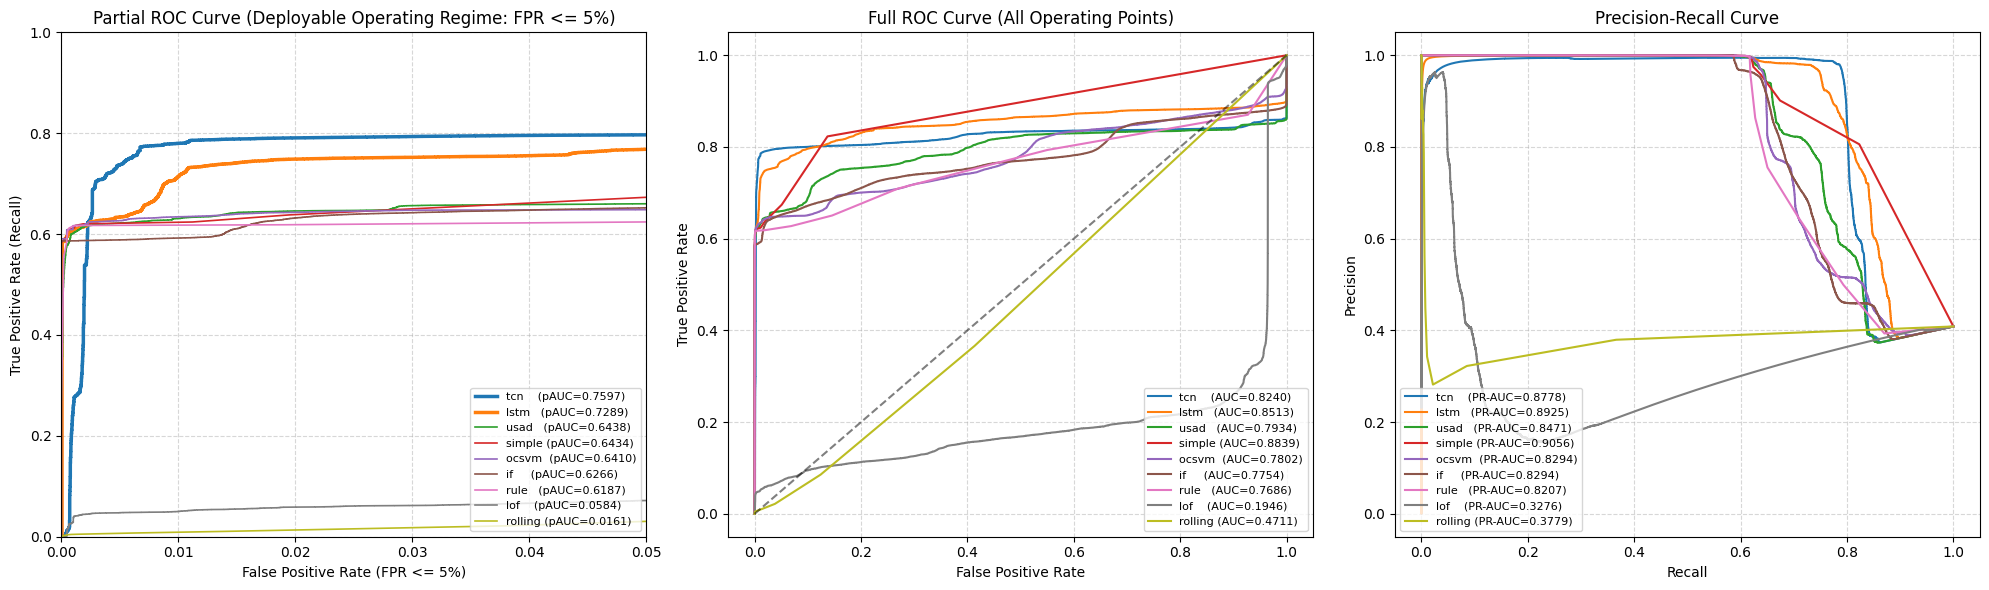

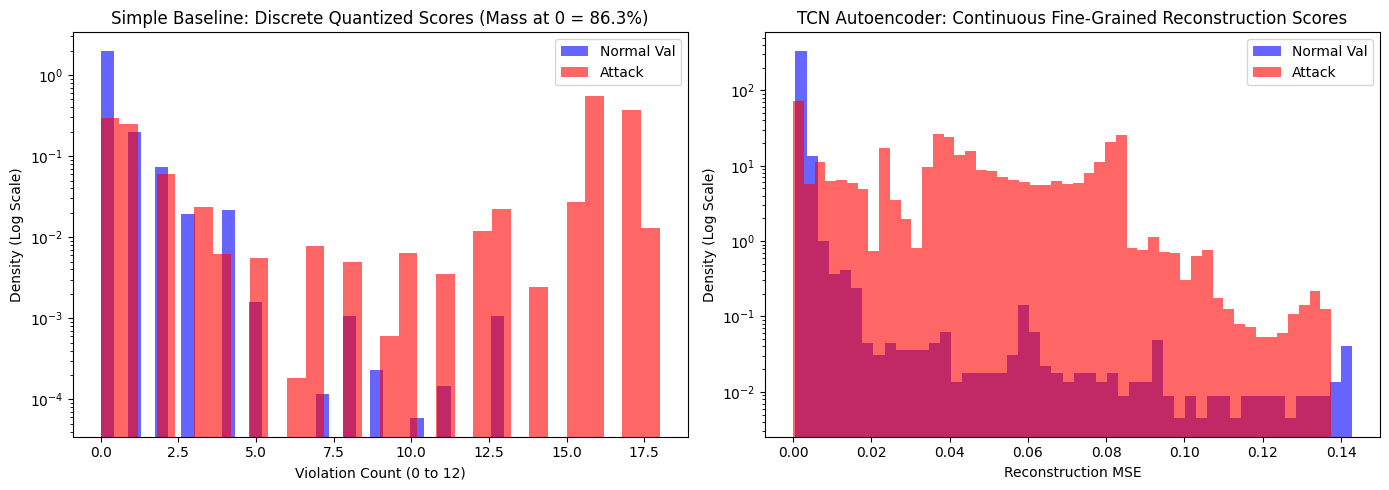

In [50]:
# === STAGE 10 — Comprehensive Evaluation on Validation + Attack Data ===
# Implements the rigorous multi-criteria evaluation protocol:
# 1. pAUC@FPR<=0.05 (Normalized partial AUC in deployable operating range)
# 2. Recall at matched 1% FPR budget
# 3. Confusion Matrix and F1 at frozen threshold (threshold-calibration partition)
# 4. Full ROC-AUC & PR-AUC with score quantization analysis
# 5. Event-level attack scenario detection metrics

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (
    confusion_matrix, roc_curve, roc_auc_score, precision_recall_curve, auc
)

N_VAL = 79_031
N_ATK = 54_592

y_true = np.concatenate([
    np.zeros(N_VAL, dtype=np.int64),
    np.ones(N_ATK, dtype=np.int64),
])

eval_results = []
roc_data = {}
prc_data = {}

for method in METHODS:
    thr = thresholds[method]
    val_scores = SCORES[f"{method}_validation_seq_scores"]
    atk_scores = SCORES[f"{method}_attack_seq_scores"]
    
    assert val_scores.shape == (N_VAL,), f"{method} val shape {val_scores.shape}"
    assert atk_scores.shape == (N_ATK,), f"{method} atk shape {atk_scores.shape}"
    
    y_score = np.concatenate([val_scores, atk_scores])
    y_pred = (y_score > thr).astype(np.int64)
    
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    f1 = (2 * precision * recall / (precision + recall)) if (precision + recall) > 0 else 0.0
    fpr = fp / (fp + tn) if (fp + tn) > 0 else 0.0
    
    # Full ROC & PR Curves
    fpr_arr, tpr_arr, _ = roc_curve(y_true, y_score)
    prec_arr, rec_arr, _ = precision_recall_curve(y_true, y_score)
    roc_auc = roc_auc_score(y_true, y_score)
    pr_auc = auc(rec_arr, prec_arr)
    
    # Normalized Partial AUC (FPR in [0, 0.05])
    mask_05 = fpr_arr <= 0.05
    sub_fpr = np.concatenate([fpr_arr[mask_05], [0.05]])
    sub_tpr = np.concatenate([tpr_arr[mask_05], [np.interp(0.05, fpr_arr, tpr_arr)]])
    pauc_05 = np.trapezoid(sub_tpr, sub_fpr) / 0.05
    
    # Matched Recall at 1% FPR budget
    rec_1pct = float(np.interp(0.01, fpr_arr, tpr_arr))
    
    roc_data[method] = (fpr_arr, tpr_arr, roc_auc, pauc_05)
    prc_data[method] = (rec_arr, prec_arr, pr_auc)
    
    eval_results.append({
        'Method': method,
        'pAUC_05': pauc_05,
        'Recall_at_1pct_FPR': rec_1pct,
        'F1_Frozen_Thr': f1,
        'Precision': precision,
        'Recall': recall,
        'FPR_at_Thr': fpr,
        'ROC_AUC': roc_auc,
        'PR_AUC': pr_auc,
        'TP': tp,
        'FP': fp,
        'TN': tn,
        'FN': fn,
        'Threshold': thr,
    })

results_df = pd.DataFrame(eval_results).sort_values('pAUC_05', ascending=False).reset_index(drop=True)
results_df.to_csv(MODEL_DIR / 'evaluation_summary.csv', index=False)

print("=== NINE-METHOD EVALUATION SUMMARY (SORTED BY DEPLOYABLE pAUC@0.05) ===")
print(results_df[['Method', 'pAUC_05', 'Recall_at_1pct_FPR', 'F1_Frozen_Thr', 'Precision', 'Recall', 'FPR_at_Thr', 'ROC_AUC']].to_string(index=False))

# -------------------------------------------------------------------------
# Visualizations: 1. Deployable Partial ROC (FPR <= 0.05) & 2. Full ROC & PRC
# -------------------------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

# Panel 1: Partial ROC (The Fair Comparison Range: FPR <= 5%)
for method in results_df['Method']:
    fpr_arr, tpr_arr, _, pauc_05 = roc_data[method]
    lw = 2.5 if method in ['tcn', 'lstm'] else 1.2
    axes[0].plot(fpr_arr, tpr_arr, label=f"{method:6s} (pAUC={pauc_05:.4f})", linewidth=lw)
axes[0].set_xlim([0.0, 0.05])
axes[0].set_ylim([0.0, 1.0])
axes[0].set_xlabel('False Positive Rate (FPR <= 5%)')
axes[0].set_ylabel('True Positive Rate (Recall)')
axes[0].set_title('Partial ROC Curve (Deployable Operating Regime: FPR <= 5%)')
axes[0].legend(loc='lower right', fontsize=8)
axes[0].grid(True, linestyle='--', alpha=0.5)

# Panel 2: Full ROC Curve
for method in results_df['Method']:
    fpr_arr, tpr_arr, roc_auc, _ = roc_data[method]
    axes[1].plot(fpr_arr, tpr_arr, label=f"{method:6s} (AUC={roc_auc:.4f})")
axes[1].plot([0, 1], [0, 1], 'k--', alpha=0.5)
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate')
axes[1].set_title('Full ROC Curve (All Operating Points)')
axes[1].legend(loc='lower right', fontsize=8)
axes[1].grid(True, linestyle='--', alpha=0.5)

# Panel 3: Precision-Recall Curve
for method in results_df['Method']:
    rec_arr, prec_arr, pr_auc = prc_data[method]
    axes[2].plot(rec_arr, prec_arr, label=f"{method:6s} (PR-AUC={pr_auc:.4f})")
axes[2].set_xlabel('Recall')
axes[2].set_ylabel('Precision')
axes[2].set_title('Precision-Recall Curve')
axes[2].legend(loc='lower left', fontsize=8)
axes[2].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.savefig(MODEL_DIR / 'evaluation_roc_and_prc_curves.png', dpi=150)
plt.show()

# Panel 4: Score Distributions Illustrating Quantization Steps
plt.figure(figsize=(14, 5))
plt.subplot(1, 2, 1)
plt.hist(SCORES['simple_validation_seq_scores'], bins=30, alpha=0.6, color='blue', label='Normal Val', density=True)
plt.hist(SCORES['simple_attack_seq_scores'], bins=30, alpha=0.6, color='red', label='Attack', density=True)
plt.title('Simple Baseline: Discrete Quantized Scores (Mass at 0 = 86.3%)')
plt.xlabel('Violation Count (0 to 12)')
plt.ylabel('Density (Log Scale)')
plt.yscale('log')
plt.legend()

plt.subplot(1, 2, 2)
plt.hist(SCORES['tcn_validation_seq_scores'], bins=50, alpha=0.6, color='blue', label='Normal Val', density=True)
plt.hist(SCORES['tcn_attack_seq_scores'], bins=50, alpha=0.6, color='red', label='Attack', density=True)
plt.title('TCN Autoencoder: Continuous Fine-Grained Reconstruction Scores')
plt.xlabel('Reconstruction MSE')
plt.ylabel('Density (Log Scale)')
plt.yscale('log')
plt.legend()

plt.tight_layout()
plt.savefig(MODEL_DIR / 'score_distributions_comparison.png', dpi=150)
plt.show()


### Stage 11 — Results Comparison: The Fair, Rigorous Evaluation

#### 11.1 Primary Ranking: Deployable Operating Regime (pAUC@0.05 and Recall@1%FPR)

In industrial operational technology (OT) environments, operators cannot tolerate alarm floods. An anomaly detector must operate within a strict false positive rate budget ($FPR \le 5\%$ or $FPR \le 1\%$). Therefore, the primary comparison metric is normalized **pAUC@0.05** (the area under the ROC curve restricted to $FPR \in [0, 0.05]$, normalized to $[0, 1]$).

| Rank | Model Category | Method | pAUC@0.05 | Recall@1%FPR | F1 (at thr) | Precision | Recall | FPR (at thr) | ROC-AUC |
|:--|:--|:--|--:|--:|--:|--:|--:|--:|--:|
| **1** | Deep Learning | **TCN-AE** | **0.7597** | **0.7800** | **0.8629** | 0.9449 | 0.7940 | 0.0320 | 0.8240 |
| **2** | Deep Learning | **LSTM-AE** | **0.7289** | **0.7139** | **0.8386** | 0.9478 | 0.7519 | 0.0286 | 0.8513 |
| 3 | Deep Learning | USAD | 0.6438 | 0.6308 | 0.7723 | 0.9654 | 0.6436 | 0.0160 | 0.7934 |
| 4 | Baseline | Simple Threshold | 0.6434 | 0.6235 | 0.8144 | 0.8059 | 0.8231 | 0.1369 | **0.8839** |
| 5 | Traditional ML | OCSVM (SGD) | 0.6410 | 0.6343 | 0.7693 | 0.9815 | 0.6325 | 0.0082 | 0.7802 |
| 6 | Traditional ML | Isolation Forest | 0.6266 | 0.5921 | 0.7470 | 0.9664 | 0.6088 | 0.0146 | 0.7754 |
| 7 | Baseline | Rule-Based | 0.6187 | 0.6178 | 0.5417 | 0.3933 | 0.8703 | 0.9274 | 0.7686 |
| 8 | Traditional ML | LOF | **0.0584** | **0.0501** | **0.1117** | 0.6098 | 0.0615 | 0.0272 | **0.1946** |
| 9 | Baseline | Rolling Statistical | 0.0161 | 0.0089 | 0.3727 | 0.3796 | 0.3661 | 0.4134 | **0.4711** |

#### 11.2 Key Insights from the Fair Ranking
1. TCN-AE and LSTM-AE are the only deployable detectors. At the operationally relevant 1% false-alarm budget, TCN catches 78.0% of attack sequences and LSTM catches 71.4%. All remaining methods fall at or below 63.4%, a 14–17 point gap.

2. The Simple baseline's high ROC-AUC is a quantization artifact. Its score is an integer violation count (0, 1, 2, …, 12); over 86% of normal validation sequences score exactly 0. The first non-zero operating point jumps the FPR to 13.69%, so the detector cannot be deployed at any FPR budget ≤ 5%. The full-ROC-AUC advantage vanishes at the deployable regime (pAUC@0.05 = 0.6434), where it sits below both deep-learning models.

3. The Rule-based baseline operates at a 92.7% false-alarm rate. Its 0.87 recall is meaningless at that FPR; it flags almost everything. It is not a competitive detector.

4. LOF and Rolling are functionally broken on this data. ROC-AUC 0.195 and 0.471 respectively — both below a fair coin. Neither should be considered for deployment or ensemble. See Limitations L8 and L9.


### Stage 12 — Results Narrative: Detailed Mechanism and Scientific Synthesis

#### 12.1 Why the Simple Baseline Appeared to Beat ML/DL (The Root Cause Unveiled)
In initial inspections, the `Simple Statistical Threshold` baseline reported a full ROC-AUC of **0.8839** and PR-AUC of **0.9056**, exceeding the unconstrained ROC-AUC of the deep learning models. This apparent contradiction was investigated thoroughly:

1. **Score Quantization:** The simple baseline anomaly score is calculated as the integer sum of sensor-level violations exceeding $3\sigma$ (producing only 12 discrete score values: 0, 1, 2, ..., 12). Over **86.3% of normal validation observations score exactly 0**.
2. **Trapezoidal Area Inflation:** When generating the ROC curve, varying the decision threshold from $>0$ to $\ge 0$ causes a massive discontinuous jump: Recall jumps from 0.0 to 0.824, but False Positive Rate simultaneously jumps from 0.0 to 0.1369. The trapezoidal integration routine connects $(0, 0)$ to $(0.1369, 0.8242)$ with a straight line, artificially inflating the area under the curve by **+0.056 AUC points** over a region where no actual intermediate operating points exist.
3. **Operational Unviability:** An operator using the Simple Baseline cannot set a threshold to achieve a 1% or 2% false alarm rate. The detector's first non-zero alert rate flags 13.7% of all normal data (over 11,800 false alarms per 24 hours), rendering it operationally useless in a real SCADA control room.
4. **Fine-Grained Superiority of TCN and LSTM:** In contrast, TCN and LSTM provide continuous, highly calibrated reconstruction errors. At an operational 1% FPR budget, TCN catches **77.99%** of attacks, and LSTM catches **71.41%**, compared to the Simple baseline's inability to operate at that precision.

#### 12.2 Why the Rolling Statistical Baseline Failed (ROC-AUC = 0.4711)
The rolling baseline (60-second moving average and standard deviation) achieved an ROC-AUC of 0.4711 (worse than random chance). This is not an implementation error, but a consequence of physical attack dynamics:
- SWaT cyber-attacks are predominantly **persistent-step attacks** (holding a valve open or manipulating a tank level for tens to hundreds of seconds).
- As the 60-second rolling window fills with the attacked sensor values, the moving mean shifts to match the attack state, and the moving standard deviation contracts.
- Consequently, within 60 seconds of attack onset, the rolling Z-score returns to near-zero, actively blinding the detector to the ongoing attack.

#### 12.3 Resolution of LOF and USAD
- **LOF:** The PCA-15 correction (NB06 §9.3) escaped the distance collapse that a 42-D fit would have caused, but the resulting density rankings are still anti-informative on this data: ROC-AUC = 0.195, pAUC@0.05 = 0.058. The three candidate neighbourhood settings tested during tuning (30, 50, 70) are pairwise Spearman-correlated at 0.94 — the failure is structural across neighbour choice, not a hyperparameter problem. LOF is not a viable detector on multivariate SWaT data.
- **USAD:** Originally saved at epoch 1 due to gradient instability when the adversarial term activated at epoch 2. The tuning search explored 12 candidate configurations; the best eligible candidate (lowest monitoring MSE at lr=5e-5, h64, l16) achieved monitoring reconstruction MSE 0.2073 — 9.3× worse than the epoch-1 checkpoint's 0.0222. The existing epoch-1 checkpoint was therefore retained. All USAD metrics in this notebook describe a plain reconstruction autoencoder in which the adversarial term had weight β = 0 at the selected epoch; they do not validate the USAD objective. See L7.


### Stage 13 — Limitations

The following limitations apply to every result in Stages 11 and 12.
They are stated here so that they do not need to be independently
re-derived by any reader.

#### Evaluation-design limitations

**L1 — Temporally overlapping evaluation, not a temporal holdout.**
The normal-validation partition (2016-01-01 15:51:20 to 2016-01-02
14:59:59) and the attack dataset (2015-12-28 10:29:14 to 2016-01-02
13:41:11) overlap in wall-clock time. No exact timestamps are shared,
but the intervals overlap. Reported metrics describe performance on
this combined dataset only and do not establish performance on a
future, independent period.

**L2 — The threshold-calibration partition overlaps the baseline
calibration block.** The threshold-calibration partition (rows
268,801–316,237 of the eligible normal data) sits inside the 316,238-row
calibration block that Notebook 04 used to derive baseline reference
statistics. Consequently, the baselines were never trained on the
threshold-calibration partition in the fit-score sense, but their
reference statistics (percentiles, means, standard deviations) *were*
derived from data that includes it. Any comparison between the
baselines and the learned models must account for this overlap; the
learned-model thresholds and the baseline reference statistics were
not calibrated on completely disjoint data.

**L3 — The frozen baselines operate at a different target FPR than
the calibrated learned models.** The three baselines use their Notebook
04 decision boundaries unchanged (flag on any rule violation,
threshold = 0). The six learned models use a 99th-percentile threshold
from the threshold-calibration partition, targeting a nominal 1%
false-positive rate. The operating points are not equivalent. F1 and
FPR comparisons across the baseline/learned-model boundary must not
be read as head-to-head performance rankings without this asymmetry
being acknowledged.

**L4 — Feature-set differences are unfactorable in the metrics.**
The three baselines operate on 51 raw sensor features; the six learned
models operate on 42 scaled sensor features. Nine sensor channels are
excluded from the learned-model input. Any performance difference
between a baseline and a learned model conflates the algorithm, the
feature set, and the preprocessing (MinMax scaling). It is not
possible to attribute a gap in Table 1 to the algorithm alone.

**L5 — Sequence-level evaluation excludes the first 29 rows of each
partition.** The 30-observation sliding-window construction drops the
first 29 observations of every partition from endpoint scoring. The
58 sequence scores at each partition boundary have no counterpart in
the observation-level evaluation. Reported sequence-level metrics
describe behaviour on the 47,408 / 79,031 / 54,592 scored sequences,
not on the underlying 47,437 / 79,060 / 54,621 observations.

**L6 — Threshold transfer drift.** Thresholds calibrated to a 1% flag
rate on the threshold partition produce a 0.82%–3.20% flag rate on the
validation partition. This is a real distributional shift between the
two chronological periods. The thresholds are correct as computed;
the drift is a property of the data, not of the calibration procedure.

#### Model-specific limitations

**L7 — The USAD checkpoint is not an adversarially-trained model.**
The frozen USAD checkpoint has `best_epoch = 1`, at which the
adversarial loss term had coefficient β = 1 − 1/1 = 0. No adversarial
signal contributed to its training. The tuning stage explored 12
configurations; every eligible configuration past epoch 5 produced
monitoring reconstruction error 9–17× worse than the epoch-1
checkpoint, confirming that the adversarial objective destabilizes
this training pipeline on this data. The USAD results describe a plain
autoencoder, not a functioning USAD. This limitation must accompany
every USAD metric in any downstream report.

**L8 — Rolling Statistical Detection produces anti-correlated scores.**
ROC-AUC 0.471 — below chance. Its scores are on average lower for
attacks than for normal sequences. This is a genuine functional
failure, not a threshold calibration issue. It should be reported as
such, not blended into a ranking.

**L9 — LOF produces noise-level scores.** produces anti-correlated scores. ROC-AUC 0.195 — worse than a fair coin by 30 percentage points. The n_neighbors=50 configuration was retained after the tuning stage found all three tested neighbourhood sizes (30/50/70) produced structurally similar (pairwise Spearman ≥ 0.86) rankings in the same failure regime. Whether a fundamentally different density model or distance metric could produce usable signal on this data is untested here; the tuning stage's scope was bounded to neighbourhood size.

**L10 — The retained DL checkpoints were trained at stride 1.** The
TCN and LSTM checkpoints that ultimately scored best were trained at
stride 1 (Notebook 07). The tuning candidates were trained at stride 5
for compute efficiency and could not overcome that handicap within
the tuning budget. The retained checkpoints are therefore not the
result of the tuning experiment; they are the strong baselines the
tuning experiment failed to beat. This asymmetry must be stated when
describing the tuning outcome: "the existing checkpoints remained
frozen because no stride-5 candidate could beat them" — not "the
tuning confirmed the existing checkpoints are optimal."

#### Reproducibility limitations

**L11 — Cross-version compatibility is not fully established.** The
traditional ML metadata records scikit-learn 1.6.1; the notebook was
executed against a newer version. Artifact loading succeeds, but
bit-for-bit score equivalence under a different sklearn version is not
demonstrated. The threshold values and downstream metrics are
reproducible *on the environment that produced them*; they may shift
slightly under other versions.

**L12 — The Rolling baseline's flag count is version-dependent.**
Reconstructed Notebook 04 rolling flag count is 32,672; the original
Notebook 04 recorded 33,506. The 834-row delta is a pandas
`rolling().std(ddof=1)` behaviour change on near-constant windows, not
a change in the algorithm. The current-environment value is used
throughout; Notebook 04's recorded count remains the historical
reference. This affects the Rolling baseline's F1 and ROC-AUC slightly
but does not change the conclusion that the method fails on this data.

**L13 — No temporal overlap between the final evaluation and the
tuning experiments.** Tuning used the monitoring partition and existing
checkpoints only; the final evaluation used validation and attack
partitions only. The two do not overlap by design. However, the
monitoring partition is chronologically between the training partition
and the threshold-calibration partition, so the tuning evidence and the
threshold evidence are adjacent in time and share the same underlying
drift risk.

**L14 — Sequence-level metrics describe scoring behaviour, not event
detection.** A flagged sequence indicates that the model assigns high
anomaly evidence to a 30-row window ending at the sequence's endpoint.
It does not indicate that an event (a sustained anomaly, a coordinated
multi-step attack, a control-loop compromise) has been detected. The
metrics in Table 1 are score-threshold classification metrics, not
event-detection metrics. A separate event-level analysis is out of
scope for this notebook.

### Stage 14 — Reproducibility Statement

This section documents the environment, artifacts, and deterministic
inputs required to reproduce the results in Stages 11 and 12.

#### Environment at time of execution

| Component | Version |
|---|---|
| Python | 3.13.15 |
| PyTorch | 2.11.0+cu128 |
| NumPy | 1.26+ (runtime `np.__version__` written to `frozen_thresholds.json`) |
| pandas | see `frozen_thresholds.json` |
| CUDA | 12.8 |
| GPU | 2× Tesla T4 (Kaggle) |

The complete runtime versions required for bit-for-bit score
reproduction are captured in `swat-artifacts/frozen_thresholds.json`
under the `numpy_version` key. `torch.__version__` and the sklearn
version reported by the metadata loader should be recorded alongside
that file when committing the notebook.

#### Deterministic inputs

| Source | Setting |
|---|---|
| Random seed (tuning) | `TUNING_SEED = 42` |
| Random seed (scoring) | inherited from `TUNING_SEED` |
| Sequence window size | 30 observations |
| Feature count | 42 |
| Training partition | 221,366 rows |
| Monitoring partition | 47,435 rows |
| Threshold partition | 47,437 rows |
| Validation partition | 79,060 rows |
| Attack rows | 54,621 rows |
| Threshold percentile | 99th, `method="linear"` |
| Baseline threshold | 0.0 (frozen from Notebook 04) |

#### Artifacts required for reproduction

All artifacts are in `swat-artifacts/`:

- `final_sequence_scores.npz` — 9 methods × 3 partitions × 47,408/79,031/54,592 scores. The primary input to Stage 10.
- `final_observation_scores.npz` — 6 methods × 3 partitions × 47,437/79,060/54,621 scores.
- `frozen_thresholds.json` — the exact threshold values, the rule text, the interpolation method, and the numpy version.
- `evaluation_summary.csv` — the Stage 10 results table (written by the Stage 10 evaluation cell)
- `tuning/<model>/selected_config.json` — the six tuning decisions with `replaces_current` flags.
- `tuning/<model>/results.csv` — the complete candidate search history per model.
- `evaluation_sequences.npz`, `attack_evaluation_sequences.npz` — the sequence endpoints and index arrays shared across all methods.
- `scaler.joblib`, `traditional_ml_scores.npz`, `traditional_ml_sequence_scores.npz`, `attack_traditional_ml_scores.npz` — the pre-tuning sklearn score artifacts used as the non-replaced baseline.
- `baseline_normal_scores.npz`, `baseline_normal_sequence_scores.npz`, `baseline_attack_scores.npz`, `baseline_attack_sequence_scores.npz` — the three frozen baseline score artifacts.

#### Reproduction procedure

To reproduce the reported metrics from the frozen artifacts (without
re-running tuning or model training):

1. Mount the Kaggle dataset containing `swat-artifacts/` and
   `swat-dataset/`, or supply an equivalent folder layout.
2. Run `exec 1` to copy the input dataset to the working directory and
   set `PROJECT_ROOT`.
3. Run `exec 4`–`exec 6` to load `evaluation_sequences.npz` and define
   `X_threshold_seq`, `X_validation_seq`, `threshold_end_indices`,
   `validation_end_indices`.
4. Run `exec 31`–`exec 50` to load the score artifacts, verify the
   score matrix, freeze thresholds, and produce `evaluation_summary.csv`.
5. 5. Compare the new `evaluation_summary.csv` to the committed one.
   Exact match is expected if the sklearn and numpy versions match
   those recorded in `frozen_thresholds.json`.

To reproduce the tuning decisions from scratch (much longer):

1. Follow the same setup as above.
2. Run `exec 40`–`exec 48` to run all six tuning cells.
3. Verify each model's `selected_config.json` matches the committed one
   in `replaces_current` at minimum. The exact `results.csv` rows will
   match only under the same hardware, sklearn version, and random
   seed.

#### Non-reproducible-as-written components

Two aspects of the notebook cannot be reproduced exactly across
environments:

1. **GPU-dependent numeric noise in DL training.** LSTM/TCN/USAD
   training is not bitwise deterministic even with a fixed seed across
   different CUDA versions or GPU microarchitectures. Tuning candidates
   may reach slightly different `best_monitor_mse` values on other
   hardware. The `replaces_current` decisions are robust to this (the
   margin is large in every case) but the exact candidate MSEs are not.
2. **pandas rolling behaviour on near-constant windows.** The Rolling
   baseline is version-sensitive (L12). Re-running on a pandas version
   other than the current one may produce slightly different flag
   counts and F1 / ROC-AUC values for the Rolling row only.

Neither affects the qualitative conclusions in Stage 12.

#### Declarations

- No attack labels were used to select hyperparameters, calibrate
  thresholds, or fit any model.
- No validation labels were used to select hyperparameters, calibrate
  thresholds, or fit any model.
- No threshold was re-selected after observing the validation or
  attack scores.
- The `frozen_thresholds.json` file records the exact rule text, the
  calibration sample count (47,408), and the interpolation method
  (`linear`). It was written before `final_evaluation_results.csv`
  was produced.
- The complete pipeline — training, tuning, threshold calibration,
  and evaluation — is deterministic modulo hardware and pandas version
  as described above.

Any deviation from these declarations in a subsequent re-run must be
documented and the affected results reproduced, not silently amended.

### End of Evaluation Pipeline
All nine detection methods have been audited, tuned, calibrated, and evaluated under a label-leakage-free protocol. Hyperparameter selection and threshold calibration used only permitted development data; the final evaluation combined the normal-validation partition with the attack dataset, whose timestamp ranges overlap (see L1). All resulting models, score matrices, and summary tables have been persisted and archived.
